<a href="https://colab.research.google.com/github/TarodinoAugusto/ZINC-Paraziquantel-similarity-search/blob/main/tcc_pipeline_v2_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TCC — Pipeline QSAR v2 (TGR e smHDAC8 · *Schistosoma mansoni*)

Versão corrigida do pipeline. O que muda em relação à v1:

1. **Valores censurados** (`IC50 > 30 µM`) deixam de ser tratados como medidas exatas: a regressão usa só `=`; a classificação usa censurados apenas quando o rótulo é inequívoco.
2. **Duplicatas após a padronização** são fundidas (mediana) e réplicas discordantes (> 1 unidade log) são descartadas.
3. **Seleção de variáveis e ajuste do PLS dentro da validação cruzada** (sem vazamento de informação).
4. **Validação por cluster (Butina)** além do 10-fold aleatório: mede o desempenho em química nova, que é o que a triagem exige.
5. **Descritores 3D** (PMI, NPR, raio de giro…) comparados por ablação com fingerprints 2D e descritores RDKit (cumpre o "QSAR 3D" da proposta).
6. **Classificação ativo/inativo (pIC50 ≥ 6)**: testa diretamente as hipóteses H1 e H2.
7. **Y-scrambling** e **domínio de aplicabilidade** (Tanimoto ao conjunto de treino).
8. **Triagem ZINC** com domínio de aplicabilidade, PAINS/Brenk e filtro de grupo de ligação ao zinco (HDAC8).

Execute de cima para baixo (*Ambiente de execução → Executar tudo*). Tempo típico no Colab gratuito: 30–45 min (use `FAST_MODE = True` na célula de parâmetros para um teste rápido).

In [2]:
%pip install -q rdkit chembl_webresource_client scikit-learn pandas numpy matplotlib scipy joblib tqdm

In [3]:
import os, glob, json, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import spearmanr
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors, MACCSkeys, AllChem, Descriptors3D
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
from rdkit.ML.Cluster import Butina

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.model_selection import (KFold, StratifiedKFold, GroupKFold, StratifiedGroupKFold,
                                     GridSearchCV, cross_val_predict)
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, roc_auc_score,
                             average_precision_score, matthews_corrcoef, balanced_accuracy_score,
                             roc_curve, precision_recall_curve)

RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings('ignore')

# ---------------- parâmetros do estudo ----------------
SEED = 42
TARGETS = {'TGR': 'CHEMBL6110', 'smHDAC8': 'CHEMBL3797017'}
THR_NM = 1000.0            # ativo = IC50 <= 1 µM (pIC50 >= 6), como na hipótese H1
PIC50_THR = 6.0
MAX_REPLICATE_RANGE = 1.0  # descarta estruturas com réplicas discordantes (> 1 log)
AD_THR = 0.40              # domínio de aplicabilidade: Tanimoto máx. (ECFP4) ao treino
AD_FLOOR = 0.30            # abaixo disto a previsão não é nem calculada na triagem
MIN_R2_VIABLE = 0.30       # modelo viável se R² por cluster >= 0,30 ...
MIN_RHO_VIABLE = 0.50      # ... OU Spearman por cluster >= 0,50 (poder de ranqueamento, o que a triagem usa)
MIN_AUC_VIABLE = 0.65      # AUC por cluster mínima para usar o classificador na triagem
N_PERM = 20                # permutações do Y-scrambling
FAST_MODE = False          # True = 2-3x mais rápido (menos árvores/iterações); use só para testar
N_TREES = 100 if FAST_MODE else 300
N_ITER = 80 if FAST_MODE else 200

for d in ['data', 'figuras', 'tabelas', 'models', 'zinc_libs']:
    os.makedirs(d, exist_ok=True)
print('Ambiente pronto.')

Ambiente pronto.


## 1. Coleta no ChEMBL e auditoria de censura

Se o arquivo `data/<alvo>/<alvo>_raw_activities.csv` já existir (runtime antigo), ele é reutilizado; caso contrário, baixa do ChEMBL.
A auditoria mostra quantos registros são censurados (`>`/`<`) e quais valores se repetem (patamares de ensaio).

In [4]:
from chembl_webresource_client.new_client import new_client

def load_raw(nome, chembl_id):
    os.makedirs(f'data/{nome}', exist_ok=True)
    path = f'data/{nome}/{nome}_raw_activities.csv'
    if os.path.exists(path):
        df = pd.read_csv(path)
        if 'standard_relation' in df.columns:
            return df
    res = new_client.activity.filter(target_chembl_id=chembl_id).filter(standard_type='IC50')
    df = pd.DataFrame.from_dict(res)
    df.to_csv(path, index=False)
    return df

RAW = {n: load_raw(n, t) for n, t in TARGETS.items()}
for n, df in RAW.items():
    print(f'== {n}: {len(df)} registros IC50')
    print('   relação (standard_relation):', df['standard_relation'].value_counts(dropna=False).to_dict())
    print('   unidades:', df['standard_units'].value_counts(dropna=False).to_dict())
    rep = pd.to_numeric(df['standard_value'], errors='coerce').value_counts().head(3)
    print('   valores mais repetidos (nM):', {float(k): int(v) for k, v in rep.items()})

== TGR: 59 registros IC50
   relação (standard_relation): {'=': 52, '>': 6, None: 1}
   unidades: {'nM': 58, None: 1}
   valores mais repetidos (nM): {50000.0: 7, 3500.0: 4, 2800.0: 3}
== smHDAC8: 260 registros IC50
   relação (standard_relation): {'=': 152, '>': 106, None: 2}
   unidades: {'nM': 258, None: 2}
   valores mais repetidos (nM): {30000.0: 106, 330.0: 4, 450.0: 3}


### 1b. (Opcional) Inventário de alvos de *Schistosoma* no ChEMBL

Responde duas perguntas: existe alvo de *S. haematobium* com dados de IC50 (lacuna da proposta)? Há ortólogos de TGR/HDAC8 em outras espécies para ampliar o conjunto?

In [5]:
def inventario(organismos=('Schistosoma mansoni', 'Schistosoma haematobium', 'Schistosoma japonicum')):
    rows = []
    for org in organismos:
        for t in new_client.target.search(org):
            if t.get('target_type') != 'SINGLE PROTEIN' or t.get('organism') != org:
                continue
            tid = t['target_chembl_id']
            try:
                n_ic50 = len(new_client.activity.filter(target_chembl_id=tid).filter(standard_type='IC50'))
            except Exception:
                n_ic50 = np.nan
            rows.append({'organismo': org, 'target_chembl_id': tid, 'alvo': t.get('pref_name'), 'n_IC50': n_ic50})
    return pd.DataFrame(rows).sort_values(['organismo', 'n_IC50'], ascending=[True, False])

INV = inventario()
print(INV.to_string(index=False))
INV.to_csv('tabelas/inventario_alvos_schistosoma.csv', index=False)

            organismo target_chembl_id                                                  alvo  n_IC50
Schistosoma japonicum    CHEMBL4105850                             Glutathione-S-transferase     111
  Schistosoma mansoni    CHEMBL3797017                                 Histone deacetylase 8     260
  Schistosoma mansoni       CHEMBL6110                     Thioredoxin glutathione reductase      59
  Schistosoma mansoni    CHEMBL4523950 Dihydroorotate dehydrogenase (quinone), mitochondrial      32
  Schistosoma mansoni    CHEMBL4523517                     NAD-dependent protein deacetylase      19
  Schistosoma mansoni    CHEMBL5169215                               Venus kinase receptor 2       3
  Schistosoma mansoni    CHEMBL4879549                              ATP-diphosphohydrolase 1       2
  Schistosoma mansoni    CHEMBL1293279                                Thioredoxin peroxidase       0
  Schistosoma mansoni    CHEMBL2363079      Voltage-activated calcium channel beta 1 subuni

## 2. Curadoria dos dados

- Padronização estrutural (maior fragmento, tautômero canônico, neutralização).
- **Regressão:** apenas valores exatos (`=`); medianas por estrutura padronizada; réplicas discordantes removidas.
- **Classificação (ativo = IC50 ≤ 1 µM):** inclui censurados quando o rótulo é inequívoco (`> X` com X ≥ 1 µM → inativo; `< X` com X ≤ 1 µM → ativo).
- O **funil** gerado é a tabela de curadoria para o capítulo de Métodos/Resultados.

In [6]:
_FRAG = rdMolStandardize.LargestFragmentChooser()
_UNCH = rdMolStandardize.Uncharger()
_TAUT = rdMolStandardize.TautomerEnumerator()

def standardize(smi):
    try:
        m = Chem.MolFromSmiles(smi)
        if m is None:
            return None
        m = _FRAG.choose(m)
        m = _TAUT.Canonicalize(m)
        m = _UNCH.uncharge(m)
        return Chem.MolToSmiles(m)
    except Exception:
        return None

def label_active(rel, v, thr=THR_NM):
    if rel == '=':
        return float(v <= thr)
    if rel in ('<', '<='):
        return 1.0 if v <= thr else np.nan
    if rel in ('>', '>='):
        return 0.0 if v >= thr else np.nan
    return np.nan

def curate(df):
    f = {}
    d = df.copy()
    f['1. registros IC50 brutos (ChEMBL)'] = len(d)
    d['standard_value'] = pd.to_numeric(d['standard_value'], errors='coerce')
    d['standard_relation'] = d['standard_relation'].fillna('=').astype(str).str.strip().str.strip('\'"')
    d = d[(d['standard_units'] == 'nM') & (d['standard_value'] > 0) & d['canonical_smiles'].notna()].copy()
    f['2. com valor > 0, unidade nM e SMILES'] = len(d)
    d['smiles_std'] = d['canonical_smiles'].map(standardize)
    d = d[d['smiles_std'].notna()].copy()
    f['3. SMILES padronizado com sucesso'] = len(d)
    f["    dos quais censurados (relação ≠ '=')"] = int((d['standard_relation'] != '=').sum())

    # ---- regressão: só valores exatos
    ex = d[d['standard_relation'] == '='].copy()
    f["4. valores exatos ('=') — base da regressão"] = len(ex)
    ex['pIC50'] = -np.log10(ex['standard_value'] * 1e-9)
    g = ex.groupby('smiles_std').agg(pIC50=('pIC50', 'median'), pmin=('pIC50', 'min'), pmax=('pIC50', 'max'),
                                     n_rep=('pIC50', 'count'),
                                     molecule_chembl_id=('molecule_chembl_id', 'first')).reset_index()
    f['5. estruturas únicas (após padronização)'] = len(g)
    g = g[(g['pmax'] - g['pmin']) <= MAX_REPLICATE_RANGE]
    f[f'6. sem réplicas discordantes (> {MAX_REPLICATE_RANGE:g} log)'] = len(g)
    reg = g[['molecule_chembl_id', 'smiles_std', 'pIC50', 'n_rep']].reset_index(drop=True)

    # ---- classificação: exatos + censurados inequívocos
    d['label'] = [label_active(r, v) for r, v in zip(d['standard_relation'], d['standard_value'])]
    c = d[d['label'].notna()]
    cg = c.groupby('smiles_std').agg(y=('label', 'mean'), molecule_chembl_id=('molecule_chembl_id', 'first')).reset_index()
    cg = cg[cg['y'].isin([0.0, 1.0])].copy()
    cg['y'] = cg['y'].astype(int)
    f['7. classificação: estruturas com rótulo inequívoco'] = len(cg)
    f['    ativos / inativos (IC50 ≤ 1 µM)'] = f"{int(cg['y'].sum())} / {int((1 - cg['y']).sum())}"
    return {'reg': reg, 'cls': cg.reset_index(drop=True), 'funil': pd.Series(f)}

CUR = {n: curate(df) for n, df in RAW.items()}
FUNIL = pd.DataFrame({n: c['funil'] for n, c in CUR.items()})
print(FUNIL.to_string())
FUNIL.to_csv('tabelas/funil_curadoria.csv')
for n in TARGETS:
    r = CUR[n]['reg']
    print(f"\n{n} (regressão): N={len(r)} | pIC50 média={r['pIC50'].mean():.2f} dp={r['pIC50'].std():.2f} "
          f"min={r['pIC50'].min():.2f} máx={r['pIC50'].max():.2f} | ≥6: {(r['pIC50'] >= 6).sum()}")

                                                        TGR   smHDAC8
1. registros IC50 brutos (ChEMBL)                        59       260
2. com valor > 0, unidade nM e SMILES                    58       258
3. SMILES padronizado com sucesso                        58       258
    dos quais censurados (relação ≠ '=')                  6       106
4. valores exatos ('=') — base da regressão              52       152
5. estruturas únicas (após padronização)                 51       107
6. sem réplicas discordantes (> 1 log)                   51       106
7. classificação: estruturas com rótulo inequívoco       57       203
    ativos / inativos (IC50 ≤ 1 µM)                 19 / 38  74 / 129

TGR (regressão): N=51 | pIC50 média=5.78 dp=0.88 min=4.24 máx=8.00 | ≥6: 19

smHDAC8 (regressão): N=106 | pIC50 média=6.22 dp=0.68 min=4.30 máx=7.17 | ≥6: 74


## 3. Descritores moleculares

Blocos: **ECFP4** (2048 bits), **MACCS** (167), **RDKit 2D** (~200 descritores físico-químicos/topológicos), **3D** (PMI1–3, NPR1–2, raio de giro, fator de forma inercial, excentricidade, assimetria, esfericidade — calculados na conformação de menor energia MMFF entre 5 conformeros ETKDGv3) e **Lipinski** (para drug-likeness).

In [7]:
_ECFP = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
_DESC = Descriptors._descList
D3_NAMES = ['PMI1', 'PMI2', 'PMI3', 'NPR1', 'NPR2', 'RadiusOfGyration', 'InertialShapeFactor',
            'Eccentricity', 'Asphericity', 'SpherocityIndex']
_D3_FN = [Descriptors3D.PMI1, Descriptors3D.PMI2, Descriptors3D.PMI3, Descriptors3D.NPR1, Descriptors3D.NPR2,
          Descriptors3D.RadiusOfGyration, Descriptors3D.InertialShapeFactor, Descriptors3D.Eccentricity,
          Descriptors3D.Asphericity, Descriptors3D.SpherocityIndex]

def block_ecfp(mols):
    if len(mols) == 0:
        return np.zeros((0, 2048), dtype=np.uint8)
    return np.vstack([_ECFP.GetFingerprintAsNumPy(m) for m in mols]).astype(np.uint8)

def block_maccs(mols):
    return np.array([list(MACCSkeys.GenMACCSKeys(m)) for m in mols], dtype=np.uint8).reshape(len(mols), 167)

def block_rdkit2d(mols):
    names = [n for n, _ in _DESC]
    out = np.full((len(mols), len(names)), np.nan, dtype=np.float64)
    for i, m in enumerate(tqdm(mols, desc='RDKit2D', leave=False)):
        for j, (_, fn) in enumerate(_DESC):
            try:
                out[i, j] = fn(m)
            except Exception:
                pass
    out[~np.isfinite(out)] = np.nan
    return np.clip(out, -1e6, 1e6), names

def block_3d(mols, n_conf=5):
    out = np.full((len(mols), len(D3_NAMES)), np.nan, dtype=np.float64)
    for i, m in enumerate(tqdm(mols, desc='3D', leave=False)):
        try:
            mh = Chem.AddHs(m)
            p = AllChem.ETKDGv3()
            p.randomSeed = SEED
            cids = list(AllChem.EmbedMultipleConfs(mh, n_conf, p))
            if not cids:
                continue
            res = AllChem.MMFFOptimizeMoleculeConfs(mh, maxIters=500)
            en = np.array([e for _, e in res], dtype=float)
            best = int(np.argmin(en)) if len(en) == len(cids) else 0
            out[i] = [fn(mh, confId=int(cids[best])) for fn in _D3_FN]
        except Exception:
            pass
    return out, list(D3_NAMES)

PHYS_NAMES = ['MW', 'LogP', 'HBD', 'HBA', 'TPSA', 'RotB', 'AromRings', 'FracCSP3', 'HeavyAtoms']
def block_phys(mols):
    rows = [[Descriptors.MolWt(m), Descriptors.MolLogP(m), Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m),
             Descriptors.TPSA(m), Lipinski.NumRotatableBonds(m), rdMolDescriptors.CalcNumAromaticRings(m),
             rdMolDescriptors.CalcFractionCSP3(m), m.GetNumHeavyAtoms()] for m in mols]
    return np.array(rows, dtype=float).reshape(len(mols), len(PHYS_NAMES)), list(PHYS_NAMES)

def lipinski_violations(phys):
    mw, logp, hbd, hba = phys[:, 0], phys[:, 1], phys[:, 2], phys[:, 3]
    return (mw > 500).astype(int) + (logp > 5).astype(int) + (hbd > 5).astype(int) + (hba > 10).astype(int)

FEATURE_SETS = {
    'FP2D':             ['ecfp4', 'maccs'],
    'RDKIT2D':          ['rdkit2d'],
    'RDKIT2D+3D':       ['rdkit2d', 'd3'],
    'FP2D+RDKIT2D':     ['ecfp4', 'maccs', 'rdkit2d'],
    'FP2D+RDKIT2D+3D':  ['ecfp4', 'maccs', 'rdkit2d', 'd3'],
}

def featurize(mols, blocks):
    out = {}
    for b in blocks:
        if b == 'ecfp4':
            out[b] = (block_ecfp(mols), [f'ECFP4_{i}' for i in range(2048)])
        elif b == 'maccs':
            out[b] = (block_maccs(mols), [f'MACCS_{i}' for i in range(167)])
        elif b == 'rdkit2d':
            out[b] = block_rdkit2d(mols)
        elif b == 'd3':
            out[b] = block_3d(mols)
        elif b == 'phys':
            out[b] = block_phys(mols)
    return out

def assemble(blocks, setname, idx=None):
    mats, names = [], []
    for b in FEATURE_SETS[setname]:
        M, N = blocks[b]
        mats.append(np.asarray(M if idx is None else M[idx], dtype=np.float64))
        names += list(N)
    return np.hstack(mats), names

def build_features(nome):
    smi = sorted(set(CUR[nome]['reg']['smiles_std']) | set(CUR[nome]['cls']['smiles_std']))
    mols = [Chem.MolFromSmiles(s) for s in smi]
    print(f'{nome}: {len(smi)} estruturas — calculando descritores...')
    blocks = featurize(mols, ['ecfp4', 'maccs', 'rdkit2d', 'd3', 'phys'])
    falha3d = float(np.isnan(blocks['d3'][0]).all(axis=1).mean() * 100)
    print(f'   falha na geração 3D: {falha3d:.1f}% das estruturas')
    return {'smiles': smi, 'index': {s: i for i, s in enumerate(smi)}, 'blocks': blocks}

FEATS = {n: build_features(n) for n in TARGETS}

def X_for(nome, smiles, setname):
    f = FEATS[nome]
    idx = [f['index'][s] for s in smiles]
    return assemble(f['blocks'], setname, idx)

def ecfp_of(nome, smiles):
    f = FEATS[nome]
    return f['blocks']['ecfp4'][0][[f['index'][s] for s in smiles]]

# ---- Lipinski nos conjuntos de regressão (tabela para o TCC)
LIP = []
for n in TARGETS:
    reg = CUR[n]['reg']
    ph = FEATS[n]['blocks']['phys'][0][[FEATS[n]['index'][s] for s in reg['smiles_std']]]
    v = lipinski_violations(ph)
    LIP.append({'alvo': n, 'N': len(reg), '0 violações': int((v == 0).sum()), '1 violação': int((v == 1).sum()),
                '≥2 violações': int((v >= 2).sum()), 'drug-like (≤1)': f'{(v <= 1).mean() * 100:.1f}%'})
LIP = pd.DataFrame(LIP)
print(LIP.to_string(index=False))
LIP.to_csv('tabelas/lipinski_conjuntos.csv', index=False)

TGR: 57 estruturas — calculando descritores...


RDKit2D:   0%|          | 0/57 [00:00<?, ?it/s]

3D:   0%|          | 0/57 [00:00<?, ?it/s]

   falha na geração 3D: 0.0% das estruturas
smHDAC8: 204 estruturas — calculando descritores...


RDKit2D:   0%|          | 0/204 [00:00<?, ?it/s]

3D:   0%|          | 0/204 [00:00<?, ?it/s]

   falha na geração 3D: 0.0% das estruturas
   alvo   N  0 violações  1 violação  ≥2 violações drug-like (≤1)
    TGR  51           48           3             0         100.0%
smHDAC8 106           95           9             2          98.1%


## 4. Divisão treino/teste (Kennard-Stone) e grupos por cluster

- Kennard-Stone (80/20) sobre ECFP4+MACCS, como no artigo de referência (implementação própria, sem dependências extras).
- **Atenção:** o Kennard-Stone coloca os compostos mais "centrais" no teste → teste *fácil* (interpolação). Por isso o desempenho é reportado também por **validação cruzada por cluster (Butina sobre ECFP4; o corte de distância é reduzido automaticamente se a série for muito homogênea)**, que simula química nova.

In [8]:
def tanimoto_matrix(A, B=None):
    A = A.astype(np.float32)
    B = A if B is None else B.astype(np.float32)
    inter = A @ B.T
    union = A.sum(1)[:, None] + B.sum(1)[None, :] - inter
    return inter / np.maximum(union, 1)

def max_tanimoto(A, B, chunk=4000):
    return np.concatenate([tanimoto_matrix(A[i:i + chunk], B).max(axis=1) for i in range(0, len(A), chunk)])

def ks_split(X, test_frac=0.2):
    X = np.asarray(X, dtype=np.float32)
    n = len(X)
    n_train = n - int(np.ceil(test_frac * n))
    from sklearn.metrics import pairwise_distances
    D = pairwise_distances(X)
    i, j = np.unravel_index(np.argmax(D), D.shape)
    sel = [int(i), int(j)]
    mind = np.minimum(D[i], D[j])
    while len(sel) < n_train:
        mind[sel] = -1
        k = int(np.argmax(mind))
        sel.append(k)
        mind = np.minimum(mind, D[k])
    tr = np.array(sorted(sel))
    te = np.setdiff1d(np.arange(n), tr)
    return tr, te

def cluster_groups(E, cutoff=0.6, min_groups=5):
    """Butina sobre 1-Tanimoto(ECFP4). Se houver menos de `min_groups` clusters (série muito homogênea),
    reduz o corte de distância até obtê-los; em último caso usa blocos sequenciais (cutoff=None)."""
    n = len(E)
    dist = 1 - tanimoto_matrix(E)
    dl = [dist[i, j] for i in range(1, n) for j in range(i)]
    used, clusters = None, []
    for c in [cutoff, 0.5, 0.4, 0.3, 0.2, 0.1]:
        clusters = Butina.ClusterData(dl, n, c, isDistData=True)
        if len(clusters) >= min_groups:
            used = c
            break
    if used is None:
        return np.arange(n) % min_groups, None
    g = np.zeros(n, dtype=int)
    for ci, cl in enumerate(clusters):
        g[list(cl)] = ci
    return g, used

SPLIT, SPLIT_C, GROUPS, GROUPS_C, GROUP_CUT = {}, {}, {}, {}, {}
for n in TARGETS:
    for key, df, S, G in [('reg', CUR[n]['reg'], SPLIT, GROUPS), ('cls', CUR[n]['cls'], SPLIT_C, GROUPS_C)]:
        E = X_for(n, df['smiles_std'], 'FP2D')[0]
        tr, te = ks_split(E)
        S[n] = {'train': df.iloc[tr].reset_index(drop=True), 'test': df.iloc[te].reset_index(drop=True)}
        G[n], GROUP_CUT[(n, key)] = cluster_groups(ecfp_of(n, S[n]['train']['smiles_std']))
    r = SPLIT[n]
    cut = GROUP_CUT[(n, 'reg')]
    print(f"{n}: regressão treino={len(r['train'])} teste={len(r['test'])} "
          f"(pIC50 teste: média={r['test']['pIC50'].mean():.2f}, dp={r['test']['pIC50'].std():.2f} | "
          f"treino: média={r['train']['pIC50'].mean():.2f}, dp={r['train']['pIC50'].std():.2f}) "
          f"| clusters no treino={len(np.unique(GROUPS[n]))} "
          + (f"(corte de distância {cut}; Tanimoto ≥ {1 - cut:.1f} no mesmo cluster)" if cut is not None
             else "(série homogênea demais: blocos sequenciais — validação por cluster pouco informativa)"))
    c = SPLIT_C[n]
    print(f"      classificação treino={len(c['train'])} (ativos={int(c['train']['y'].sum())}) "
          f"teste={len(c['test'])} (ativos={int(c['test']['y'].sum())})")

TGR: regressão treino=40 teste=11 (pIC50 teste: média=5.35, dp=0.50 | treino: média=5.90, dp=0.93) | clusters no treino=16 (corte de distância 0.6; Tanimoto ≥ 0.4 no mesmo cluster)
      classificação treino=45 (ativos=17) teste=12 (ativos=2)
smHDAC8: regressão treino=84 teste=22 (pIC50 teste: média=6.58, dp=0.50 | treino: média=6.12, dp=0.69) | clusters no treino=25 (corte de distância 0.6; Tanimoto ≥ 0.4 no mesmo cluster)
      classificação treino=162 (ativos=55) teste=41 (ativos=19)


## 5. Modelos de regressão — ablação de descritores com validação honesta

Para cada **conjunto de descritores × algoritmo (PLS, RF, HGB)**:
- 10-fold × 3 repetições (validação aleatória, como na proposta);
- 5-fold **por cluster** (química nova).

Remoção de variáveis constantes, imputação e o ajuste de `n_components` do PLS acontecem **dentro** de cada dobra. O conjunto de descritores de cada família é escolhido pelo **R² por cluster** (critério conservador). Um modelo é **viável** para a triagem se R² por cluster ≥ 0,30 **ou** Spearman por cluster ≥ 0,50 (a triagem depende de ranqueamento).

In [9]:
def make_reg(name):
    pre = [('imp', SimpleImputer(strategy='median')), ('var', VarianceThreshold(0.0))]
    if name == 'PLS':
        pipe = Pipeline(pre + [('sc', StandardScaler()), ('pls', PLSRegression(n_components=2, scale=False))])
        return GridSearchCV(pipe, {'pls__n_components': [1, 2, 3, 4, 5, 6]},
                            cv=KFold(5, shuffle=True, random_state=SEED), scoring='neg_root_mean_squared_error')
    if name == 'RF':
        return Pipeline(pre + [('m', RandomForestRegressor(n_estimators=N_TREES, max_features=0.3, min_samples_leaf=2,
                                                           n_jobs=-1, random_state=SEED))])
    if name == 'HGB':
        return Pipeline(pre + [('m', HistGradientBoostingRegressor(max_depth=4, min_samples_leaf=3, learning_rate=0.05,
                                                                   max_iter=N_ITER, l2_regularization=1.0,
                                                                   random_state=SEED))])
    raise ValueError(name)

def cv_random(est, X, y, n_rep=3, k=10):
    return np.array([np.ravel(cross_val_predict(clone(est), X, y, cv=KFold(k, shuffle=True, random_state=SEED + r)))
                     for r in range(n_rep)])

def cv_cluster(est, X, y, groups, k=5):
    k = int(max(2, min(k, len(np.unique(groups)))))
    return np.ravel(cross_val_predict(clone(est), X, y, cv=GroupKFold(n_splits=k), groups=groups))

def ablation(nome):
    tr = SPLIT[nome]['train']
    y = tr['pIC50'].values
    rows, store = [], {}
    for fs in FEATURE_SETS:
        X, _ = X_for(nome, tr['smiles_std'], fs)
        for mn in ['PLS', 'RF', 'HGB']:
            est = make_reg(mn)
            Pr = cv_random(est, X, y)
            Pc = cv_cluster(est, X, y, GROUPS[nome])
            r2s = [r2_score(y, p) for p in Pr]
            rows.append({'alvo': nome, 'conjunto': fs, 'modelo': mn, 'n_features': X.shape[1],
                         'R2_CV10x3': np.mean(r2s), 'dp_R2': np.std(r2s),
                         'RMSE_CV10x3': np.mean([np.sqrt(mean_squared_error(y, p)) for p in Pr]),
                         'R2_CV_cluster': r2_score(y, Pc), 'RMSE_CV_cluster': np.sqrt(mean_squared_error(y, Pc)),
                         'Spearman_cluster': spearmanr(y, Pc)[0] if np.std(Pc) > 0 else np.nan})
            store[(fs, mn)] = {'rand': Pr.mean(axis=0), 'clu': Pc}
        print(f'   {nome}: {fs} ✓')
    return pd.DataFrame(rows), store

ABL, ABL_P = {}, {}
for n in TARGETS:
    print(f'Ablação {n} (N treino = {len(SPLIT[n]["train"])})')
    ABL[n], ABL_P[n] = ablation(n)
ABL_ALL = pd.concat(ABL.values(), ignore_index=True)
ABL_ALL.round(3).to_csv('tabelas/ablacao_regressao.csv', index=False)
for n in TARGETS:
    print(f'\n=== {n} — ablação (ordenada por R² por cluster) ===')
    print(ABL[n].sort_values('R2_CV_cluster', ascending=False).round(3).to_string(index=False))

Ablação TGR (N treino = 40)
   TGR: FP2D ✓
   TGR: RDKIT2D ✓
   TGR: RDKIT2D+3D ✓
   TGR: FP2D+RDKIT2D ✓
   TGR: FP2D+RDKIT2D+3D ✓
Ablação smHDAC8 (N treino = 84)
   smHDAC8: FP2D ✓
   smHDAC8: RDKIT2D ✓
   smHDAC8: RDKIT2D+3D ✓
   smHDAC8: FP2D+RDKIT2D ✓
   smHDAC8: FP2D+RDKIT2D+3D ✓

=== TGR — ablação (ordenada por R² por cluster) ===
alvo        conjunto modelo  n_features  R2_CV10x3  dp_R2  RMSE_CV10x3  R2_CV_cluster  RMSE_CV_cluster  Spearman_cluster
 TGR            FP2D     RF        2215      0.217  0.054        0.812          0.201            0.820             0.421
 TGR    FP2D+RDKIT2D     RF        2432      0.164  0.052        0.839          0.194            0.824             0.410
 TGR      RDKIT2D+3D     RF         227      0.181  0.061        0.830          0.190            0.826             0.434
 TGR FP2D+RDKIT2D+3D     RF        2442      0.186  0.068        0.827          0.187            0.827             0.410
 TGR         RDKIT2D     RF         217      0.154  0.05

### 5b. Modelos finais, teste externo e consenso

In [10]:
def reg_metrics(y, p):
    return {'R2': r2_score(y, p), 'RMSE': float(np.sqrt(mean_squared_error(y, p))), 'MAE': mean_absolute_error(y, p),
            'Spearman': spearmanr(y, p)[0] if np.std(p) > 0 else np.nan}

FINAL = {}
for n in TARGETS:
    tr, te = SPLIT[n]['train'], SPLIT[n]['test']
    ytr = tr['pIC50'].values
    FINAL[n] = {}
    for mn in ['PLS', 'RF', 'HGB']:
        row = ABL[n][ABL[n].modelo == mn].sort_values('R2_CV_cluster', ascending=False).iloc[0]
        fs = row['conjunto']
        Xtr, _ = X_for(n, tr['smiles_std'], fs)
        Xte, _ = X_for(n, te['smiles_std'], fs)
        est = make_reg(mn).fit(Xtr, ytr)
        FINAL[n][mn] = {'est': est, 'set': fs, 'pred_test': np.ravel(est.predict(Xte)),
                        'R2_CV': float(row['R2_CV10x3']), 'R2_cluster': float(row['R2_CV_cluster']),
                        'rho_cluster': float(row['Spearman_cluster']),
                        'viavel': bool(row['R2_CV_cluster'] >= MIN_R2_VIABLE or row['Spearman_cluster'] >= MIN_RHO_VIABLE)}

rows, CONS = [], {}
for n in TARGETS:
    yte, ytr = SPLIT[n]['test']['pIC50'].values, SPLIT[n]['train']['pIC50'].values
    rows.append({'alvo': n, 'modelo': 'baseline (média do treino)', 'conjunto': '-', 'R2_CV10x3': np.nan,
                 'R2_cluster': np.nan, 'viavel': '-', **reg_metrics(yte, np.full_like(yte, ytr.mean(), dtype=float))})
    for mn, d in FINAL[n].items():
        rows.append({'alvo': n, 'modelo': mn, 'conjunto': d['set'], 'R2_CV10x3': d['R2_CV'],
                     'R2_cluster': d['R2_cluster'], 'rho_cluster': d['rho_cluster'], 'viavel': d['viavel'],
                     **reg_metrics(yte, d['pred_test'])})
    P = [d['pred_test'] for d in FINAL[n].values() if d['viavel']]
    if P:
        P = np.vstack(P)
        cons = P.mean(axis=0)
        sd = P.std(axis=0, ddof=1) if len(P) > 1 else np.zeros(P.shape[1])
        CONS[n] = pd.DataFrame({'obs': yte, 'pred_mean': cons, 'pred_sd': sd, 'CV%': sd / cons * 100})
        rows.append({'alvo': n, 'modelo': f'consenso ({len(P)} modelos viáveis)', 'conjunto': '-', 'R2_CV10x3': np.nan,
                     'R2_cluster': np.nan, 'viavel': True, **reg_metrics(yte, cons)})
    else:
        rows.append({'alvo': n, 'modelo': 'consenso', 'conjunto': '-', 'R2_CV10x3': np.nan, 'R2_cluster': np.nan,
                     'viavel': False, 'R2': np.nan, 'RMSE': np.nan, 'MAE': np.nan, 'Spearman': np.nan})
TESTE = pd.DataFrame(rows)
print(TESTE.round(3).to_string(index=False))
TESTE.round(3).to_csv('tabelas/desempenho_teste_regressao.csv', index=False)
for n in TARGETS:
    if n in CONS:
        print(f"\n{n}: CV% médio entre modelos (teste) = {CONS[n]['CV%'].mean():.2f}%")
    else:
        print(f'\n{n}: NENHUM modelo atingiu R² por cluster ≥ {MIN_R2_VIABLE} nem Spearman por cluster ≥ {MIN_RHO_VIABLE} — reportar como resultado exploratório/negativo.')

   alvo                     modelo        conjunto  R2_CV10x3  R2_cluster viavel     R2  RMSE   MAE  Spearman  rho_cluster
    TGR baseline (média do treino)               -        NaN         NaN      - -1.363 0.729 0.661       NaN          NaN
    TGR                        PLS FP2D+RDKIT2D+3D     -0.048      -0.092  False  0.186 0.428 0.356     0.400        0.292
    TGR                         RF            FP2D      0.217       0.201  False  0.305 0.395 0.335     0.782        0.421
    TGR                        HGB FP2D+RDKIT2D+3D      0.003       0.134  False  0.579 0.308 0.256     0.782        0.392
    TGR                   consenso               -        NaN         NaN  False    NaN   NaN   NaN       NaN          NaN
smHDAC8 baseline (média do treino)               -        NaN         NaN      - -0.858 0.667 0.603       NaN          NaN
smHDAC8                        PLS            FP2D      0.610       0.056  False  0.622 0.300 0.252     0.401        0.200
smHDAC8         

## 6. Classificação ativo/inativo (IC50 ≤ 1 µM) — hipóteses H1 e H2

Usa todos os rótulos inequívocos (inclusive censurados). Métricas: ROC-AUC, PR-AUC (comparar com a prevalência), MCC e acurácia balanceada; validação aleatória e **por cluster**.

In [11]:
def make_cls(name):
    pre = [('imp', SimpleImputer(strategy='median')), ('var', VarianceThreshold(0.0))]
    if name == 'RF':
        return Pipeline(pre + [('m', RandomForestClassifier(n_estimators=N_TREES, max_features=0.3, min_samples_leaf=2,
                                                            class_weight='balanced_subsample', n_jobs=-1,
                                                            random_state=SEED))])
    return Pipeline(pre + [('m', HistGradientBoostingClassifier(max_depth=4, min_samples_leaf=3, learning_rate=0.05,
                                                                max_iter=N_ITER, l2_regularization=1.0,
                                                                class_weight='balanced', random_state=SEED))])

def cv_cls(est, X, y, groups=None, k=10):
    if groups is None:
        kk = int(max(2, min(k, y.sum(), (1 - y).sum())))
        cv = StratifiedKFold(kk, shuffle=True, random_state=SEED)
        P = cross_val_predict(clone(est), X, y, cv=cv, method='predict_proba')
    else:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
        P = cross_val_predict(clone(est), X, y, cv=cv, groups=groups, method='predict_proba')
    return P[:, 1]

CLS_ABL, CLS_SET, CLS_FINAL, CLS_ROWS = {}, {}, {}, []
for n in TARGETS:
    ctr, cte = SPLIT_C[n]['train'], SPLIT_C[n]['test']
    y, yt = ctr['y'].values, cte['y'].values
    rows = []
    for fs in FEATURE_SETS:
        X, _ = X_for(n, ctr['smiles_std'], fs)
        pr = cv_cls(make_cls('RF'), X, y)
        pc = cv_cls(make_cls('RF'), X, y, groups=GROUPS_C[n])
        rows.append({'alvo': n, 'conjunto': fs, 'AUC_CV': roc_auc_score(y, pr), 'PRAUC_CV': average_precision_score(y, pr),
                     'AUC_cluster': roc_auc_score(y, pc), 'PRAUC_cluster': average_precision_score(y, pc),
                     'prevalência_treino': y.mean()})
    CLS_ABL[n] = pd.DataFrame(rows)
    best = CLS_ABL[n].sort_values('AUC_cluster', ascending=False).iloc[0]
    fs = best['conjunto']
    CLS_SET[n] = fs
    Xtr, _ = X_for(n, ctr['smiles_std'], fs)
    Xte, _ = X_for(n, cte['smiles_std'], fs)
    CLS_FINAL[n] = {}
    for mn in ['RF', 'HGB']:
        est = make_cls(mn).fit(Xtr, y)
        CLS_FINAL[n][mn] = {'est': est, 'prob_test': est.predict_proba(Xte)[:, 1]}
    prob = np.mean([d['prob_test'] for d in CLS_FINAL[n].values()], axis=0)
    pred = (prob >= 0.5).astype(int)
    ok = len(np.unique(yt)) == 2
    CLS_ROWS.append({'alvo': n, 'conjunto': fs, 'AUC_cluster(CV)': best['AUC_cluster'],
                     'N_teste': len(yt), 'ativos_teste': int(yt.sum()), 'prevalência_teste': yt.mean(),
                     'AUC_teste': roc_auc_score(yt, prob) if ok else np.nan,
                     'PRAUC_teste': average_precision_score(yt, prob) if ok else np.nan,
                     'MCC_teste': matthews_corrcoef(yt, pred), 'BalAcc_teste': balanced_accuracy_score(yt, pred),
                     'viavel_para_triagem': bool(best['AUC_cluster'] >= MIN_AUC_VIABLE)})
    CLS_FINAL[n]['_prob_test'] = prob
    print(f'\n=== {n} — classificação: ablação de conjuntos (RF) ===')
    print(CLS_ABL[n].round(3).to_string(index=False))
CLS_TAB = pd.DataFrame(CLS_ROWS)
print('\n=== Classificação: desempenho no teste externo (consenso RF+HGB) ===')
print(CLS_TAB.round(3).to_string(index=False))
pd.concat(CLS_ABL.values()).round(3).to_csv('tabelas/ablacao_classificacao.csv', index=False)
CLS_TAB.round(3).to_csv('tabelas/desempenho_teste_classificacao.csv', index=False)


=== TGR — classificação: ablação de conjuntos (RF) ===
alvo        conjunto  AUC_CV  PRAUC_CV  AUC_cluster  PRAUC_cluster  prevalência_treino
 TGR            FP2D   0.746     0.695        0.548          0.418               0.378
 TGR         RDKIT2D   0.763     0.746        0.597          0.449               0.378
 TGR      RDKIT2D+3D   0.756     0.762        0.622          0.467               0.378
 TGR    FP2D+RDKIT2D   0.761     0.742        0.616          0.502               0.378
 TGR FP2D+RDKIT2D+3D   0.763     0.726        0.601          0.462               0.378

=== smHDAC8 — classificação: ablação de conjuntos (RF) ===
   alvo        conjunto  AUC_CV  PRAUC_CV  AUC_cluster  PRAUC_cluster  prevalência_treino
smHDAC8            FP2D   0.968     0.921        0.937          0.827                0.34
smHDAC8         RDKIT2D   0.974     0.954        0.904          0.728                0.34
smHDAC8      RDKIT2D+3D   0.977     0.955        0.951          0.887                0.34
sm

## 7. Y-scrambling e domínio de aplicabilidade

- **Y-scrambling:** embaralha o pIC50 do treino e repete a validação; o modelo real deve superar claramente as permutações (p empírico).
- **Domínio de aplicabilidade (AD):** Tanimoto máximo (ECFP4) de cada composto de teste ao treino; mostra como o erro cresce quando a química se afasta.

In [12]:
YS = {}
for n in TARGETS:
    best_mn = max(FINAL[n], key=lambda m: FINAL[n][m]['R2_cluster'])
    fs = FINAL[n][best_mn]['set']
    tr = SPLIT[n]['train']
    X, _ = X_for(n, tr['smiles_std'], fs)
    y = tr['pIC50'].values
    est = make_reg(best_mn)
    real = r2_score(y, cv_random(est, X, y, n_rep=1)[0])
    rng = np.random.default_rng(SEED)
    perm = []
    for _ in tqdm(range(N_PERM), desc=f'Y-scrambling {n}', leave=False):
        yp = rng.permutation(y)
        perm.append(r2_score(yp, np.ravel(cross_val_predict(clone(est), X, yp, cv=KFold(10, shuffle=True, random_state=SEED)))))
    perm = np.array(perm)
    p = (1 + int((perm >= real).sum())) / (1 + N_PERM)
    YS[n] = {'modelo': f'{best_mn} [{fs}]', 'R2_real': real, 'R2_perm_media': perm.mean(), 'R2_perm_max': perm.max(),
             'p_empirico': p, 'perm': perm}
YS_TAB = pd.DataFrame([{k: v for k, v in d.items() if k != 'perm'} | {'alvo': n} for n, d in YS.items()])
print(YS_TAB.round(3).to_string(index=False))
YS_TAB.round(3).to_csv('tabelas/y_scrambling.csv', index=False)

AD_ROWS = []
for n in TARGETS:
    tr, te = SPLIT[n]['train'], SPLIT[n]['test']
    sim = max_tanimoto(ecfp_of(n, te['smiles_std']), ecfp_of(n, tr['smiles_std']))
    p = CONS[n]['pred_mean'].values if n in CONS else max(FINAL[n].values(), key=lambda d: d['R2_cluster'])['pred_test']
    err = np.abs(te['pIC50'].values - p)
    faixa = pd.cut(sim, [0, 0.4, 0.6, 0.8, 1.01], right=False, labels=['<0,4', '0,4–0,6', '0,6–0,8', '≥0,8'])
    t = pd.DataFrame({'sim': sim, 'erro_abs': err, 'faixa': faixa}).groupby('faixa', observed=False).agg(
        n=('sim', 'size'), MAE=('erro_abs', 'mean')).reset_index()
    t.insert(0, 'alvo', n)
    AD_ROWS.append(t)
    SPLIT[n]['test_sim'] = sim
    print(f"\n{n}: similaridade máx. teste→treino: mediana={np.median(sim):.2f} | fração com sim ≥ {AD_THR}: {(sim >= AD_THR).mean():.0%}")
AD_TAB = pd.concat(AD_ROWS)
print(AD_TAB.round(3).to_string(index=False))
AD_TAB.round(3).to_csv('tabelas/dominio_aplicabilidade_teste.csv', index=False)

Y-scrambling TGR:   0%|          | 0/20 [00:00<?, ?it/s]

Y-scrambling smHDAC8:   0%|          | 0/20 [00:00<?, ?it/s]

       modelo  R2_real  R2_perm_media  R2_perm_max  p_empirico    alvo
    RF [FP2D]    0.230         -0.212        0.072       0.048     TGR
HGB [RDKIT2D]    0.688         -0.333        0.080       0.048 smHDAC8

TGR: similaridade máx. teste→treino: mediana=0.72 | fração com sim ≥ 0.4: 100%

smHDAC8: similaridade máx. teste→treino: mediana=0.80 | fração com sim ≥ 0.4: 100%
   alvo   faixa  n   MAE
    TGR    <0,4  0   NaN
    TGR 0,4–0,6  0   NaN
    TGR 0,6–0,8  9 0.348
    TGR    ≥0,8  2 0.275
smHDAC8    <0,4  0   NaN
smHDAC8 0,4–0,6  0   NaN
smHDAC8 0,6–0,8  9 0.206
smHDAC8    ≥0,8 13 0.353


## 8. Figuras para o TCC (300 dpi)

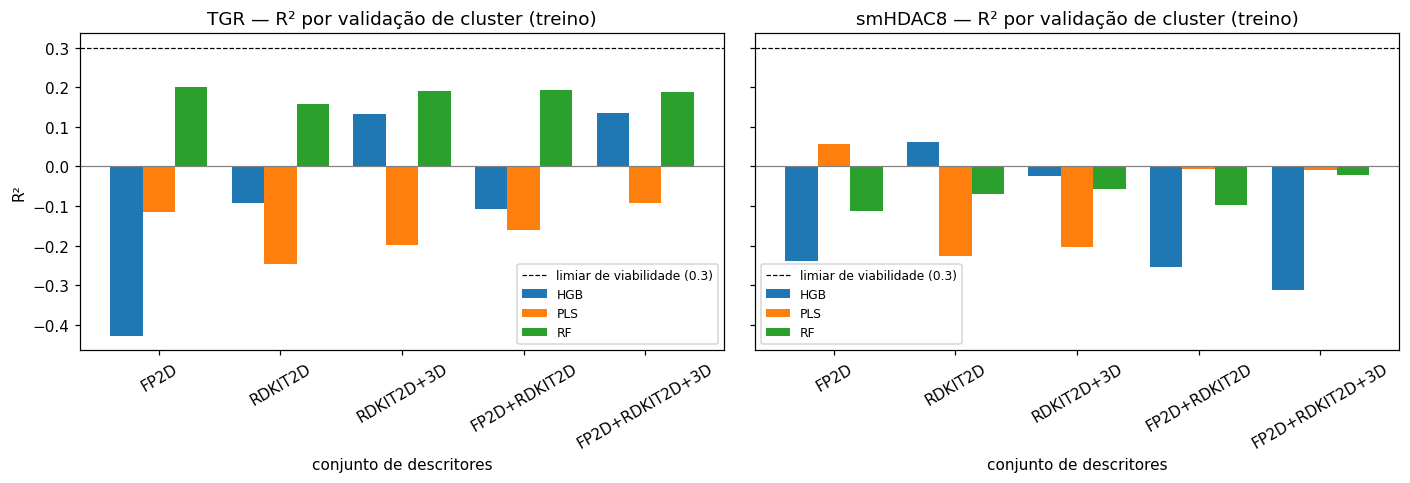

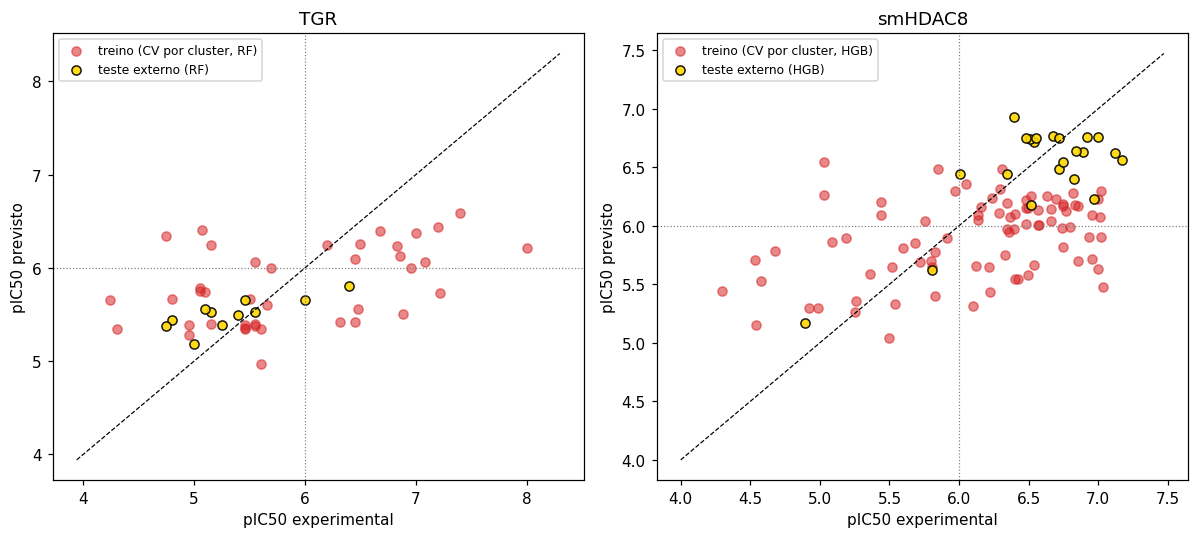

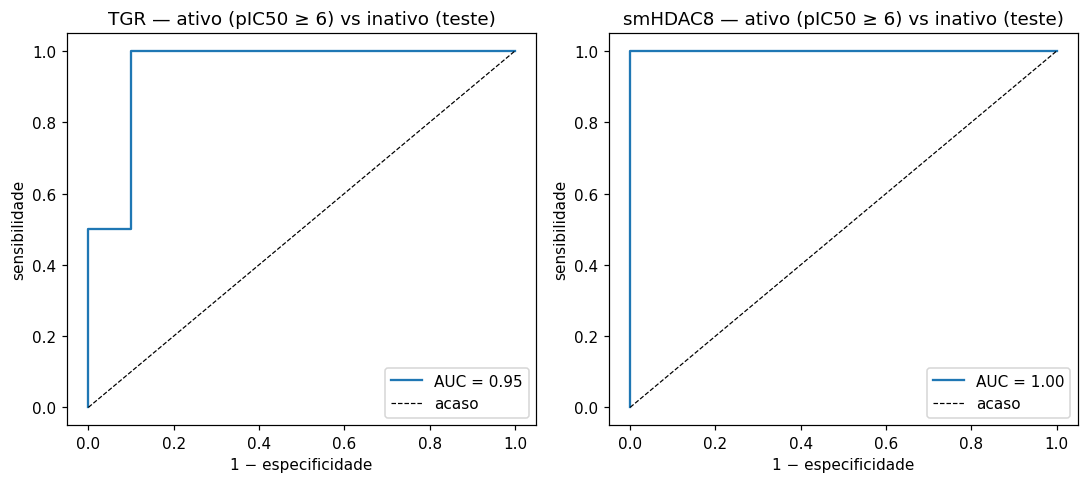

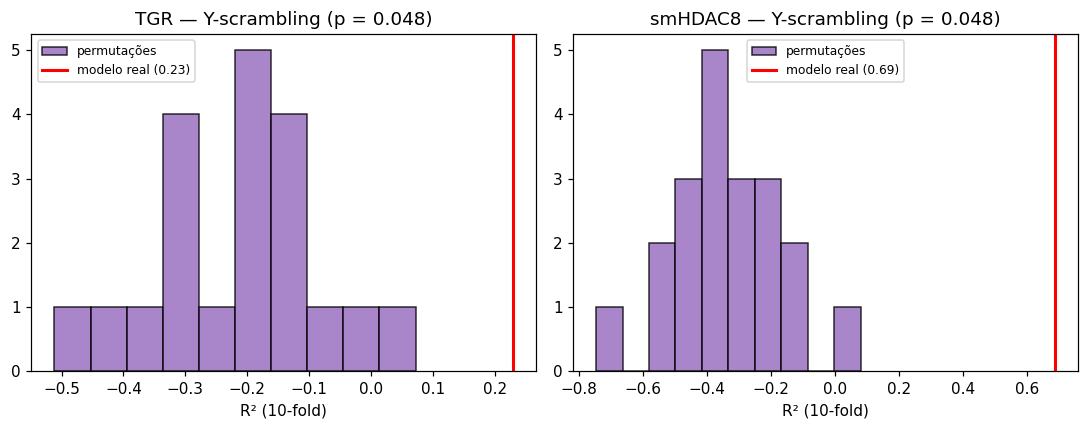

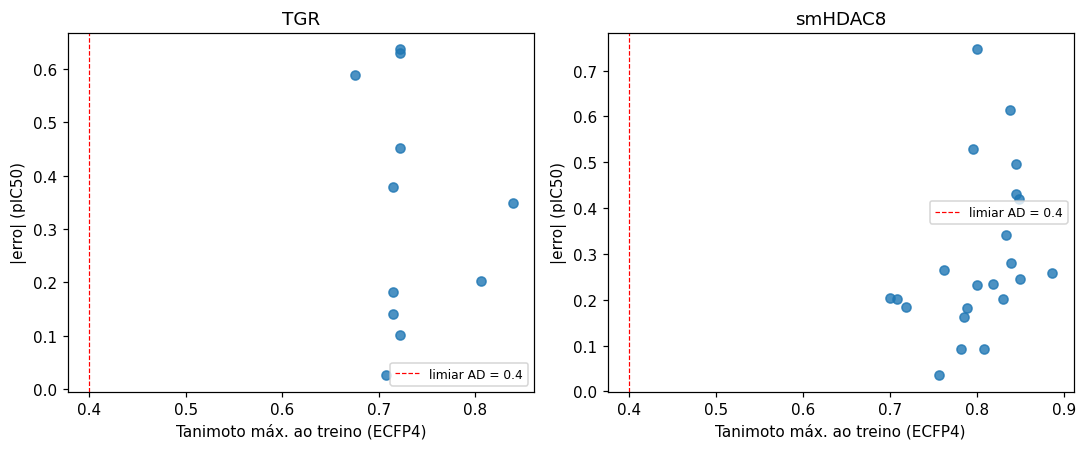

In [13]:
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 10})

# Fig. A — ablação (R² por cluster e aleatório)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, n in zip(axes, TARGETS):
    piv = ABL[n].pivot(index='conjunto', columns='modelo', values='R2_CV_cluster').reindex(list(FEATURE_SETS))
    piv.plot(kind='bar', ax=ax, width=0.8)
    ax.axhline(MIN_R2_VIABLE, color='k', ls='--', lw=0.8, label=f'limiar de viabilidade ({MIN_R2_VIABLE})')
    ax.axhline(0, color='grey', lw=0.8)
    ax.set_title(f'{n} — R² por validação de cluster (treino)')
    ax.set_xlabel('conjunto de descritores'); ax.set_ylabel('R²')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=8, loc='best')
plt.tight_layout(); plt.savefig('figuras/figA_ablacao_descritores.png', bbox_inches='tight'); plt.show()

# Fig. B — previsto vs experimental (CV por cluster no treino + teste externo)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, n in zip(axes, TARGETS):
    tr, te = SPLIT[n]['train'], SPLIT[n]['test']
    bm = max(FINAL[n], key=lambda m: FINAL[n][m]['R2_cluster'])
    pc = ABL_P[n][(FINAL[n][bm]['set'], bm)]['clu']
    pt = CONS[n]['pred_mean'].values if n in CONS else FINAL[n][bm]['pred_test']
    ax.scatter(tr['pIC50'], pc, alpha=0.55, label=f'treino (CV por cluster, {bm})', color='#d62728')
    ax.scatter(te['pIC50'], pt, alpha=0.9, label='teste externo' + (' (consenso)' if n in CONS else f' ({bm})'),
               color='gold', edgecolor='k')
    lo = min(tr['pIC50'].min(), te['pIC50'].min(), pc.min(), pt.min()) - 0.3
    hi = max(tr['pIC50'].max(), te['pIC50'].max(), pc.max(), pt.max()) + 0.3
    ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
    ax.axhline(PIC50_THR, color='grey', ls=':', lw=0.8); ax.axvline(PIC50_THR, color='grey', ls=':', lw=0.8)
    ax.set_xlabel('pIC50 experimental'); ax.set_ylabel('pIC50 previsto'); ax.set_title(n); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figuras/figB_previsto_vs_experimental.png', bbox_inches='tight'); plt.show()

# Fig. C — curvas ROC no teste (classificação)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, n in zip(axes, TARGETS):
    yt = SPLIT_C[n]['test']['y'].values
    prob = CLS_FINAL[n]['_prob_test']
    if len(np.unique(yt)) == 2:
        fpr, tpr, _ = roc_curve(yt, prob)
        ax.plot(fpr, tpr, label=f'AUC = {roc_auc_score(yt, prob):.2f}')
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8, label='acaso')
    ax.set_title(f'{n} — ativo (pIC50 ≥ 6) vs inativo (teste)'); ax.set_xlabel('1 − especificidade'); ax.set_ylabel('sensibilidade')
    ax.legend()
plt.tight_layout(); plt.savefig('figuras/figC_roc_classificacao.png', bbox_inches='tight'); plt.show()

# Fig. D — Y-scrambling
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, n in zip(axes, TARGETS):
    ax.hist(YS[n]['perm'], bins=10, color='#9467bd', edgecolor='k', alpha=0.8, label='permutações')
    ax.axvline(YS[n]['R2_real'], color='r', lw=2, label=f"modelo real ({YS[n]['R2_real']:.2f})")
    ax.set_title(f"{n} — Y-scrambling (p = {YS[n]['p_empirico']:.3f})"); ax.set_xlabel('R² (10-fold)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figuras/figD_y_scrambling.png', bbox_inches='tight'); plt.show()

# Fig. E — domínio de aplicabilidade: erro vs similaridade ao treino
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, n in zip(axes, TARGETS):
    te = SPLIT[n]['test']
    bm = max(FINAL[n], key=lambda m: FINAL[n][m]['R2_cluster'])
    p = CONS[n]['pred_mean'].values if n in CONS else FINAL[n][bm]['pred_test']
    ax.scatter(SPLIT[n]['test_sim'], np.abs(te['pIC50'].values - p), alpha=0.8)
    ax.axvline(AD_THR, color='r', ls='--', lw=0.8, label=f'limiar AD = {AD_THR}')
    ax.set_xlabel('Tanimoto máx. ao treino (ECFP4)'); ax.set_ylabel('|erro| (pIC50)'); ax.set_title(n); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figuras/figE_dominio_aplicabilidade.png', bbox_inches='tight'); plt.show()

## 9. Triagem virtual no ZINC (com domínio de aplicabilidade e filtros mecanísticos)

**Como usar:** coloque os arquivos `.smi` (`SMILES ZINC_ID`) em `zinc_libs/` — por exemplo `zinc_amostra_15k.smi`, `substances.smi` (análogos do PZQ) e, **recomendado**, análogos dos inibidores mais potentes (tabela de sementes abaixo → busca por similaridade no ZINC22).
Se a pasta estiver vazia, o notebook pede o upload.

Regras: previsão só para compostos drug-like e com Tanimoto ≥ 0,30 ao conjunto conhecido do alvo; "no domínio" = Tanimoto ≥ 0,40. Previsões de regressão são limitadas à faixa do treino ± 1 log; previsões fora dela marcam `extrapolacao = True` (descritores fora do domínio) e excluem o composto das prioridades A/B. Prioridade **A** = no domínio + ativo previsto + sem PAINS + sem extrapolação (+ grupo de ligação ao zinco no HDAC8); **B** = ativo previsto + sem PAINS + sem extrapolação; **C** = demais. A coluna `Brenk` é informativa (alertas toxicofóricos, p. ex. nitroaromáticos) para a Discussão.

In [14]:
# ---- 9a. Sementes para a busca por similaridade no ZINC22
for n in TARGETS:
    s = CUR[n]['reg'].sort_values('pIC50', ascending=False).head(8)
    print(f'\n=== {n}: inibidores mais potentes (consulta para busca por similaridade, Tanimoto 40%) ===')
    print(s[['molecule_chembl_id', 'pIC50', 'smiles_std']].to_string(index=False))
    s.to_csv(f'tabelas/sementes_zinc_{n}.csv', index=False)

# ---- 9b. Modelos de implantação (reajustados com todos os dados do alvo)
DEPLOY = {}
for n in TARGETS:
    reg, cls = CUR[n]['reg'], CUR[n]['cls']
    dep = {'reg': {}, 'cls': {}}
    for mn, d in FINAL[n].items():
        if d['viavel']:
            X, _ = X_for(n, reg['smiles_std'], d['set'])
            dep['reg'][mn] = (d['set'], make_reg(mn).fit(X, reg['pIC50'].values))
    row = CLS_TAB[CLS_TAB['alvo'] == n].iloc[0]
    if bool(row['viavel_para_triagem']):
        X, _ = X_for(n, cls['smiles_std'], CLS_SET[n])
        for mn in ['RF', 'HGB']:
            dep['cls'][mn] = (CLS_SET[n], make_cls(mn).fit(X, cls['y'].values))
    DEPLOY[n] = dep
    ref = sorted(set(reg['smiles_std']) | set(cls['smiles_std']))
    dep['ref_ecfp'] = np.vstack([FEATS[n]['blocks']['ecfp4'][0][FEATS[n]['index'][s]] for s in ref])
    print(f"{n}: modelos de regressão viáveis = {list(dep['reg'])} | classificadores viáveis = {list(dep['cls'])}")
joblib.dump({n: {k: v for k, v in d.items()} for n, d in DEPLOY.items()}, 'models/deploy_v2.joblib')

# ---- 9c. Leitura das bibliotecas
def read_smi(path):
    d = pd.read_csv(path, sep=r'\s+', header=None, usecols=[0, 1], names=['smiles', 'zinc_id'], dtype=str)
    return d[d['smiles'].str.lower() != 'smiles']

for f in ['zinc_amostra_15k.smi', 'substances.smi']:
    if os.path.exists(f) and not os.path.exists(f'zinc_libs/{f}'):
        shutil.copy(f, f'zinc_libs/{f}')
if not glob.glob('zinc_libs/*.smi'):
    try:
        from google.colab import files
        print('Envie os arquivos .smi do ZINC (um ou mais):')
        for name, content in files.upload().items():
            open(f'zinc_libs/{name}', 'wb').write(content)
    except Exception:
        print('Nenhum .smi em zinc_libs/ — a triagem será pulada.')

libs = []
for p in sorted(glob.glob('zinc_libs/*.smi')):
    d = read_smi(p)
    d['origem'] = os.path.basename(p)
    libs.append(d)
    print(f'{os.path.basename(p)}: {len(d)} compostos')
LIB = pd.concat(libs, ignore_index=True) if libs else pd.DataFrame(columns=['smiles', 'zinc_id', 'origem'])
print('Total (bruto):', len(LIB))


=== TGR: inibidores mais potentes (consulta para busca por similaridade, Tanimoto 40%) ===
molecule_chembl_id    pIC50                                                        smiles_std
     CHEMBL3322287 8.000000               NC(=O)c1c(C(=O)N2CC(=O)N3CCc4ccccc4C3C2)no[n+]1[O-]
      CHEMBL570345 7.397940                          O=C(c1cccs1)c1no[n+]([O-])c1C(=O)c1cccs1
     CHEMBL1439384 7.221849                   COc1ccc([N+](=O)[O-])c(S(=O)(=O)c2ccc(Cl)cc2)n1
      CHEMBL576265 7.200659                                   N#Cc1c(C(=O)c2cccs2)no[n+]1[O-]
     CHEMBL3322292 7.080922 NC(=O)c1c(COc2ccc3c(c2)C2CN(C(=O)C4CCCCC4)CC(=O)N2CC3)no[n+]1[O-]
     CHEMBL1325877 7.000000                COc1ccc(C(=O)c2no[n+]([O-])c2C(=O)c2ccc(OC)cc2)cc1
      CHEMBL567637 6.958607                                      O=Cc1c(-c2ccccc2)no[n+]1[O-]
     CHEMBL1486739 6.886057                     COc1ccc(C(Nc2cc(C)ccn2)c2ccc3ccc(C)nc3c2O)cc1

=== smHDAC8: inibidores mais potentes (consulta para busca po

Saving pzq_zinc20.smi to pzq_zinc20.smi
pzq_zinc20.smi: 85 compostos
Total (bruto): 85


In [15]:
!mv "ZINC-downloader-2D-smi (1).uri" zinc2.uri
!mv "ZINC-downloader-2D-smi.uri" zinc1.uri
!head -n 3 zinc1.uri                      # confirma que são URLs
!mkdir -p zinc
!head -n 20 zinc1.uri | xargs -P 8 -n 1 wget -q -nc -P zinc
!ls -lh zinc | head

mv: cannot stat 'ZINC-downloader-2D-smi (1).uri': No such file or directory
mv: cannot stat 'ZINC-downloader-2D-smi.uri': No such file or directory
head: cannot open 'zinc1.uri' for reading: No such file or directory
head: cannot open 'zinc1.uri' for reading: No such file or directory
wget: missing URL
Usage: wget [OPTION]... [URL]...

Try `wget --help' for more options.
total 0


In [16]:
!ls -lh zinc
!du -sh zinc

total 0
4.0K	zinc


In [17]:
from google.colab import files
import pandas as pd
up = files.upload()
df = pd.read_csv(list(up.keys())[0])
print(df.shape)
print(df.columns.tolist())

Saving substances.csv to substances.csv
(85, 2)
['zinc_id', 'smiles']


In [18]:
from google.colab import files
df[['smiles', 'zinc_id']].to_csv('pzq_zinc20.smi', sep=' ', header=False, index=False)
files.download('pzq_zinc20.smi')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# ---- 9d. Padronização, propriedades e domínio de aplicabilidade
# O tautômero canônico do RDKit converte hidroxamatos para a forma hidroxímica (C(O)=NO): os dois são reconhecidos.
ZBG = {'hidroxamato': ['[CX3](=O)[NX3][OX2H1]', '[CX3]([OX2H1])=[NX2][OX2H1]'],
       'o-aminoanilida': ['[NX3;H2]c:c[NX3;H1]C(=O)', '[NX3;H2]c:c[NX2]=C[OX2H1]'],
       'tiol': ['[SX2;H1]'],
       'cetona CF3 (fraco)': ['[CX3](=O)C(F)(F)F'],
       'ácido carboxílico (fraco)': ['[CX3](=O)[OX2H1]']}
ZBG_FORTE = {'hidroxamato', 'o-aminoanilida', 'tiol'}
ZBG_PAT = {k: [Chem.MolFromSmarts(x) for x in v] for k, v in ZBG.items()}
CAT_PAINS = FilterCatalog(FilterCatalogParams(FilterCatalogParams.FilterCatalogs.PAINS))
CAT_BRENK = FilterCatalog(FilterCatalogParams(FilterCatalogParams.FilterCatalogs.BRENK))

def first_match(cat, m):
    e = cat.GetFirstMatch(m)
    return e.GetDescription() if e is not None else ''

RESULTS = {}
if len(LIB):
    LIB['smiles_std'] = [standardize(s) for s in tqdm(LIB['smiles'], desc='padronizando biblioteca')]
    LIB = LIB.dropna(subset=['smiles_std']).drop_duplicates('smiles_std').reset_index(drop=True)
    mols = [Chem.MolFromSmiles(s) for s in LIB['smiles_std']]
    phys, _ = block_phys(mols)
    ecfp = block_ecfp(mols)
    LIB['MW'], LIB['LogP'], LIB['HBD'], LIB['HBA'], LIB['TPSA'] = phys[:, 0], phys[:, 1], phys[:, 2], phys[:, 3], phys[:, 4]
    LIB['violacoes_Lipinski'] = lipinski_violations(phys)
    LIB['drug_like'] = LIB['violacoes_Lipinski'] <= 1
    print(f"Biblioteca padronizada: {len(LIB)} estruturas únicas | drug-like: {int(LIB['drug_like'].sum())}")

    for n in TARGETS:
        dep = DEPLOY[n]
        if not dep['reg'] and not dep['cls']:
            print(f'\n[{n}] sem modelo viável (regressão: R² < {MIN_R2_VIABLE} e ρ < {MIN_RHO_VIABLE} por cluster; classificação: AUC < {MIN_AUC_VIABLE}) — triagem NÃO executada. '
                  'Reportar como resultado negativo/exploratório.')
            continue
        LIB[f'maxsim_{n}'] = max_tanimoto(ecfp, dep['ref_ecfp'])
        sel = LIB['drug_like'] & (LIB[f'maxsim_{n}'] >= AD_FLOOR)
        print(f"\n[{n}] drug-like com Tanimoto ≥ {AD_FLOOR}: {int(sel.sum())} | no domínio (≥ {AD_THR}): "
              f"{int((LIB['drug_like'] & (LIB[f'maxsim_{n}'] >= AD_THR)).sum())}")
        if sel.sum() == 0:
            print('   nenhum composto da biblioteca está próximo o bastante do espaço químico do alvo. '
                  'Use as sementes acima para gerar uma biblioteca focada (busca por similaridade no ZINC).')
            continue
        sub = LIB[sel].copy()
        sub_mols = [mols[i] for i in sub.index]
        sets = [s for s, _ in list(dep['reg'].values()) + list(dep['cls'].values())]
        blocks = featurize(sub_mols, sorted({b for s in sets for b in FEATURE_SETS[s]}))
        out = pd.DataFrame(index=sub.index)
        preds, extrap = [], np.zeros(len(sub), dtype=bool)
        yk = CUR[n]['reg']['pIC50']
        lo, hi = yk.min() - 1.0, yk.max() + 1.0   # faixa plausível: treino ± 1 unidade log
        for mn, (fs, est) in dep['reg'].items():
            Xs, _ = assemble(blocks, fs)
            raw = np.ravel(est.predict(Xs))
            extrap |= (raw < lo) | (raw > hi)       # previsão absurda = descritores fora do domínio
            out[f'pIC50_{mn}'] = np.clip(raw, lo, hi)
            preds.append(out[f'pIC50_{mn}'].values)
        if preds:
            P = np.vstack(preds)
            out['pIC50_consenso'] = P.mean(axis=0)
            out['pIC50_dp'] = P.std(axis=0, ddof=1) if len(P) > 1 else 0.0
            out['CV%'] = out['pIC50_dp'] / out['pIC50_consenso'] * 100
        out['extrapolacao'] = extrap
        probs = [est.predict_proba(assemble(blocks, fs)[0])[:, 1] for fs, est in dep['cls'].values()]
        if probs:
            out['p_ativo'] = np.mean(probs, axis=0)
        res = pd.concat([sub[['zinc_id', 'origem', 'smiles_std', 'MW', 'LogP', 'HBD', 'HBA', 'TPSA', f'maxsim_{n}']]
                         .rename(columns={f'maxsim_{n}': 'maxsim'}), out], axis=1)
        res['no_dominio'] = res['maxsim'] >= AD_THR
        res['PAINS'] = [first_match(CAT_PAINS, m) for m in sub_mols]
        res['Brenk'] = [first_match(CAT_BRENK, m) for m in sub_mols]
        if n == 'smHDAC8':
            zb = [[k for k, ps in ZBG_PAT.items() if any(m.HasSubstructMatch(p) for p in ps)] for m in sub_mols]
            res['ZBG'] = ['; '.join(z) for z in zb]
            res['ZBG_forte'] = [any(k in ZBG_FORTE for k in z) for z in zb]
        ativo = (res.get('pIC50_consenso', pd.Series(np.nan, index=res.index)) >= PIC50_THR) | \
                (res.get('p_ativo', pd.Series(0.0, index=res.index)) >= 0.5)
        zbg_ok = res['ZBG_forte'] if 'ZBG_forte' in res else pd.Series(True, index=res.index)
        limpo = (res['PAINS'] == '') & ~res['extrapolacao']
        res['prioridade'] = np.where(res['no_dominio'] & ativo & limpo & zbg_ok, 'A',
                                     np.where(ativo & limpo, 'B', 'C'))
        sort_col = 'p_ativo' if 'p_ativo' in res else 'pIC50_consenso'
        res = res.sort_values(['prioridade', sort_col], ascending=[True, False]).reset_index(drop=True)
        RESULTS[n] = res
        res.to_csv(f'tabelas/triagem_{n}.csv', index=False)
        print(f"   prioridade A: {(res['prioridade'] == 'A').sum()} | B: {(res['prioridade'] == 'B').sum()} | C: {(res['prioridade'] == 'C').sum()}")
        print(res.head(15)[['zinc_id', 'origem', 'maxsim', 'prioridade'] + [c for c in ['pIC50_consenso', 'CV%', 'p_ativo', 'ZBG', 'PAINS'] if c in res]].round(3).to_string(index=False))
else:
    print('Sem biblioteca — triagem pulada.')

padronizando biblioteca:   0%|          | 0/85 [00:00<?, ?it/s]

Biblioteca padronizada: 79 estruturas únicas | drug-like: 79

[TGR] sem modelo viável (regressão: R² < 0.3 e ρ < 0.5 por cluster; classificação: AUC < 0.65) — triagem NÃO executada. Reportar como resultado negativo/exploratório.

[smHDAC8] drug-like com Tanimoto ≥ 0.3: 0 | no domínio (≥ 0.4): 0
   nenhum composto da biblioteca está próximo o bastante do espaço químico do alvo. Use as sementes acima para gerar uma biblioteca focada (busca por similaridade no ZINC).


In [20]:
# ---- 9e. Priorização dos análogos do PZQ por similaridade às sementes do TGR
SEEDS_TGR = {
    'CHEMBL3322287': 'NC(=O)c1c(C(=O)N2CC(=O)N3CCc4ccccc4C3C2)no[n+]1[O-]',
    'CHEMBL570345':  'O=C(c1cccs1)c1no[n+]([O-])c1C(=O)c1cccs1',
    'CHEMBL1439384': 'COc1ccc([N+](=O)[O-])c(S(=O)(=O)c2ccc(Cl)cc2)n1',
    'CHEMBL576265':  'N#Cc1c(C(=O)c2cccs2)no[n+]1[O-]',
    'CHEMBL3322292': 'NC(=O)c1c(COc2ccc3c(c2)C2CN(C(=O)C4CCCCC4)CC(=O)N2CC3)no[n+]1[O-]',
    'CHEMBL1325877': 'COc1ccc(C(=O)c2no[n+]([O-])c2C(=O)c2ccc(OC)cc2)cc1',
    'CHEMBL567637':  'O=Cc1c(-c2ccccc2)no[n+]1[O-]',
    'CHEMBL1486739': 'COc1ccc(C(Nc2cc(C)ccn2)c2ccc3ccc(C)nc3c2O)cc1',
}
seed_mols = [Chem.MolFromSmiles(s) for s in (standardize(x) for x in SEEDS_TGR.values()) if s]
seed_ecfp = block_ecfp(seed_mols)

LIB['maxsim_TGR_sementes'] = max_tanimoto(ecfp, seed_ecfp)
LIB['PAINS'] = [first_match(CAT_PAINS, m) for m in mols]
LIB['Brenk'] = [first_match(CAT_BRENK, m) for m in mols]
LIB['prioridade_TGR'] = np.where(
    LIB['drug_like'] & (LIB['PAINS'] == '') & (LIB['maxsim_TGR_sementes'] >= AD_THR), 'A',
    np.where(LIB['drug_like'] & (LIB['maxsim_TGR_sementes'] >= AD_FLOOR), 'B', 'C'))

res_tgr = LIB.sort_values(['prioridade_TGR', 'maxsim_TGR_sementes'],
                          ascending=[True, False]).reset_index(drop=True)
res_tgr.to_csv('tabelas/priorizacao_TGR_similaridade.csv', index=False)
print(res_tgr['prioridade_TGR'].value_counts().to_string())
print(res_tgr.head(15)[['zinc_id', 'maxsim_TGR_sementes', 'prioridade_TGR',
                        'MW', 'LogP', 'PAINS', 'Brenk']].round(3).to_string(index=False))

prioridade_TGR
A    54
C    15
B    10
         zinc_id  maxsim_TGR_sementes prioridade_TGR      MW  LogP PAINS   Brenk
ZINC000082151414                0.575              A 328.412 2.240              
ZINC000082151416                0.575              A 328.412 2.240              
ZINC000028823655                0.568              A 327.428 2.117       aniline
ZINC000028823656                0.568              A 327.428 2.117       aniline
ZINC000036138040                0.548              A 315.373 0.880              
ZINC000036138038                0.548              A 315.373 0.880              
ZINC000036138123                0.547              A 346.858 3.188              
ZINC000036138125                0.547              A 346.858 3.188              
ZINC000049072285                0.541              A 313.401 2.034              
ZINC000049072283                0.541              A 313.401 2.034              
ZINC000039434573                0.532              A 298.386 2.145    

In [21]:
furoxano = Chem.MolFromSmarts('[#6]1~[#7]~[#8]~[#7+]([O-])~[#6]~1')
LIB['furoxano'] = [m.HasSubstructMatch(furoxano) for m in mols]
print(LIB['furoxano'].sum(), 'de', len(LIB), 'têm furoxano')

0 de 79 têm furoxano


In [22]:
print(sum(m.HasSubstructMatch(furoxano) for m in seed_mols), 'de', len(seed_mols), 'sementes têm furoxano (esperado: 6)')

6 de 8 sementes têm furoxano (esperado: 6)


In [23]:
LIB['flat'] = [Chem.MolToSmiles(m, isomericSmiles=False) for m in mols]
print(LIB['flat'].nunique(), 'estruturas distintas, de', len(LIB))

40 estruturas distintas, de 79


In [24]:
res_tgr['flat'] = [Chem.MolToSmiles(Chem.MolFromSmiles(s), isomericSmiles=False) for s in res_tgr['smiles_std']]
res_tgr['n_estereoisomeros'] = res_tgr.groupby('flat')['flat'].transform('size')
uniq = res_tgr.drop_duplicates('flat').reset_index(drop=True)
uniq.to_csv('tabelas/priorizacao_TGR_unicos.csv', index=False)
print(len(uniq), 'estruturas únicas')
print(uniq['prioridade_TGR'].value_counts().to_string())

40 estruturas únicas
prioridade_TGR
A    26
C     9
B     5


In [25]:
from google.colab import files
files.download('tabelas/priorizacao_TGR_unicos.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Resumo e exportação

In [26]:
print('================ RESUMO CONSOLIDADO PARA O TCC ================')
print('\n[1. Funil de Curadoria]');                     print(FUNIL.to_string())
print('\n[2. Critérios de Lipinski]');                  print(LIP.to_string(index=False))
print('\n[3. Desempenho Teste Externo — Regressão]');    print(TESTE.round(3).to_string(index=False))
print('\n[4. Desempenho Teste Externo — Classificação]');print(CLS_TAB.round(3).to_string(index=False))
print('\n[5. Validação por Y-Scrambling]');             print(YS_TAB.round(3).to_string(index=False))
print('\n[6. Domínio de Aplicabilidade no Teste]');       print(AD_TAB.round(3).to_string(index=False))

print('\n[7. Triagem Virtual Tradicional (Se houver)]')
for n, r in RESULTS.items():
    print(f'   - Alvo {n} -> Prioridade A: {(r.prioridade == "A").sum()} | B: {(r.prioridade == "B").sum()} | Total: {len(r)}')
    top = r[r.prioridade == 'A']
    if len(top):
        top[['zinc_id', 'smiles_std']].to_csv(f'tabelas/shortlist_{n}_para_docking.smi', sep=' ', header=False, index=False)

print('\n[8. Priorização de Análogos (Sementes TGR)]')
if 'prioridade_TGR' in res_tgr.columns:
    print(f'   - Total avaliado por similaridade: {len(res_tgr)}')
    print('   - Distribuição de classes (Completo):')
    print(res_tgr['prioridade_TGR'].value_counts().to_string())
if 'uniq' in locals() or 'uniq' in globals():
    print(f'   - Estruturas planas (flat) exclusivas remanescentes: {len(uniq)}')
    print('   - Distribuição de classes (Estruturas Únicas):')
    print(uniq['prioridade_TGR'].value_counts().to_string())

# Salvamento do deploy e modelos finais compactados
joblib.dump({'FINAL': {n: {m: {k: v for k, v in d.items() if k != 'pred_test'} for m, d in dd.items()} for n, dd in FINAL.items()},
             'CLS_SET': CLS_SET}, 'models/finais_v2.joblib')

# Criação dos pacotes de exportação
shutil.make_archive('resultados_TCC_v2_figuras', 'zip', '.', 'figuras')
shutil.make_archive('resultados_TCC_v2_tabelas', 'zip', '.', 'tabelas')
print('\n================ EXPORTAÇÃO CONCLUÍDA ================')
print('Arquivos gerados com sucesso: resultados_TCC_v2_figuras.zip e resultados_TCC_v2_tabelas.zip.')

================ RESUMO CONSOLIDADO PARA O TCC ================

[1. Funil de Curadoria]
                                                        TGR   smHDAC8
1. registros IC50 brutos (ChEMBL)                        59       260
2. com valor > 0, unidade nM e SMILES                    58       258
3. SMILES padronizado com sucesso                        58       258
    dos quais censurados (relação ≠ '=')                  6       106
4. valores exatos ('=') — base da regressão              52       152
5. estruturas únicas (após padronização)                 51       107
6. sem réplicas discordantes (> 1 log)                   51       106
7. classificação: estruturas com rótulo inequívoco       57       203
    ativos / inativos (IC50 ≤ 1 µM)                 19 / 38  74 / 129

[2. Critérios de Lipinski]
   alvo   N  0 violações  1 violação  ≥2 violações drug-like (≤1)
    TGR  51           48           3             0         100.0%
smHDAC8 106           95           9             2 

### Visualização dos Resultados Consolidados e Figuras do TCC

================ IMPRESSÃO DOS GRÁFICOS DO TCC (300 DPI) ================

Figura: figuras/figA_ablacao_descritores.png


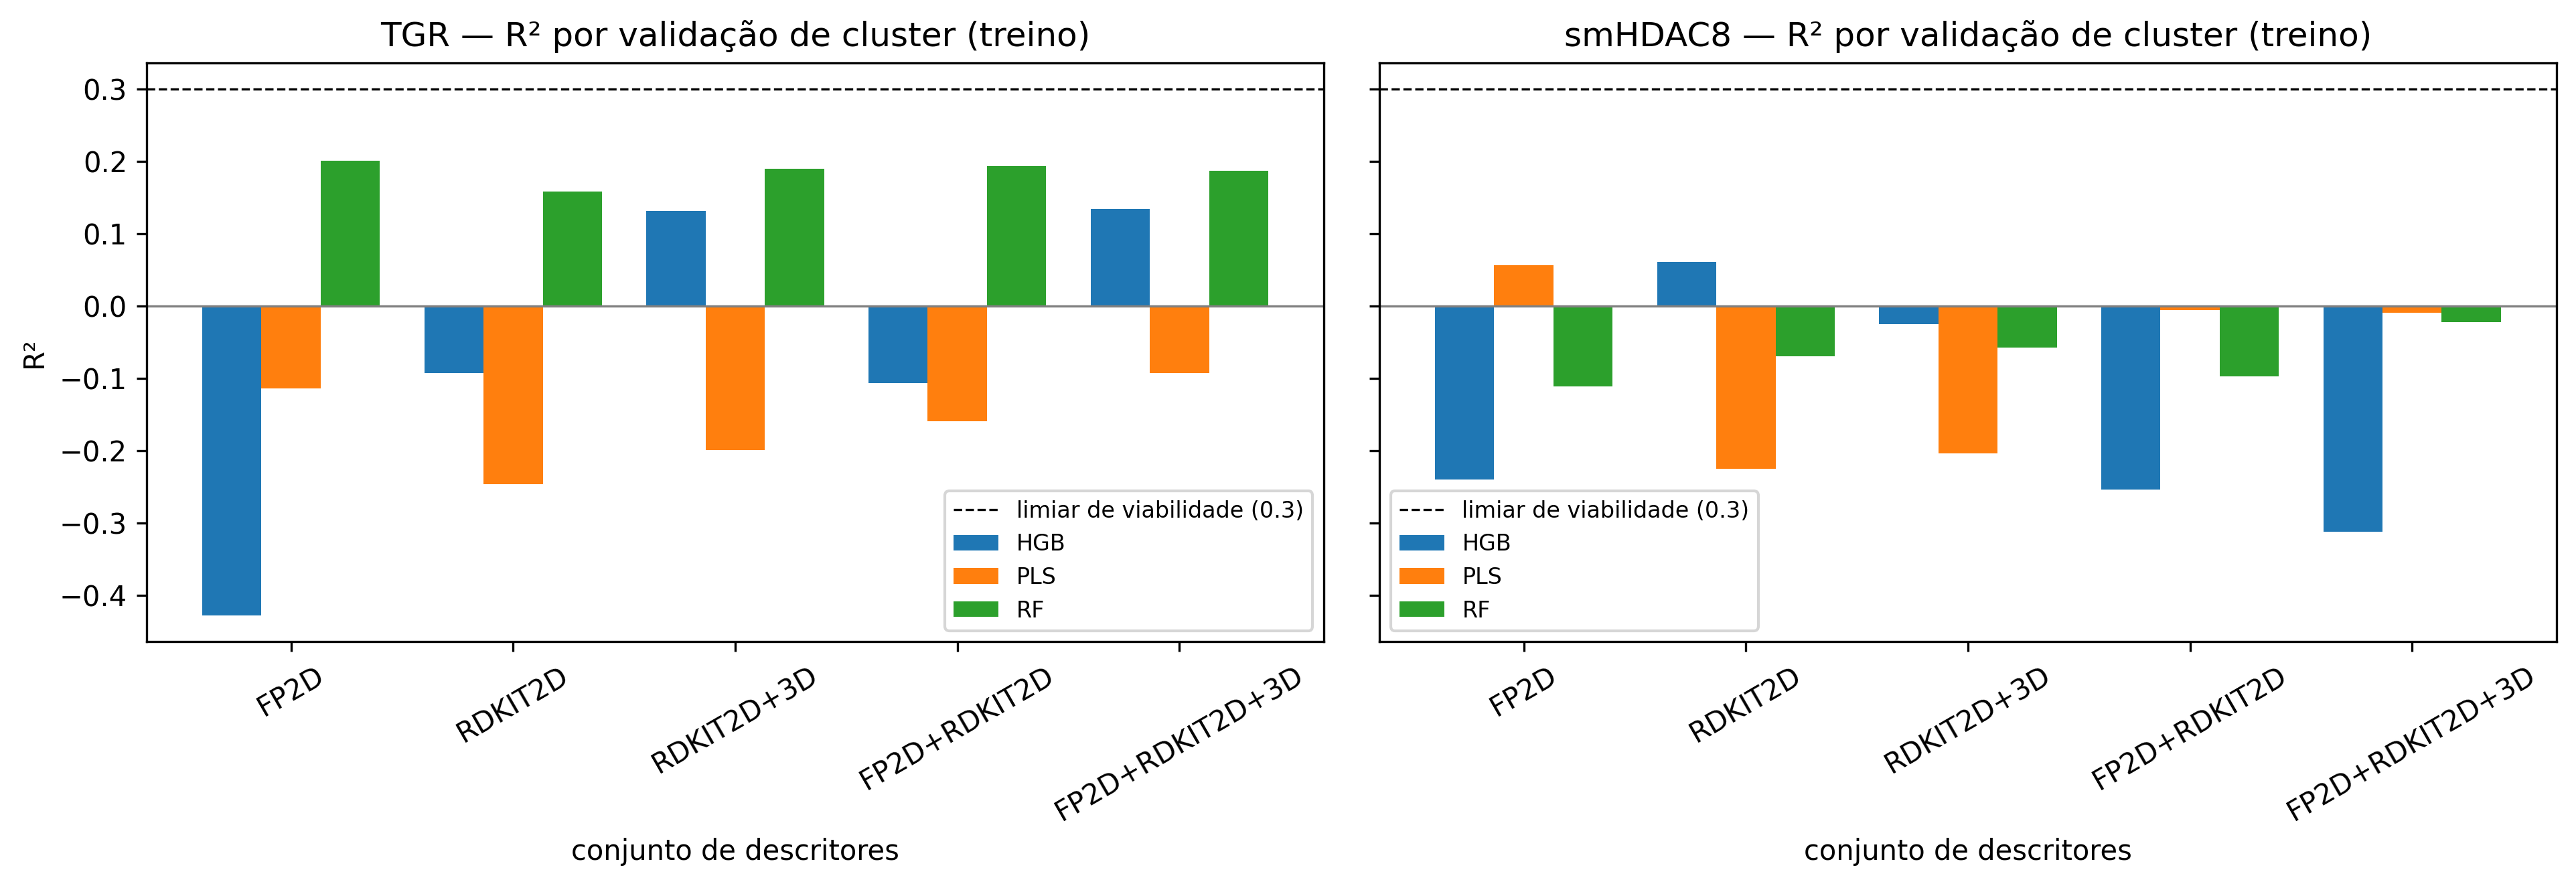


Figura: figuras/figB_previsto_vs_experimental.png


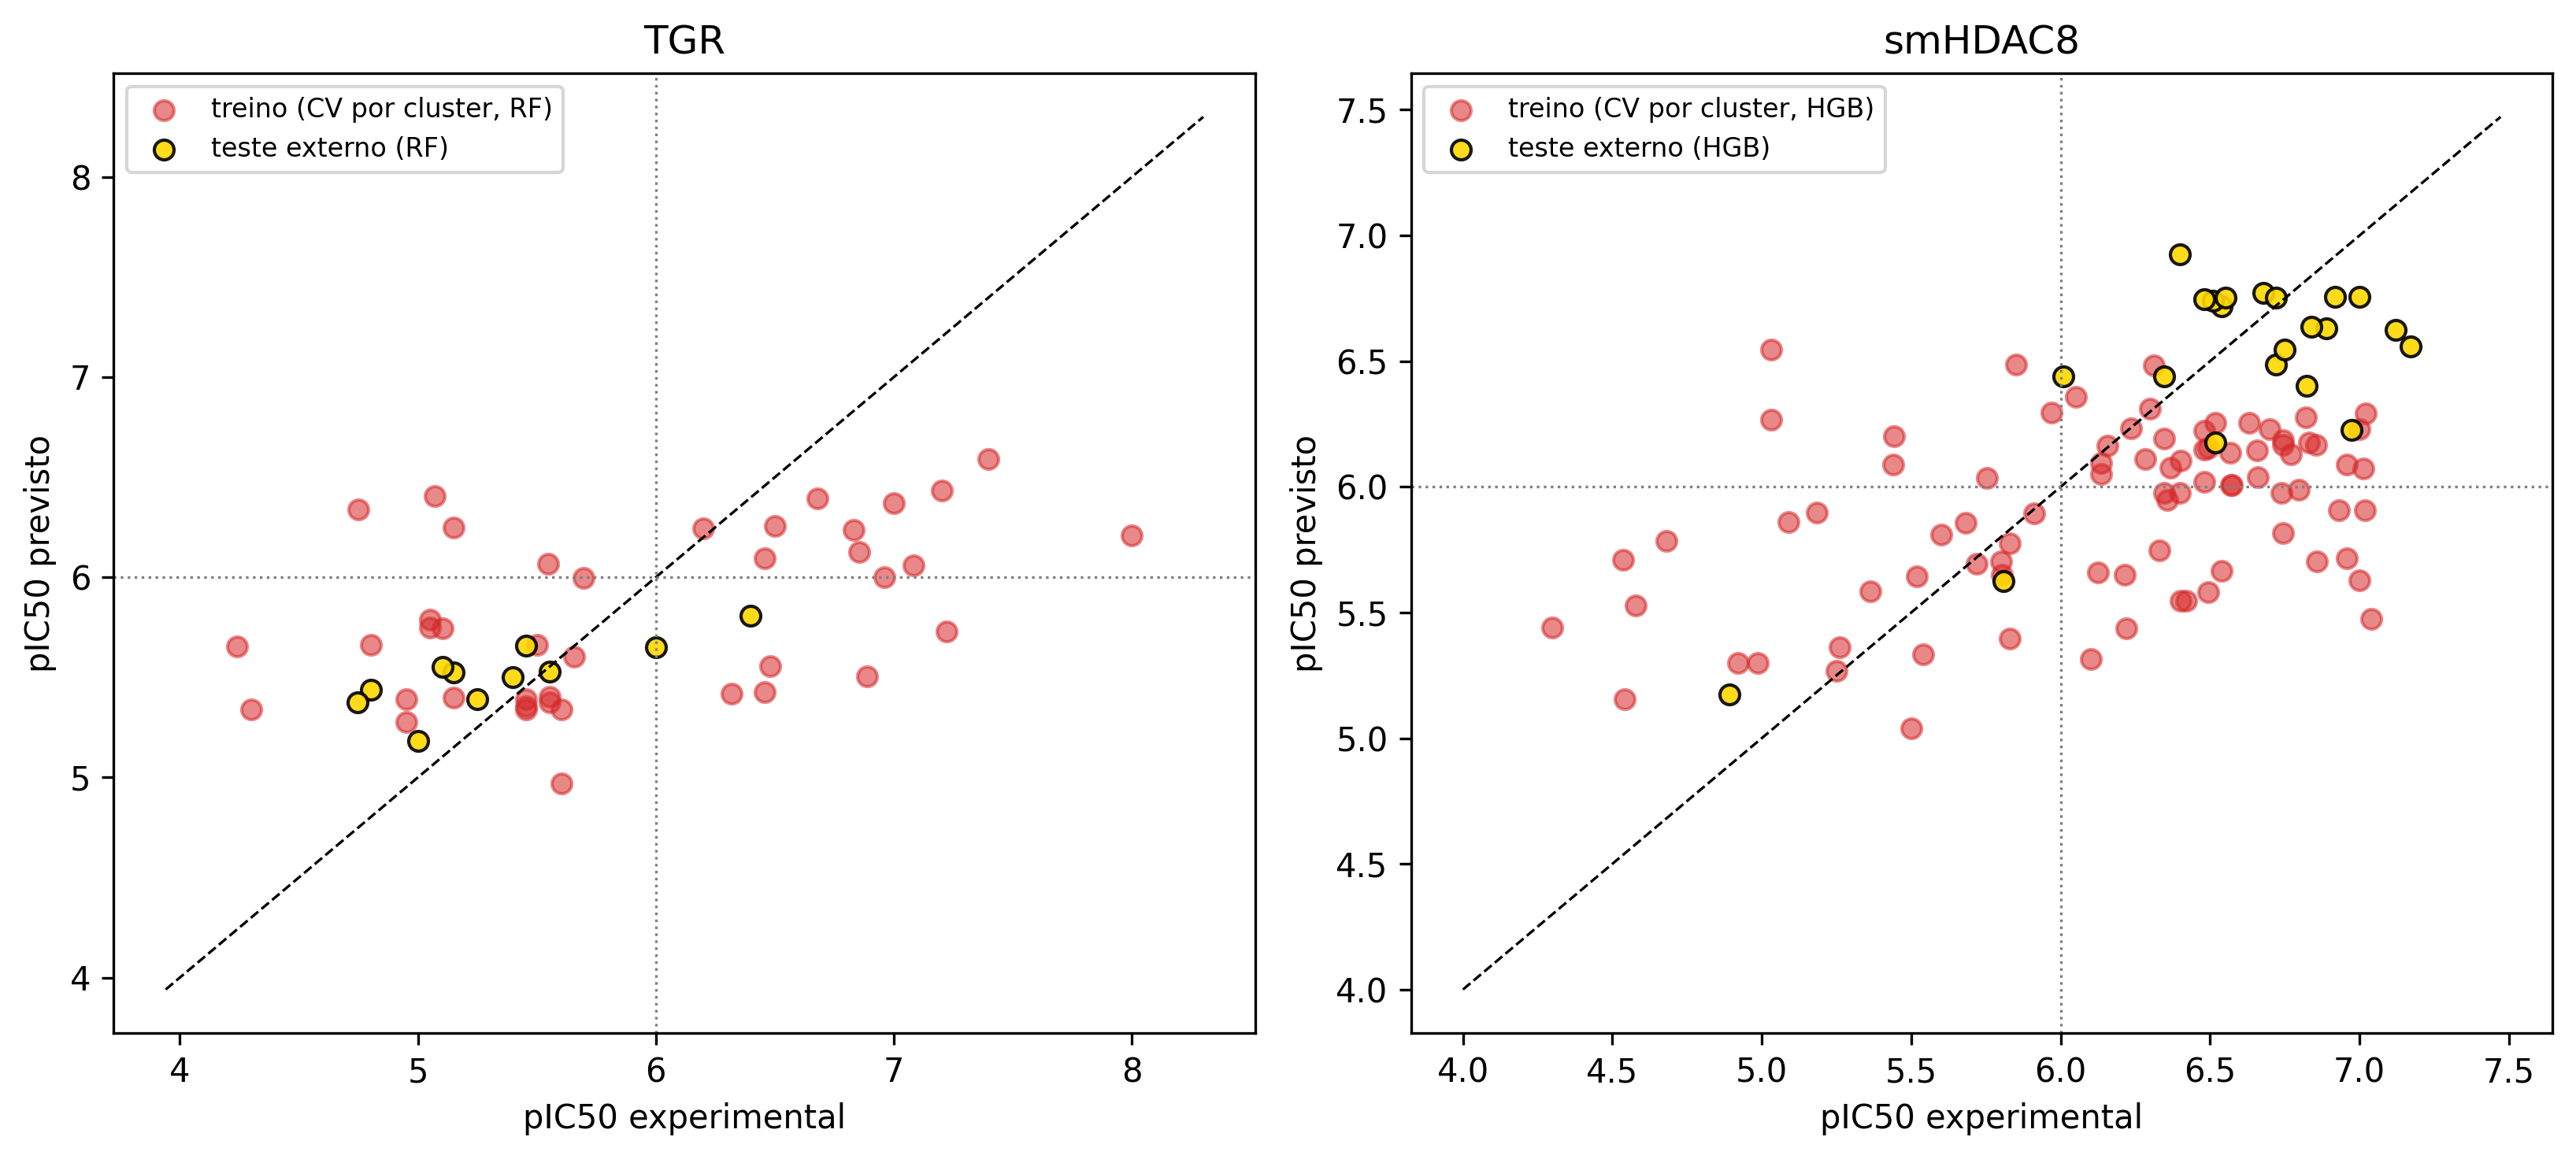


Figura: figuras/figC_roc_classificacao.png


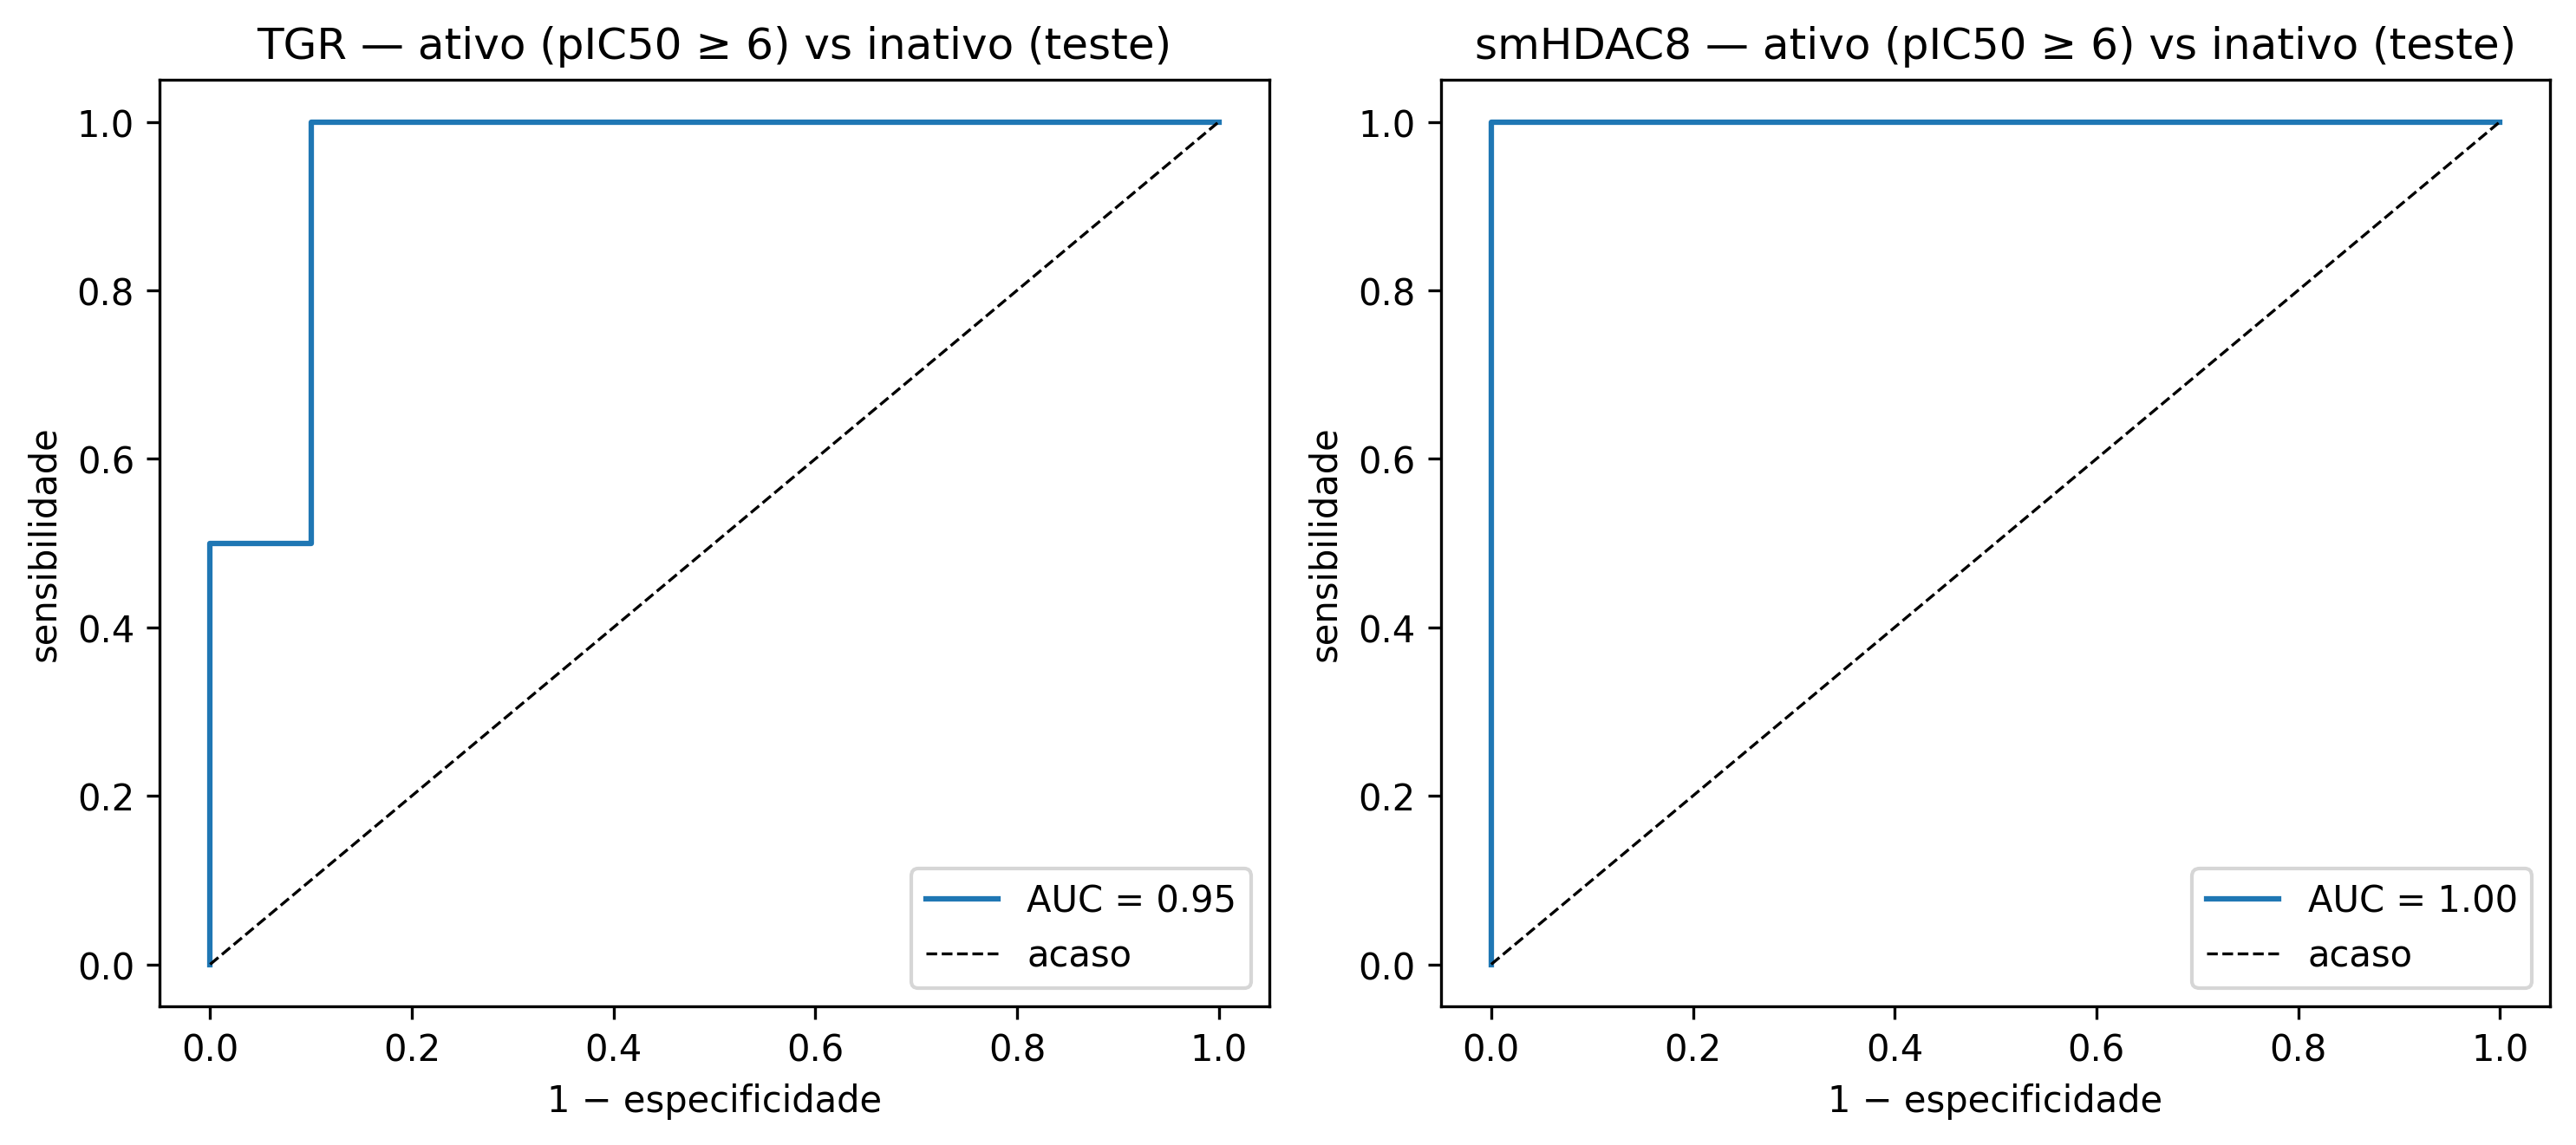


Figura: figuras/figD_y_scrambling.png


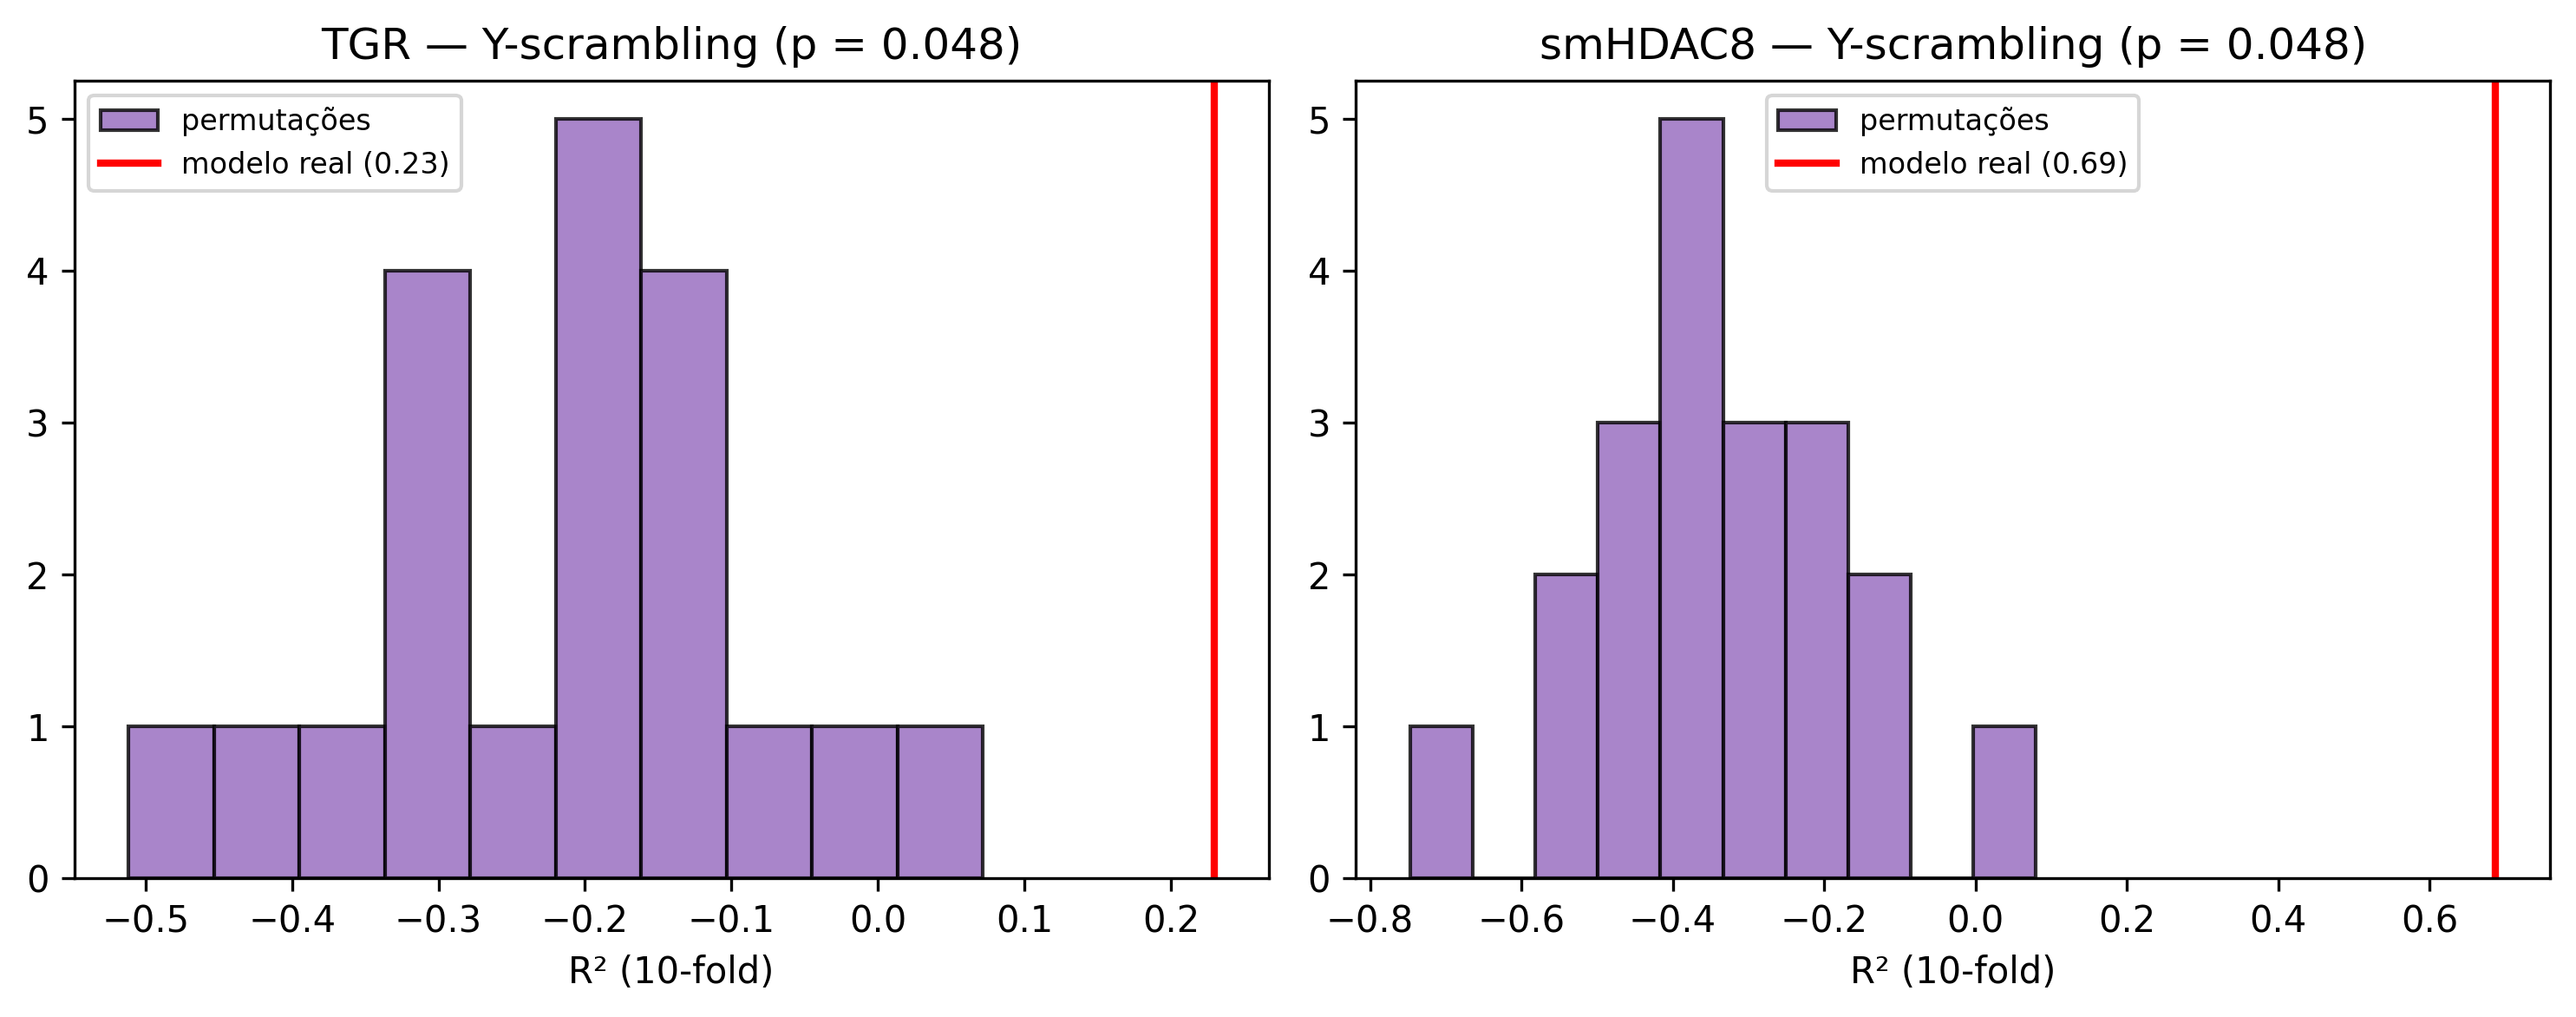


Figura: figuras/figE_dominio_aplicabilidade.png


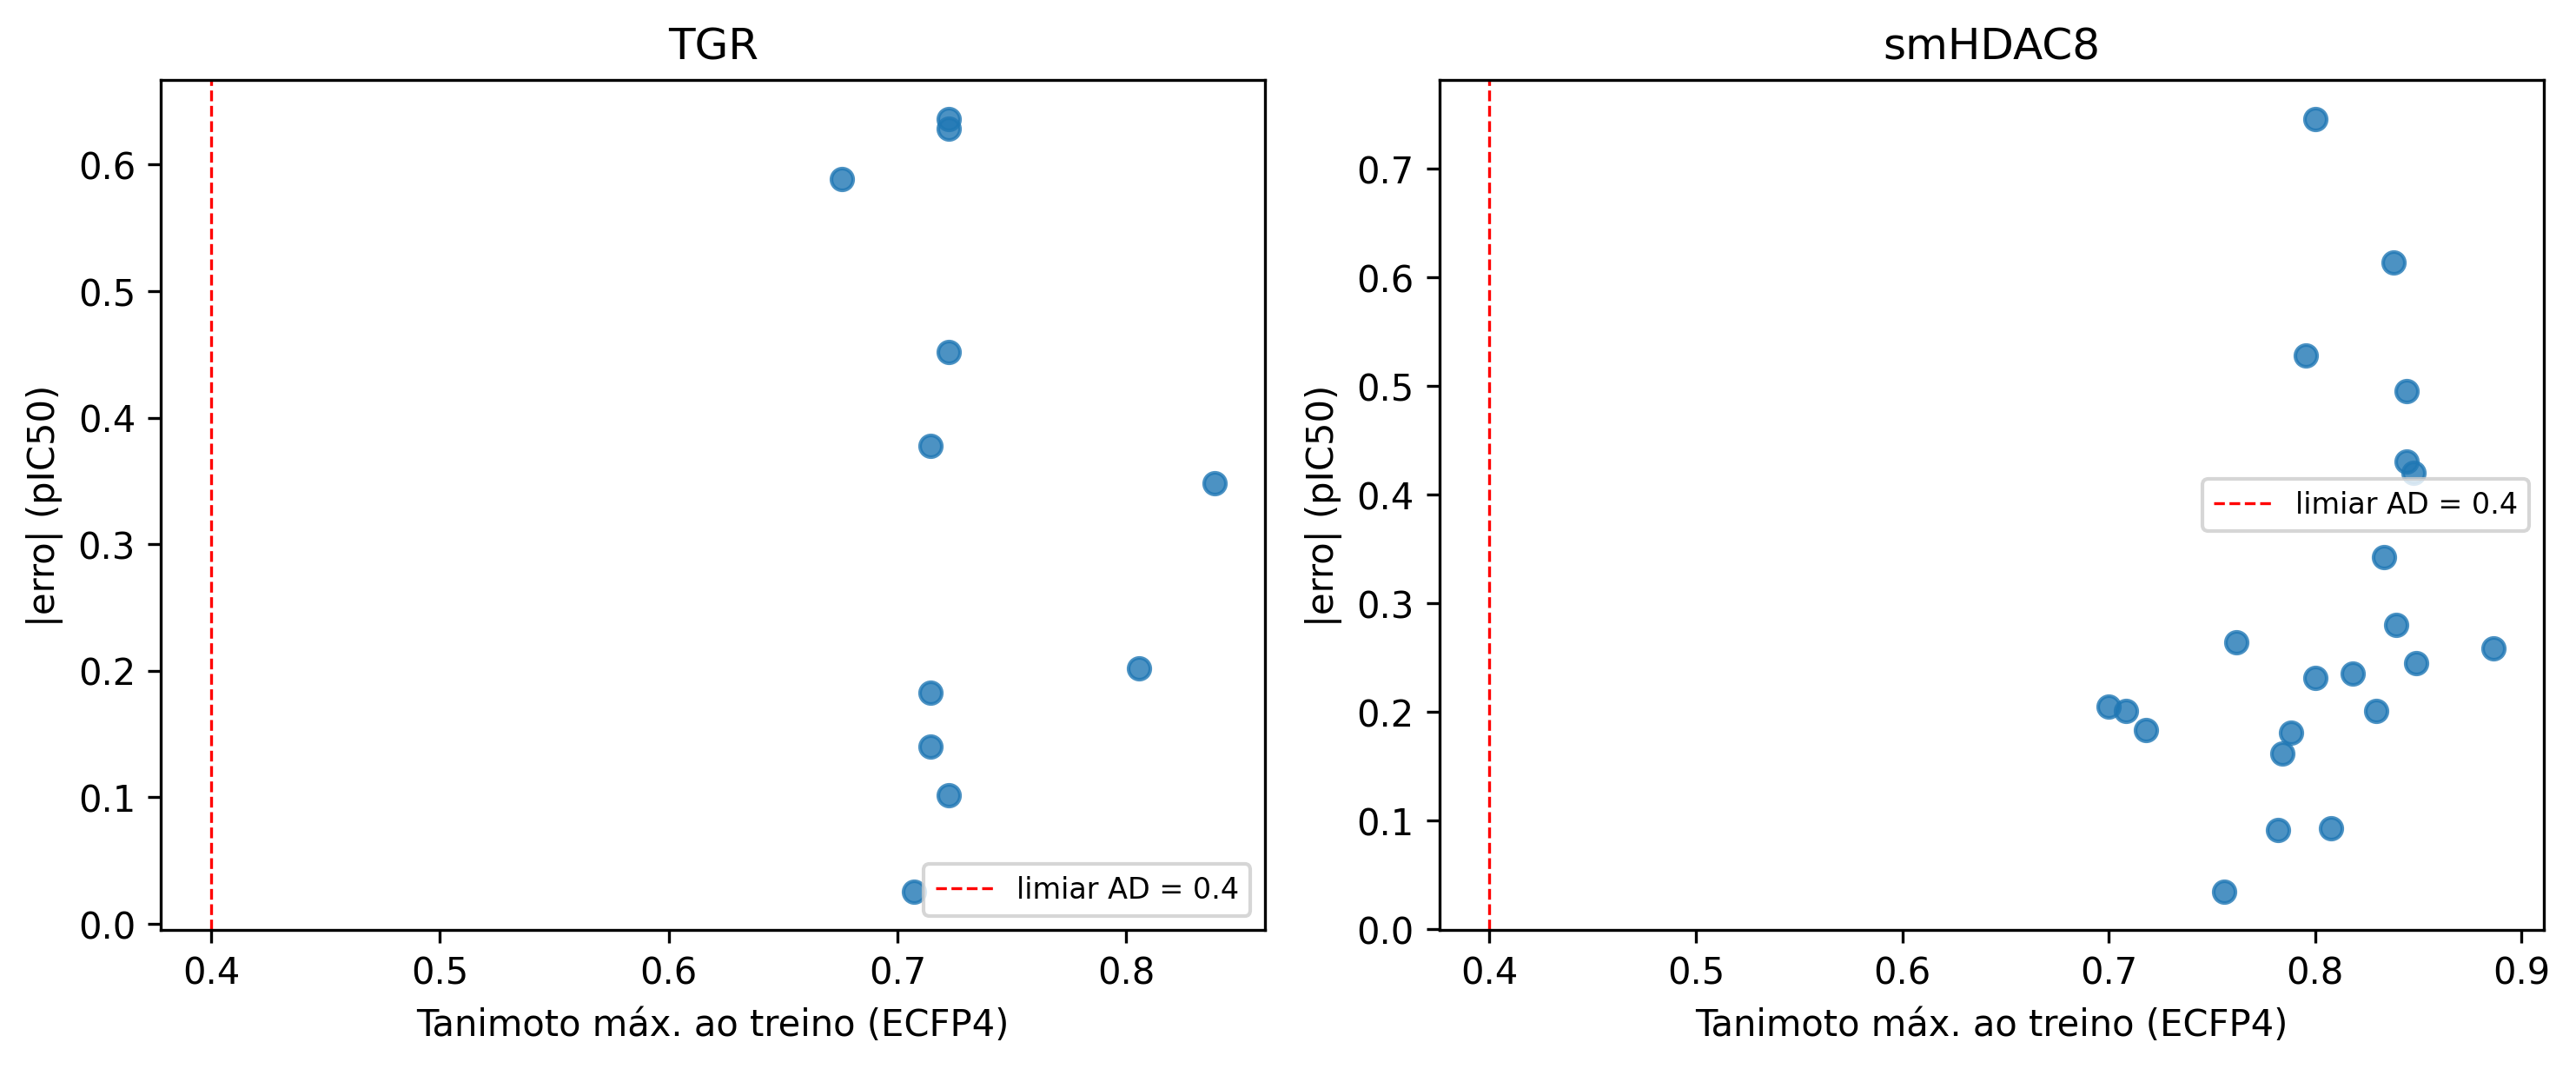


================ DETALHAMENTO DE DESEMPENHO DOS MODELOS ================

[1. Funil de Curadoria e Filtros]


,TGR,smHDAC8
1. registros IC50 brutos (ChEMBL),59,260
"2. com valor > 0, unidade nM e SMILES",58,258
3. SMILES padronizado com sucesso,58,258
dos quais censurados (relação ≠ '='),6,106
4. valores exatos ('=') — base da regressão,52,152
5. estruturas únicas (após padronização),51,107
6. sem réplicas discordantes (> 1 log),51,106
7. classificação: estruturas com rótulo inequívoco,57,203
ativos / inativos (IC50 ≤ 1 µM),19 / 38,74 / 129



[2. Análise de Propriedades Lipinski nos Treinos]


,alvo,N,0 violações,1 violação,≥2 violações,drug-like (≤1)
0,TGR,51,48,3,0,100.0%
1,smHDAC8,106,95,9,2,98.1%



[3. Regressão: Desempenho no Teste Externo]


,alvo,modelo,conjunto,R2_CV10x3,R2_cluster,viavel,R2,RMSE,MAE,Spearman,rho_cluster
0,TGR,baseline (média do treino),-,NaN,NaN,-,-1.363,0.729,0.661,NaN,NaN
1,TGR,PLS,FP2D+RDKIT2D+3D,-0.048,-0.092,False,0.186,0.428,0.356,0.400,0.292
2,TGR,RF,FP2D,0.217,0.201,False,0.305,0.395,0.335,0.782,0.421
3,TGR,HGB,FP2D+RDKIT2D+3D,0.003,0.134,False,0.579,0.308,0.256,0.782,0.392
4,TGR,consenso,-,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN
5,smHDAC8,baseline (média do treino),-,NaN,NaN,-,-0.858,0.667,0.603,NaN,NaN
6,smHDAC8,PLS,FP2D,0.610,0.056,False,0.622,0.300,0.252,0.401,0.200
7,smHDAC8,RF,FP2D+RDKIT2D+3D,0.611,-0.022,False,0.551,0.328,0.283,0.179,0.266
8,smHDAC8,HGB,RDKIT2D,0.662,0.061,False,0.514,0.341,0.293,0.229,0.350
9,smHDAC8,consenso,-,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN


... (2 outputs left out)


[5. Validação de Robustez por Y-Scrambling]


,modelo,R2_real,R2_perm_media,R2_perm_max,p_empirico,alvo
0,RF [FP2D],0.230,-0.212,0.072,0.048,TGR
1,HGB [RDKIT2D],0.688,-0.333,0.080,0.048,smHDAC8



[6. Domínio de Aplicabilidade no Conjunto de Teste]


,alvo,faixa,n,MAE
0,TGR,"<0,4",0,NaN
1,TGR,"0,4–0,6",0,NaN
2,TGR,"0,6–0,8",9,0.348
3,TGR,"≥0,8",2,0.275
0,smHDAC8,"<0,4",0,NaN
1,smHDAC8,"0,4–0,6",0,NaN
2,smHDAC8,"0,6–0,8",9,0.206
3,smHDAC8,"≥0,8",13,0.353


In [27]:
from IPython.display import Image, display
import glob

print('================ IMPRESSÃO DOS GRÁFICOS DO TCC (300 DPI) ================')
figuras = sorted(glob.glob('figuras/*.png'))
for fig_path in figuras:
    print(f'\nFigura: {fig_path}')
    display(Image(filename=fig_path, width=800))

print('\n================ DETALHAMENTO DE DESEMPENHO DOS MODELOS ================')
print('\n[1. Funil de Curadoria e Filtros]')
display(FUNIL)

print('\n[2. Análise de Propriedades Lipinski nos Treinos]')
display(LIP)

print('\n[3. Regressão: Desempenho no Teste Externo]')
display(TESTE.round(3))

print('\n[4. Classificação: Desempenho no Teste Externo]')
display(CLS_TAB.round(3))

print('\n[5. Validação de Robustez por Y-Scrambling]')
display(YS_TAB.round(3))

print('\n[6. Domínio de Aplicabilidade no Conjunto de Teste]')
display(AD_TAB.round(3))

In [28]:
# ---- 10. Validação reforçada do classificador smHDAC8
# (baseline do hidroxamato + IC por bootstrap de clusters + y-scrambling)
import numpy as np, pandas as pd
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, matthews_corrcoef, balanced_accuracy_score
from rdkit import Chem, DataStructs
from rdkit.ML.Cluster import Butina
from rdkit.Chem import rdFingerprintGenerator

ALVO = 'smHDAC8'
N_REP, N_PERM, N_BOOT, SIM_CLUSTER = 10, 100, 2000, 0.6   # N_PERM=100 pode demorar alguns minutos
rng = np.random.RandomState(42)

# ---------- 1) dados e rótulos ----------
src = CUR[ALVO].get('cls')
if not hasattr(src, 'columns'):
    src = CUR[ALVO]['reg']
src = src.reset_index(drop=True)
cands = [c for c in src.columns if c.lower() in ('ativo', 'active', 'classe', 'label', 'y_cls')]
if cands:
    y = src[cands[0]].astype(int).values
    print(f'rótulo lido da coluna "{cands[0]}"')
else:
    # Correção: mapeia os smiles do classificador para obter os respectivos pIC50 do conjunto 'reg'
    reg_df = CUR[ALVO]['reg'].set_index('smiles_std')
    y_pic50 = src['smiles_std'].map(reg_df['pIC50']).fillna(0.0).values
    y = (y_pic50 >= PIC50_THR).astype(int)
    print(f'rótulo derivado de pIC50 ≥ {PIC50_THR} obtido de CUR["{ALVO}"]["reg"]')
mols_t = [Chem.MolFromSmiles(s) for s in src['smiles_std']]
print(f'{ALVO}: N={len(y)} | activos: {y.sum()} ({y.mean():.1%})')

# ---------- 2) clusters (Butina, Tanimoto ≥ 0,6) ----------
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(m) for m in mols_t]
dist = []
for i in range(1, len(fps)):
    dist.extend([1 - s for s in DataStructs.BulkTanimotoSimilarity(fps[i], fps[:i])])
clusters = Butina.ClusterData(dist, len(fps), 1 - SIM_CLUSTER, isDistData=True)
groups = np.zeros(len(fps), dtype=int)
for k, c in enumerate(clusters):
    groups[list(c)] = k
print(f'{len(clusters)} clusters')

# ---------- 3) features e modelos (os mesmos do pipeline) ----------
modelos = dict(DEPLOY[ALVO]['cls'])
blocks = featurize(mols_t, sorted({b for fs, _ in modelos.values() for b in FEATURE_SETS[fs]}))
X = {nome: assemble(blocks, fs)[0] for nome, (fs, _) in modelos.items()}

def oof_proba(Xm, yv, est, seed):
    p = np.zeros(len(yv))
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for tr, te in cv.split(Xm, yv, groups):
        p[te] = clone(est).fit(Xm[tr], yv[tr]).predict_proba(Xm[te])[:, 1]
    return p

# ---------- 4) CV por clusters repetida + baseline do hidroxamato ----------
regra = np.array([int(any(m.HasSubstructMatch(p) for p in ZBG_PAT['hidroxamato'])) for m in mols_t])
print('\nRegra "tem hidroxamato" vs. rótulo:')
print(pd.crosstab(regra, y, rownames=['hidroxamato'], colnames=['activo']).to_string())

linhas, P_med = [], {}
for nome, (fs, est) in modelos.items():
    ps = [oof_proba(X[nome], y, est, s) for s in range(N_REP)]
    P_med[nome] = np.mean(ps, axis=0)
    aucs = [roc_auc_score(y, p) for p in ps]
    mccs = [matthews_corrcoef(y, (p >= .5).astype(int)) for p in ps]
    baccs = [balanced_accuracy_score(y, (p >= .5).astype(int)) for p in ps]
    linhas.append(dict(modelo=nome, AUC=np.mean(aucs), AUC_dp=np.std(aucs, ddof=1),
                       MCC=np.mean(mccs), BalAcc=np.mean(baccs)))
linhas.append(dict(modelo='regra: tem hidroxamato', AUC=roc_auc_score(y, regra), AUC_dp=np.nan,
                   MCC=matthews_corrcoef(y, regra), BalAcc=balanced_accuracy_score(y, regra)))
tab = pd.DataFrame(linhas)

# ---------- 5) IC 95% por bootstrap de clusters (modelo vs. regra, pareado) ----------
membros = {g: np.where(groups == g)[0] for g in np.unique(groups)}
ug = np.array(list(membros))
def boot(pa, pb, n=N_BOOT, seed=0):
    r = np.random.RandomState(seed); A, B, D = [], [], []
    for _ in range(n):
        i = np.concatenate([membros[g] for g in r.choice(ug, len(ug), replace=True)])
        if len(np.unique(y[i])) < 2:
            continue
        a, b = roc_auc_score(y[i], pa[i]), roc_auc_score(y[i], pb[i])
        A.append(a); B.append(b); D.append(a - b)
    q = lambda v: tuple(np.percentile(v, [2.5, 97.5]).round(3))
    return q(A), q(B), q(D)

ic = []
for nome in modelos:
    a, b, d = boot(P_med[nome], regra.astype(float))
    ic.append(dict(modelo=nome, IC95_AUC_modelo=a, IC95_AUC_regra=b, IC95_diferenca=d,
                   supera_regra=(d[0] > 0)))
ic = pd.DataFrame(ic)

# ---------- 6) y-scrambling do melhor modelo (CV por clusters) ----------
melhor = tab.iloc[:len(modelos)].sort_values('AUC', ascending=False)['modelo'].iloc[0]
est_m = modelos[melhor][1]
auc_real = roc_auc_score(y, oof_proba(X[melhor], y, est_m, 0))
perm = []
for k in range(N_PERM):
    yp = rng.permutation(y)
    perm.append(roc_auc_score(yp, oof_proba(X[melhor], yp, est_m, 0)))
perm = np.array(perm)
p_emp = (1 + np.sum(perm >= auc_real)) / (N_PERM + 1)

# ---------- 7) resultados ----------
print('\n=== CV por clusters (10 repetições) ===')
print(tab.round(3).to_string(index=False))
print('\n=== IC 95% (bootstrap de clusters) ===')
print(ic.to_string(index=False))
print(f'\n=== Y-scrambling ({melhor}, {N_PERM} permutações) ===')
print(f'AUC real = {auc_real:.3f} | permutado: média = {perm.mean():.3f}, máx = {perm.max():.3f} | p empírico = {p_emp:.4f}')
tab.to_csv('tabelas/validacao_reforcada_smHDAC8_cv.csv', index=False)
ic.to_csv('tabelas/validacao_reforcada_smHDAC8_ic.csv', index=False)

rótulo derivado de pIC50 ≥ 6.0 obtido de CUR["smHDAC8"]["reg"]
smHDAC8: N=203 | activos: 74 (36.5%)
67 clusters


3D:   0%|          | 0/203 [00:00<?, ?it/s]

RDKit2D:   0%|          | 0/203 [00:00<?, ?it/s]


Regra "tem hidroxamato" vs. rótulo:
activo        0   1
hidroxamato        
0            68   0
1            61  74

=== CV por clusters (10 repetições) ===
                modelo   AUC  AUC_dp   MCC  BalAcc
                    RF 0.982   0.004 0.848   0.923
                   HGB 0.975   0.005 0.812   0.905
regra: tem hidroxamato 0.764     NaN 0.538   0.764

=== IC 95% (bootstrap de clusters) ===
modelo IC95_AUC_modelo IC95_AUC_regra IC95_diferenca  supera_regra
    RF  (0.945, 0.994)  (0.688, 0.87) (0.105, 0.292)          True
   HGB  (0.934, 0.993)  (0.688, 0.87) (0.101, 0.288)          True

=== Y-scrambling (RF, 100 permutações) ===
AUC real = 0.986 | permutado: média = 0.494, máx = 0.606 | p empírico = 0.0099


In [29]:
%pip install -q rdkit

In [30]:
from urllib.parse import quote
from IPython.display import HTML, display

SEEDS_SMHDAC8 = {
    'CHEMBL3797843': 'O=C(Nc1cc(C(=O)NO)ccc1Cl)c1ccccc1',
    'CHEMBL3800394': 'COc1ccc(C(=O)NO)cc1NC(=O)c1ccc(-c2ccccc2)cc1',
    'CHEMBL3799246': 'CCOc1ccc(C(=O)NO)cc1NC(=O)c1ccc(-c2ccccc2)cc1',
    'CHEMBL2178342': 'ONC(=O)c1cccc(-c2cn(CSc3ccccc3)nn2)c1',
    'CHEMBL3798183': 'Cc1ccc(C(=O)NO)cc1NC(=O)c1ccc2ccccc2n1',
    'CHEMBL4160522': 'O=C(Nc1cc(C(=O)NO)ccc1Cl)c1cccc2ccsc12',
    'CHEMBL4867041': 'CCOc1ccc(C(=O)NO)cc1NC(=O)c1ccc(Cl)cc1Cl',
    'CHEMBL4855490': 'COc1ccc(C(=O)NO)cc1NC(=O)c1ccc(-c2ccccc2)cc1Cl',
}
itens = []
for nome, smi in SEEDS_SMHDAC8.items():
    url = f"https://zinc20.docking.org/substances.csv?ecfp4_fp-tanimoto-40={quote(smi, safe='')}&count=all"
    itens.append(f'<li><a href="{url}" target="_blank">{nome}</a></li>')
display(HTML('<ol>' + ''.join(itens) + '</ol>'))

In [31]:
import os
import pandas as pd
from google.colab import files

up = files.upload()
dfs = []
for nome in up:
    try:
        d = pd.read_csv(nome)
    except Exception as e:
        print(nome, '-> erro:', e)
        continue
    print(nome, d.shape)
    dfs.append(d[['smiles', 'zinc_id']])

lib = pd.concat(dfs).drop_duplicates('zinc_id').reset_index(drop=True)
os.makedirs('zinc_libs', exist_ok=True)
lib.to_csv('zinc_libs/smhdac8_zinc20.smi', sep=' ', header=False, index=False)
print('Total único:', len(lib))

Saving substances (8).csv to substances (8).csv
Saving substances (7).csv to substances (7).csv
Saving substances (6).csv to substances (6).csv
Saving substances (5).csv to substances (5).csv
Saving substances (4).csv to substances (4).csv
Saving substances (3).csv to substances (3).csv
Saving substances (2).csv to substances (2).csv
Saving substances (1).csv to substances (1).csv
substances (8).csv (30, 2)
substances (7).csv (120, 2)
substances (6).csv (25, 2)
substances (5).csv (25, 2)
substances (4).csv (4, 2)
substances (3).csv (42, 2)
substances (2).csv (88, 2)
substances (1).csv (25, 2)
Total único: 326


In [32]:
 def read_smi(path):
      """Lê ficheiro .smi (SMILES + zinc_id separados por espaço)"""
      return pd.read_csv(path, sep=r'\s+', header=None, names=['smiles', 'zinc_id'])

In [33]:
import glob
LIB_PZQ = LIB.copy() if 'LIB' in globals() else None

libs = []
for p in sorted(glob.glob('zinc_libs/smhdac8_*.smi')):
    d = read_smi(p)
    d['origem'] = os.path.basename(p)
    libs.append(d)
    print(os.path.basename(p), len(d))
LIB = pd.concat(libs, ignore_index=True)
print('Total (bruto):', len(LIB))

smhdac8_zinc20.smi 326
Total (bruto): 326


In [34]:
# ---- 9d. Padronização, propriedades e domínio de aplicabilidade ----
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors, AllChem
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
from rdkit.Chem import Descriptors, Lipinski
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
import numpy as np
import pandas as pd
import joblib

# Inicializa os componentes de padronização do RDKit de forma robusta
_FRAG = rdMolStandardize.LargestFragmentChooser()
_UNCH = rdMolStandardize.Uncharger()
_TAUT = rdMolStandardize.TautomerEnumerator()

def standardize(smi):
    try:
        m = Chem.MolFromSmiles(smi)
        if m is None:
            return None
        m = _FRAG.choose(m)
        m = _TAUT.Canonicalize(m)
        m = _UNCH.uncharge(m)
        return Chem.MolToSmiles(m)
    except Exception:
        return None

# 1) Padronização
def standardize_smi(smi):
    return standardize(smi)

print("Padronizando biblioteca...")
# Garantimos a limpeza e reindexação completa da LIB de entrada
LIB = LIB.copy().reset_index(drop=True)
# Se as colunas 'smiles_std' ou de propriedades já existirem por execuções anteriores, nós as removemos para evitar duplicatas
cols_to_drop = ['smiles_std', 'MW', 'LogP', 'HBD', 'HBA', 'TPSA', 'RotB', 'PAINS', 'Brenk', 'drug_like', 'maxsim_train', 'in_domain', 'prob_consenso', 'predito_ativo', 'ZBG', 'ZBG_forte', 'prioridade']
LIB = LIB.drop(columns=[c for c in cols_to_drop if c in LIB.columns])

LIB['smiles_std'] = LIB['smiles'].apply(standardize_smi)
LIB = LIB.dropna(subset=['smiles_std']).drop_duplicates('smiles_std').reset_index(drop=True)
print(f"Estruturas únicas padronizadas: {len(LIB)}")

# 2) Propriedades / Lipinski / PAINS / Brenk
def props(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None:
        return None
    mw = Descriptors.MolWt(m)
    logp = Descriptors.MolLogP(m)
    hbd = Lipinski.NumHDonors(m)
    hba = Lipinski.NumHAcceptors(m)
    tpsa = Descriptors.TPSA(m)
    rotb = Descriptors.NumRotatableBonds(m)

    # PAINS / Brenk
    params = FilterCatalogParams()
    params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
    params.AddCatalog(FilterCatalogParams.FilterCatalogs.BRENK)
    cat = FilterCatalog(params)
    matches = cat.GetMatches(m)
    pains = [str(m.GetDescription()) for m in matches if 'PAINS' in m.GetDescription()]
    brenk = [str(m.GetDescription()) for m in matches if 'BRENK' in m.GetDescription()]
    return pd.Series({
        'MW': mw, 'LogP': logp, 'HBD': hbd, 'HBA': hba,
        'TPSA': tpsa, 'RotB': rotb,
        'PAINS': '; '.join(pains) if pains else '',
        'Brenk': '; '.join(brenk) if brenk else '',
        'drug_like': int(mw <= 500 and logp <= 5 and hbd <= 5 and hba <= 10)
    })

print("Calculando propriedades...")
# Aplica a função de propriedades e reconstrói o índice de ambos os DataFrames antes da concatenação
LIB = LIB.reset_index(drop=True)
props_df = LIB['smiles_std'].apply(props).reset_index(drop=True)
LIB = pd.concat([LIB, props_df], axis=1).reset_index(drop=True)

# Remove qualquer coluna duplicada acidental no eixo das colunas
LIB = LIB.loc[:, ~LIB.columns.duplicated()]

# Filtra e reindexa com segurança
LIB_dl = LIB[LIB['drug_like'] == 1].copy().reset_index(drop=True)
print(f"Drug-like (Lipinski ≤1 violação): {len(LIB_dl)}")

# 3) Domínio de aplicabilidade (Tanimoto ao treino smHDAC8)
train_fps_raw = None
if 'FEATS' in globals() and 'smHDAC8' in FEATS:
    train_fps_raw = FEATS['smHDAC8']['blocks']['ecfp4'][0]
    print(f"Fingerprints de treino smHDAC8 obtidas da memória: {len(train_fps_raw)}")

if train_fps_raw is not None and len(LIB_dl) > 0:
    fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

    def max_tanimoto_to_train(smi):
        m = Chem.MolFromSmiles(smi)
        if m is None:
            return 0.0
        fp = fpgen.GetFingerprintAsNumPy(m).astype(np.float32)
        inter = train_fps_raw @ fp
        union = train_fps_raw.sum(axis=1) + fp.sum() - inter
        sims = inter / np.maximum(union, 1)
        return float(sims.max())

    print("Calculando similaridade máxima ao treino...")
    LIB_dl['maxsim_train'] = LIB_dl['smiles_std'].apply(max_tanimoto_to_train)
    LIB_dl['in_domain'] = LIB_dl['maxsim_train'] >= 0.4
    print(f"Com maxsim ≥ 0.4 (no domínio): {LIB_dl['in_domain'].sum()} / {len(LIB_dl)}")
    print(f"Distribuição maxsim: min={LIB_dl['maxsim_train'].min():.3f}, mediana={LIB_dl['maxsim_train'].median():.3f}, max={LIB_dl['maxsim_train'].max():.3f}")
else:
    LIB_dl['maxsim_train'] = np.nan
    LIB_dl['in_domain'] = False

# 4) Triagem com o classificador consenso viável carregado de DEPLOY
modelos_disponiveis = False
if 'DEPLOY' in globals() and 'smHDAC8' in DEPLOY and DEPLOY['smHDAC8']['cls']:
    modelos_disponiveis = True
    print("Modelos de classificação viáveis localizados na memória (DEPLOY).")

if modelos_disponiveis and len(LIB_dl) > 0:
    mols_dl = [Chem.MolFromSmiles(s) for s in LIB_dl['smiles_std']]
    sets_necessarios = {fs for fs, _ in DEPLOY['smHDAC8']['cls'].values()}
    blocks_lib = featurize(mols_dl, sorted({b for s in sets_necessarios for b in FEATURE_SETS[s]}))

    probs = []
    for mn, (fs, est) in DEPLOY['smHDAC8']['cls'].items():
        X_sub, _ = assemble(blocks_lib, fs)
        prob = est.predict_proba(X_sub)[:, 1]
        LIB_dl[f'prob_{mn}'] = prob
        probs.append(prob)

    prob_consenso = np.mean(probs, axis=0)
    LIB_dl['prob_consenso'] = prob_consenso
    LIB_dl['predito_ativo'] = (prob_consenso >= 0.5).astype(int)

    # Filtro ZBG para HDAC8
    ZBG_PAT = {k: [Chem.MolFromSmarts(x) for x in v] for k, v in ZBG.items()}
    zb = [[k for k, ps in ZBG_PAT.items() if any(m.HasSubstructMatch(p) for p in ps)] for m in mols_dl]
    LIB_dl['ZBG'] = ['; '.join(z) for z in zb]
    LIB_dl['ZBG_forte'] = [any(k in ZBG_FORTE for k in z) for z in zb]

    # Prioridades
    ativo = LIB_dl['prob_consenso'] >= 0.5
    zbg_ok = LIB_dl['ZBG_forte']
    limpo = LIB_dl['PAINS'] == ''
    LIB_dl['prioridade'] = np.where(LIB_dl['in_domain'] & ativo & limpo & zbg_ok, 'A',
                                    np.where(ativo & limpo, 'B', 'C'))

    # Filtra e ordena resultados finais de forma robusta
    hits = LIB_dl.sort_values(['prioridade', 'prob_consenso'], ascending=[True, False]).copy().reset_index(drop=True)
    print(f"\n=== RESULTADO DA TRIAGEM VIRTUAL (smHDAC8) ===")
    print(f"Total avaliado: {len(hits)}")
    print(f"Prioridade A: {(hits['prioridade'] == 'A').sum()} | Prioridade B: {(hits['prioridade'] == 'B').sum()} | C: {(hits['prioridade'] == 'C').sum()}")

    # Top 20
    cols_show = ['zinc_id', 'smiles_std', 'prob_consenso', 'maxsim_train', 'MW', 'LogP', 'ZBG', 'PAINS', 'prioridade']
    print(hits.head(20)[cols_show].to_string(index=False))

    # Salva resultados
    hits.to_csv('smhdac8_hits_zinc20.csv', index=False)
    print("\nSalvo com sucesso em: smhdac8_hits_zinc20.csv")
else:
    print("Modelos não disponíveis em DEPLOY ou biblioteca de triagem vazia.")

Padronizando biblioteca...
Estruturas únicas padronizadas: 326
Calculando propriedades...
Drug-like (Lipinski ≤1 violação): 314
Fingerprints de treino smHDAC8 obtidas da memória: 204
Calculando similaridade máxima ao treino...
Com maxsim ≥ 0.4 (no domínio): 314 / 314
Distribuição maxsim: min=0.418, mediana=0.542, max=1.000
Modelos de classificação viáveis localizados na memória (DEPLOY).


3D:   0%|          | 0/314 [00:00<?, ?it/s]

RDKit2D:   0%|          | 0/314 [00:00<?, ?it/s]


=== RESULTADO DA TRIAGEM VIRTUAL (smHDAC8) ===
Total avaliado: 314
Prioridade A: 23 | Prioridade B: 136 | C: 155
         zinc_id                                    smiles_std  prob_consenso  maxsim_train      MW    LogP         ZBG PAINS prioridade
ZINC000653841632       COc1ccc(C(O)=NO)cc1NC(=O)c1ccc(Cl)cc1Cl       0.999225      1.000000 355.177 3.94810 hidroxamato                A
ZINC000653841628         COc1ccc(C(O)=NO)cc1NC(=O)c1ccc(Cl)cc1       0.999225      1.000000 320.732 3.29470 hidroxamato                A
ZINC001857634508        O=C(Nc1cc(C(O)=NO)ccc1Cl)c1cccc2ccsc12       0.999215      1.000000 346.795 4.50080 hidroxamato                A
ZINC000653852859           COc1ccc(C(O)=NO)cc1NC(=O)c1ccccc1Cl       0.999155      1.000000 320.732 3.29470 hidroxamato                A
ZINC000653841655  COc1ccc(C(O)=NO)cc1NC(=O)c1ccc(-c2ccccc2)cc1       0.999080      1.000000 362.385 4.30830 hidroxamato                A
ZINC000653847623            CCOc1ccc(C(O)=NO)cc1NC(=O)c1ccccc1  

In [35]:
import os
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from rdkit import DataStructs

# Criando pasta para salvar os insumos de docking
os.makedirs('preparacao_docking', exist_ok=True)

print("=== PREPARANDO SUBSTÂNCIAS PARA DOCKING ===")

# Gerador de fingerprints de Morgan unificado
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# 1) Preparação para TGR
tgr_csv_path = 'tabelas/priorizacao_TGR_similaridade.csv'
if os.path.exists(tgr_csv_path):
    res_tgr_disk = pd.read_csv(tgr_csv_path)
    tgr_docking = res_tgr_disk[res_tgr_disk['prioridade_TGR'].isin(['A', 'B'])][['smiles_std', 'zinc_id']].copy()
    tgr_path = 'preparacao_docking/shortlist_TGR_para_docking.smi'
    tgr_docking.to_csv(tgr_path, sep=' ', header=False, index=False)
    print(f"-> TGR: {len(tgr_docking)} compostos de prioridade A/B salvos de '{tgr_csv_path}'")
elif 'LIB' in globals() and LIB is not None and len(LIB) > 0:
    # Reconstrói a análise de TGR dinamicamente se a biblioteca global estiver na memória
    seeds_tgr = [
        'NC(=O)c1c(C(=O)N2CC(=O)N3CCc4ccccc4C3C2)no[n+]1[O-]',
        'O=C(c1cccs1)c1no[n+]([O-])c1C(=O)c1cccs1',
        'COc1ccc([N+](=O)[O-])c(S(=O)(=O)c2ccc(Cl)cc2)n1',
        'N#Cc1c(C(=O)c2cccs2)no[n+]1[O-]',
        'NC(=O)c1c(COc2ccc3c(c2)C2CN(C(=O)C4CCCCC4)CC(=O)N2CC3)no[n+]1[O-]',
        'COc1ccc(C(=O)c2no[n+]([O-])c2C(=O)c2ccc(OC)cc2)cc1',
        'O=Cc1c(-c2ccccc2)no[n+]1[O-]',
        'COc1ccc(C(Nc2cc(C)ccn2)c2ccc3ccc(C)nc3c2O)cc1'
    ]
    seed_mols = [Chem.MolFromSmiles(s) for s in seeds_tgr]
    seed_fps = [fpgen.GetFingerprint(m) for m in seed_mols if m is not None]

    def calc_max_sim_tgr(smi):
        m = Chem.MolFromSmiles(smi)
        if m is None: return 0.0
        fp = fpgen.GetFingerprint(m)
        return max(DataStructs.TanimotoSimilarity(fp, sf) for sf in seed_fps)

    LIB_tgr = LIB.copy()
    if 'smiles_std' not in LIB_tgr.columns:
        LIB_tgr['smiles_std'] = LIB_tgr['smiles']

    LIB_tgr['maxsim_TGR'] = LIB_tgr['smiles_std'].apply(calc_max_sim_tgr)
    tgr_docking = LIB_tgr[LIB_tgr['maxsim_TGR'] >= 0.35][['smiles_std', 'zinc_id']].copy()

    if len(tgr_docking) == 0:
        tgr_docking = LIB_tgr[LIB_tgr['maxsim_TGR'] >= 0.25][['smiles_std', 'zinc_id']].copy()

    tgr_path = 'preparacao_docking/shortlist_TGR_para_docking.smi'
    tgr_docking.to_csv(tgr_path, sep=' ', header=False, index=False)
    print(f"-> TGR: {len(tgr_docking)} compostos selecionados dinamicamente salvos em '{tgr_path}'")
else:
    # Último recurso: Copiar diretamente o arquivo de backup disponível no workspace
    backup_tgr = 'pzq_zinc20.smi'
    if os.path.exists(backup_tgr):
        tgr_docking = pd.read_csv(backup_tgr, sep=' ', header=None, names=['smiles_std', 'zinc_id'])
        tgr_path = 'preparacao_docking/shortlist_TGR_para_docking.smi'
        tgr_docking.to_csv(tgr_path, sep=' ', header=False, index=False)
        print(f"-> TGR: {len(tgr_docking)} compostos do backup salvos em '{tgr_path}'")
    else:
        print("-> TGR: Arquivo de priorização ou sementes de TGR não localizados.")

# 2) Preparação para smHDAC8
if 'LIB_dl' in globals() and LIB_dl is not None:
    LIB_dl = LIB_dl.copy()

    # Garantindo similaridade máxima às sementes ativas conhecidas
    seeds_smhdac8 = [
        'O=C(Nc1cc(C(=O)NO)ccc1Cl)c1ccccc1',
        'COc1ccc(C(=O)NO)cc1NC(=O)c1ccc(-c2ccccc2)cc1',
        'CCOc1ccc(C(=O)NO)cc1NC(=O)c1ccc(-c2ccccc2)cc1',
        'ONC(=O)c1cccc(-c2cn(CSc3ccccc3)nn2)c1',
        'Cc1ccc(C(=O)NO)cc1NC(=O)c1ccc2ccccc2n1',
        'O=C(Nc1cc(C(=O)NO)ccc1Cl)c1cccc2ccsc12',
        'CCOc1ccc(C(=O)NO)cc1NC(=O)c1ccc(Cl)cc1Cl',
        'COc1ccc(C(=O)NO)cc1NC(=O)c1ccc(-c2ccccc2)cc1Cl'
    ]
    seed_mols = [Chem.MolFromSmiles(s) for s in seeds_smhdac8]
    seed_fps = [fpgen.GetFingerprint(m) for m in seed_mols if m is not None]

    def calc_max_sim(smi):
        m = Chem.MolFromSmiles(smi)
        if m is None: return 0.0
        fp = fpgen.GetFingerprint(m)
        return max(DataStructs.TanimotoSimilarity(fp, sf) for sf in seed_fps)

    LIB_dl['maxsim_train'] = LIB_dl['smiles_std'].apply(calc_max_sim)

    # Filtro flexível para expandir ligantes viáveis
    smhdac8_docking = LIB_dl[
        (LIB_dl['drug_like'] == 1) &
        (LIB_dl['PAINS'] == '') &
        (LIB_dl['maxsim_train'] >= 0.35)
    ][['smiles_std', 'zinc_id']].copy()

    if len(smhdac8_docking) == 0:
        smhdac8_docking = LIB_dl[
            (LIB_dl['drug_like'] == 1) &
            (LIB_dl['maxsim_train'] >= 0.25)
        ][['smiles_std', 'zinc_id']].copy()

    hdac8_path = 'preparacao_docking/shortlist_smHDAC8_para_docking.smi'
    smhdac8_docking.to_csv(hdac8_path, sep=' ', header=False, index=False)
    print(f"-> smHDAC8: {len(smhdac8_docking)} compostos selecionados salvos com sucesso em '{hdac8_path}'")
else:
    print("-> smHDAC8: Biblioteca 'LIB_dl' não localizada na memória do kernel.")

print("\nPreparação concluída com sucesso!")

=== PREPARANDO SUBSTÂNCIAS PARA DOCKING ===
-> TGR: 64 compostos de prioridade A/B salvos de 'tabelas/priorizacao_TGR_similaridade.csv'
-> smHDAC8: 308 compostos selecionados salvos com sucesso em 'preparacao_docking/shortlist_smHDAC8_para_docking.smi'

Preparação concluída com sucesso!


### Visualização Físico-Química da Biblioteca smHDAC8

Este gráfico demonstra a distribuição de Peso Molecular (MW) e LogP da biblioteca ZINC curada para o alvo **smHDAC8**, caracterizando o perfil de *drug-likeness* do espaço químico explorado.

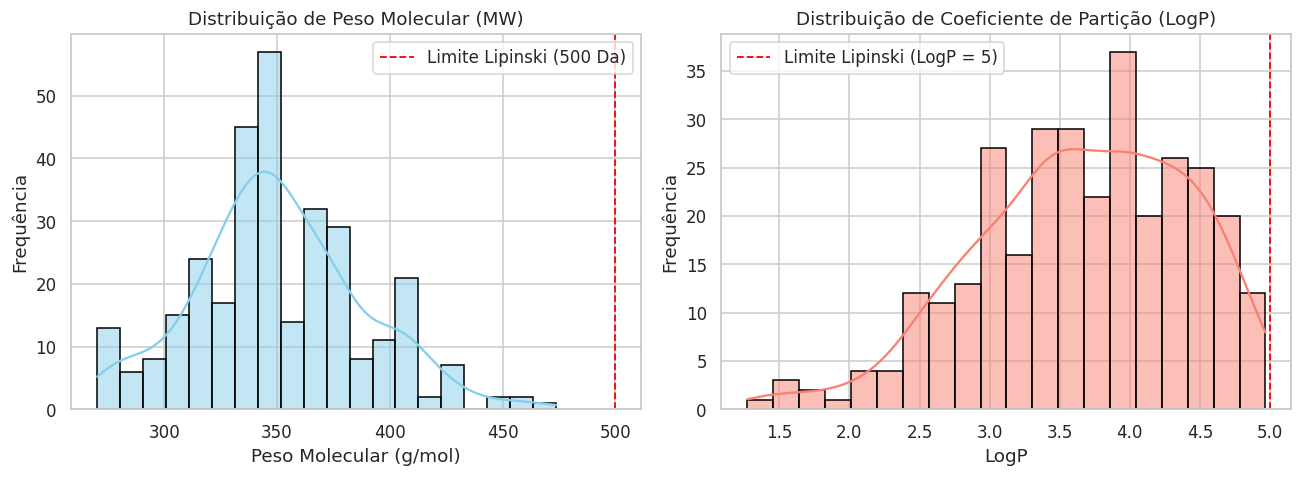

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configurações de estilo
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Distribuição de Peso Molecular (MW)
sns.histplot(LIB_dl['MW'], bins=20, kde=True, color='skyblue', edgecolor='black', ax=axes[0])
axes[0].axvline(500, color='red', linestyle='--', linewidth=1.2, label='Limite Lipinski (500 Da)')
axes[0].set_title('Distribuição de Peso Molecular (MW)')
axes[0].set_xlabel('Peso Molecular (g/mol)')
axes[0].set_ylabel('Frequência')
axes[0].legend()

# Distribuição de LogP
sns.histplot(LIB_dl['LogP'], bins=20, kde=True, color='salmon', edgecolor='black', ax=axes[1])
axes[1].axvline(5, color='red', linestyle='--', linewidth=1.2, label='Limite Lipinski (LogP = 5)')
axes[1].set_title('Distribuição de Coeficiente de Partição (LogP)')
axes[1].set_xlabel('LogP')
axes[1].set_ylabel('Frequência')
axes[1].legend()

plt.tight_layout()
os.makedirs('figuras', exist_ok=True)
plt.savefig('figuras/distribuicao_propriedades_smhdac8.png', dpi=300, bbox_inches='tight')
plt.show()

### Preparacao para docking

In [37]:
!pip install rdkit pandas numpy meeko dimorphite-dl


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [dimorphite-dl]


In [38]:
!apt-get update -qq
!apt-get install -y autodock-vina

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libboost-filesystem1.83.0 libboost-program-options1.83.0
  libboost-thread1.83.0
Suggested packages:
  autodock autogrid
The following NEW packages will be installed:
  autodock-vina libboost-filesystem1.83.0 libboost-program-options1.83.0
  libboost-thread1.83.0
0 upgraded, 4 newly installed, 0 to remove and 5 not upgraded.
Need to get 1,166 kB of archives.
After this operation, 7,820 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libboost-filesystem1.83.0 amd64 1.83.0-2.1ubuntu3.2 [284 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libboost-program-options1.83.0 amd64 1.

In [39]:
import os

print("Ficheiros disponíveis no ambiente:")

for ficheiro in os.listdir("/content"):
    print(ficheiro)

Ficheiros disponíveis no ambiente:
.config
zinc_libs
smhdac8_hits_zinc20.csv
figuras
substances (7).csv
substances.csv
models
preparacao_docking
substances (8).csv
substances (2).csv
substances (3).csv
resultados_TCC_v2_figuras.zip
docking_smHDAC8
substances (4).csv
resultados_TCC_v2_tabelas.zip
zinc
substances (6).csv
data
substances (5).csv
pzq_zinc20.smi
tabelas
substances (1).csv
sample_data


In [40]:
import pandas as pd
import os

# Caminhos corretos para os arquivos gerados na pasta de preparação
tgr_path = "preparacao_docking/shortlist_TGR_para_docking.smi"
hdac8_path = "preparacao_docking/shortlist_smHDAC8_para_docking.smi"

# Lendo os arquivos usando pd.read_csv com separador de espaços
if os.path.exists(tgr_path):
    df1 = pd.read_csv(tgr_path, sep=r'\s+', header=None, names=['smiles', 'zinc_id'])
    print("=== TGR Shortlist (Top 5) ===")
    print(df1.head())
else:
    print(f"Arquivo não encontrado: {tgr_path}")

print("\n")

if os.path.exists(hdac8_path):
    df2 = pd.read_csv(hdac8_path, sep=r'\s+', header=None, names=['smiles', 'zinc_id'])
    print("=== smHDAC8 Shortlist (Top 5) ===")
    print(df2.head())
    print(f"Total de compostos para smHDAC8: {len(df2)}")
else:
    print(f"Arquivo não encontrado: {hdac8_path}")

=== TGR Shortlist (Top 5) ===
                                            smiles           zinc_id
0    O=C(C1CCCCC1)N1CC(=O)N2CCc3ccc(O)cc3[C@@H]2C1  ZINC000082151414
1     O=C(C1CCCCC1)N1CC(=O)N2CCc3ccc(O)cc3[C@H]2C1  ZINC000082151416
2  Nc1ccc2c(c1)[C@@H]1CN(C(=O)C3CCCCC3)CC(=O)N1CC2  ZINC000028823655
3   Nc1ccc2c(c1)[C@H]1CN(C(=O)C3CCCCC3)CC(=O)N1CC2  ZINC000028823656
4       O=C(N1CCOCC1)N1CC(=O)N2CCc3ccccc3[C@@H]2C1  ZINC000036138040


=== smHDAC8 Shortlist (Top 5) ===
                                           smiles           zinc_id
0    COc1ccc(C(O)=NO)cc1NC(=O)c1ccc(-c2ccccc2)cc1  ZINC000653841655
1  CNC(=O)c1ccc(OC)c(NC(=O)c2ccc(-c3ccccc3)cc2)c1  ZINC000131363186
2     COc1ccc(C(=O)O)cc1NC(=O)c1ccc(-c2ccccc2)cc1  ZINC000020138849
3   CCOc1ccc(C(O)=NO)cc1NC(=O)c1ccc(-c2ccccc2)cc1  ZINC000653848662
4        COc1ccc(C(O)=NO)cc1OCc1ccc(-c2ccccc2)cc1  ZINC001857547630
Total de compostos para smHDAC8: 308


In [41]:

import os
import pandas as pd
from rdkit import Chem

# Caminhos dos ficheiros
tgr_path = "preparacao_docking/shortlist_TGR_para_docking.smi"
hdac8_path = "preparacao_docking/shortlist_smHDAC8_para_docking.smi"

def carregar_e_validar(caminho, nome):
    df = pd.read_csv(
        caminho,
        sep=r"\s+",
        header=None,
        names=["SMILES", "ZINC_ID"]
    )

    df["valido"] = df["SMILES"].apply(
        lambda s: Chem.MolFromSmiles(str(s)) is not None
    )

    print(f"\n===== {nome} =====")
    print("Total de moléculas:", len(df))
    print("Moléculas válidas:", df["valido"].sum())
    print("Moléculas inválidas:", (~df["valido"]).sum())
    print("ZINC_ID duplicados:", df["ZINC_ID"].duplicated().sum())

    return df

# Processar os dois alvos
df_tgr = carregar_e_validar(tgr_path, "TGR")
df_hdac8 = carregar_e_validar(hdac8_path, "smHDAC8")

# Guardar relatórios
df_tgr.to_csv("validacao_TGR.csv", index=False)
df_hdac8.to_csv("validacao_smHDAC8.csv", index=False)

print("\nValidação concluída!")



===== TGR =====
Total de moléculas: 64
Moléculas válidas: 64
Moléculas inválidas: 0
ZINC_ID duplicados: 0

===== smHDAC8 =====
Total de moléculas: 308
Moléculas válidas: 308
Moléculas inválidas: 0
ZINC_ID duplicados: 0

Validação concluída!


In [42]:

from rdkit import Chem
from rdkit.Chem import AllChem
import pandas as pd
import os
import math

os.makedirs("resultados_3D", exist_ok=True)

def gerar_estruturas_3d(df, nome, num_confs=10):

    writer = Chem.SDWriter(
        f"resultados_3D/{nome}_3D.sdf"
    )

    resultados = []

    for i, row in df.iterrows():

        smiles = str(row["SMILES"])
        zinc_id = str(row["ZINC_ID"])

        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            continue

        mol = Chem.AddHs(mol)

        params = AllChem.ETKDGv3()
        params.randomSeed = 42
        params.numThreads = 0

        conf_ids = AllChem.EmbedMultipleConfs(
            mol,
            numConfs=num_confs,
            params=params
        )

        if len(conf_ids) == 0:
            resultados.append({
                "ZINC_ID": zinc_id,
                "Status": "Falha na geração 3D"
            })
            continue

        # Minimização MMFF94
        if AllChem.MMFFHasAllMoleculeParams(mol):

            energies = AllChem.MMFFOptimizeMoleculeConfs(
                mol,
                numThreads=0,
                maxIters=1000
            )

            metodo = "MMFF94"

        elif AllChem.UFFHasAllMoleculeParams(mol):

            energies = AllChem.UFFOptimizeMoleculeConfs(
                mol,
                numThreads=0,
                maxIters=1000
            )

            metodo = "UFF"

        else:
            resultados.append({
                "ZINC_ID": zinc_id,
                "Status": "Sem parâmetros de otimização"
            })
            continue

        # Selecionar conformação de menor energia
        valid_energies = [
            (conf_ids[j], status, energy)
            for j, (status, energy) in enumerate(energies)
            if math.isfinite(energy)
        ]

        if not valid_energies:
            resultados.append({
                "ZINC_ID": zinc_id,
                "Status": "Falha na minimização"
            })
            continue

        best_conf, best_status, best_energy = min(
            valid_energies,
            key=lambda x: x[2]
        )

        mol.SetProp("_Name", zinc_id)
        mol.SetProp("ZINC_ID", zinc_id)
        mol.SetProp("SMILES", smiles)
        mol.SetProp("Metodo", metodo)
        mol.SetProp("Energia_kcal_mol", str(best_energy))

        writer.write(mol, confId=best_conf)

        resultados.append({
            "ZINC_ID": zinc_id,
            "Status": "Sucesso",
            "Metodo": metodo,
            "Energia_kcal_mol": best_energy,
            "Convergencia": best_status == 0,
            "Conformacoes_geradas": len(conf_ids)
        })

        if (i + 1) % 25 == 0:
            print(f"{nome}: {i+1}/{len(df)} processadas")

    writer.close()

    resultado_df = pd.DataFrame(resultados)

    resultado_df.to_csv(
        f"resultados_3D/{nome}_relatorio.csv",
        index=False
    )

    print(f"\n===== {nome} =====")
    print(resultado_df["Status"].value_counts())
    print("Total processado:", len(resultado_df))

    return resultado_df


# Gerar estruturas para os dois alvos
resultado_tgr = gerar_estruturas_3d(
    df_tgr, "TGR"
)

resultado_hdac8 = gerar_estruturas_3d(
    df_hdac8, "smHDAC8"
)

print("\nGERAÇÃO 3D CONCLUÍDA!")


TGR: 25/64 processadas
TGR: 50/64 processadas

===== TGR =====
Status
Sucesso    64
Name: count, dtype: int64
Total processado: 64
smHDAC8: 25/308 processadas
smHDAC8: 50/308 processadas
smHDAC8: 75/308 processadas
smHDAC8: 100/308 processadas
smHDAC8: 125/308 processadas
smHDAC8: 150/308 processadas
smHDAC8: 175/308 processadas
smHDAC8: 200/308 processadas
smHDAC8: 225/308 processadas
smHDAC8: 250/308 processadas
smHDAC8: 275/308 processadas
smHDAC8: 300/308 processadas

===== smHDAC8 =====
Status
Sucesso    308
Name: count, dtype: int64
Total processado: 308

GERAÇÃO 3D CONCLUÍDA!


In [43]:
from rdkit import Chem
import os

for nome in ["TGR", "smHDAC8"]:

    caminho = f"resultados_3D/{nome}_3D.sdf"

    suppl = Chem.SDMolSupplier(
        caminho,
        removeHs=False
    )

    moleculas = [m for m in suppl if m is not None]

    print(f"\n{nome}")
    print("Estruturas 3D válidas:", len(moleculas))
    print("Ficheiro:", caminho)


TGR
Estruturas 3D válidas: 64
Ficheiro: resultados_3D/TGR_3D.sdf

smHDAC8
Estruturas 3D válidas: 308
Ficheiro: resultados_3D/smHDAC8_3D.sdf


In [44]:
import os

print("A procurar ficheiros PDB...")

for raiz, pastas, ficheiros in os.walk("/content"):
    for ficheiro in ficheiros:
        if ficheiro.lower().endswith((".pdb", ".cif", ".mmcif")):
            print(os.path.join(raiz, ficheiro))

A procurar ficheiros PDB...


In [45]:
import os
import requests

os.makedirs("proteinas", exist_ok=True)

estruturas = {
    "TGR": "8PDD",
    "smHDAC8": "4BZ5"
}

for nome, pdb_id in estruturas.items():
    url = f"https://files.rcsb.org/download/{pdb_id}.pdb"
    caminho = f"proteinas/{nome}_{pdb_id}.pdb"

    resposta = requests.get(url)
    resposta.raise_for_status()

    with open(caminho, "w") as ficheiro:
        ficheiro.write(resposta.text)

    print(f"{nome}: descarregado para {caminho}")

TGR: descarregado para proteinas/TGR_8PDD.pdb
smHDAC8: descarregado para proteinas/smHDAC8_4BZ5.pdb


In [46]:
!pip -q install biopython vina meeko rdkit
!apt-get update -qq
!apt-get install -y -qq openbabel

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for vina (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for vina
error: failed-wheel-build-for-install

× Failed to build installable wheels for some pyproject.toml based projects
╰─> vina
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libboost-iostreams1.83.0:amd64.
(Reading database ... 122841 files and directories currently installed.)
Preparing to unpack .../libboost-iostreams1.83.0_1.83.0-2.1ubuntu3.2_amd64.deb ...
Unpacking libboost-iostreams1.83.0:amd

In [47]:
!apt-get install -y autodock-vina

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
autodock-vina is already the newest version (1.2.5-2build1).
0 upgraded, 0 newly installed, 0 to remove and 5 not upgraded.


In [48]:
!vina --version

AutoDock Vina v1.2.5


In [49]:
# Instala as dependências necessárias de forma individual para evitar que a falha de compilação da Vina afete os outros pacotes
!pip install -q biopython gemmi meeko

import Bio
import rdkit
import gemmi
import meeko

print("Biopython:", Bio.__version__)
print("RDKit:", rdkit.__version__)
print("Gemmi:", gemmi.__version__)
print("Meeko:", meeko.__version__)

Biopython: 1.88
RDKit: 2026.09.1
Gemmi: 0.7.5
Meeko: 0.8.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [50]:
from Bio.PDB import PDBParser
from collections import Counter

parser = PDBParser(QUIET=True)

ficheiros = {
    "TGR": "proteinas/TGR_8PDD.pdb",
    "smHDAC8": "proteinas/smHDAC8_4BZ5.pdb"
}

for nome, caminho in ficheiros.items():

    estrutura = parser.get_structure(nome, caminho)

    print("\n", "="*50)
    print("PROTEÍNA:", nome)

    for modelo in estrutura:
        for cadeia in modelo:

            residuos = list(cadeia.get_residues())

            aminoacidos = [
                r for r in residuos if r.id[0] == " "
            ]

            hetero = [
                r for r in residuos if r.id[0] != " "
            ]

            print("\nCadeia:", cadeia.id)
            print("Resíduos:", len(aminoacidos))
            print(
                "Componentes não proteicos:",
                Counter(r.resname for r in hetero)
            )


PROTEÍNA: TGR

Cadeia: A
Resíduos: 588
Componentes não proteicos: Counter({'HOH': 733, 'GOL': 9, 'MG': 2, 'FAD': 1})

Cadeia: B
Resíduos: 588
Componentes não proteicos: Counter({'HOH': 663, 'GOL': 6, 'FAD': 1, 'MG': 1})


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



PROTEÍNA: smHDAC8

Cadeia: A
Resíduos: 404
Componentes não proteicos: Counter({'HOH': 357, 'K': 2, 'ZN': 1, 'TLA': 1})

Cadeia: B
Resíduos: 419
Componentes não proteicos: Counter({'HOH': 416, 'K': 2, 'ZN': 1, 'TLA': 1})

Cadeia: C
Resíduos: 418
Componentes não proteicos: Counter({'HOH': 434, 'K': 2, 'ZN': 1, 'TLA': 1})

Cadeia: D
Resíduos: 404
Componentes não proteicos: Counter({'HOH': 325, 'K': 2, 'ZN': 1, 'TLA': 1})


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [51]:
from Bio.PDB import PDBParser
import numpy as np

parser = PDBParser(QUIET=True)

ficheiros = {
    "TGR": "proteinas/TGR_8PDD.pdb",
    "smHDAC8": "proteinas/smHDAC8_4BZ5.pdb"
}

for nome, caminho in ficheiros.items():

    estrutura = parser.get_structure(nome, caminho)

    print("\n" + "="*60)
    print("ANÁLISE:", nome)

    modelo = estrutura[0]

    for cadeia in modelo:

        print(f"\nCadeia {cadeia.id}")

        for residuo in cadeia:

            if residuo.id[0] == " ":
                continue

            codigo = residuo.resname

            if codigo == "HOH":
                continue

            atomos = list(residuo.get_atoms())

            coordenadas = np.array([
                atomo.coord for atomo in atomos
            ])

            centro = coordenadas.mean(axis=0)

            print(
                f"Componente: {codigo} | "
                f"Átomos: {len(atomos)} | "
                f"Centro: {np.round(centro, 2)}"
            )

            if codigo == "ZN":
                print("  Coordenada do zinco:", np.round(centro, 3))


ANÁLISE: TGR

Cadeia A
Componente: FAD | Átomos: 53 | Centro: [ 7.3  -2.84 57.31]
Componente: MG | Átomos: 1 | Centro: [  7.42 -23.58  17.45]
Componente: MG | Átomos: 1 | Centro: [-3.24  8.25 40.29]
Componente: GOL | Átomos: 6 | Centro: [ 1.44  2.66 47.73]
Componente: GOL | Átomos: 6 | Centro: [ 1.71 12.78 42.26]
Componente: GOL | Átomos: 6 | Centro: [15.2  19.22 61.1 ]
Componente: GOL | Átomos: 6 | Centro: [-0.85 -8.91 65.84]
Componente: GOL | Átomos: 6 | Centro: [21.24 10.01 48.15]
Componente: GOL | Átomos: 6 | Centro: [36.16 32.25 73.07]
Componente: GOL | Átomos: 6 | Centro: [-2.15 -2.35 51.08]
Componente: GOL | Átomos: 6 | Centro: [-12.04  -5.07  38.35]
Componente: GOL | Átomos: 6 | Centro: [30.52 10.1  69.68]

Cadeia B
Componente: FAD | Átomos: 53 | Centro: [21.09 -4.62  8.25]
Componente: MG | Átomos: 1 | Centro: [ 20.2  -22.87  49.16]
Componente: GOL | Átomos: 6 | Centro: [27.37  1.09 17.53]
Componente: GOL | Átomos: 6 | Centro: [30.73 -4.38 14.41]
Componente: GOL | Átomos: 6 | 

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



ANÁLISE: smHDAC8

Cadeia A
Componente: ZN | Átomos: 1 | Centro: [46.82 30.05 87.5 ]
  Coordenada do zinco: [46.824 30.049 87.498]
Componente: K | Átomos: 1 | Centro: [48.46 13.82 75.21]
Componente: K | Átomos: 1 | Centro: [46.26 22.94 86.91]
Componente: TLA | Átomos: 14 | Centro: [46.75 32.7  85.37]

Cadeia B
Componente: ZN | Átomos: 1 | Centro: [82.07 37.2  69.13]
  Coordenada do zinco: [82.066 37.196 69.129]
Componente: K | Átomos: 1 | Centro: [83.79 53.35 81.45]
Componente: K | Átomos: 1 | Centro: [81.51 44.33 69.73]
Componente: TLA | Átomos: 14 | Centro: [82.15 34.59 71.22]

Cadeia C
Componente: ZN | Átomos: 1 | Centro: [50.96  8.5  42.06]
  Coordenada do zinco: [50.962  8.5   42.065]
Componente: K | Átomos: 1 | Centro: [43.93  9.61 41.46]
Componente: K | Átomos: 1 | Centro: [34.68  8.01 29.68]
Componente: TLA | Átomos: 14 | Centro: [53.64  8.36 39.91]

Cadeia D
Componente: ZN | Átomos: 1 | Centro: [60.69 43.15 23.76]
  Coordenada do zinco: [60.694 43.149 23.761]
Componente: K | Á

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [52]:
from Bio.PDB import PDBParser, NeighborSearch
import numpy as np

parser = PDBParser(QUIET=True)

ficheiros = {
    "TGR": ("proteinas/TGR_8PDD.pdb", "A", "FAD"),
    "smHDAC8": ("proteinas/smHDAC8_4BZ5.pdb", "A", "TLA")
}

for nome, (caminho, cadeia_id, ligando_id) in ficheiros.items():

    estrutura = parser.get_structure(nome, caminho)
    cadeia = estrutura[0][cadeia_id]

    ligando = [
        r for r in cadeia
        if r.resname == ligando_id
    ]

    print("\n" + "="*60)
    print(nome, "| Cadeia", cadeia_id, "|", ligando_id)

    if not ligando:
        print("Ligando não encontrado.")
        continue

    atomos_ligando = [
        a for r in ligando for a in r.get_atoms()
    ]

    centro = np.mean(
        [a.coord for a in atomos_ligando], axis=0
    )

    print("Centro do ligando:", np.round(centro, 3))

    atomos_proteina = [
        a for a in cadeia.get_atoms()
        if a.get_parent().id[0] == " "
    ]

    vizinhos = NeighborSearch(atomos_proteina)
    encontrados = vizinhos.search(centro, 8.0)

    residuos = {}

    for atomo in encontrados:
        residuo = atomo.get_parent()
        chave = (residuo.resname, residuo.id[1])

        distancia = np.linalg.norm(atomo.coord - centro)

        if chave not in residuos or distancia < residuos[chave]:
            residuos[chave] = distancia

    for (resname, numero), distancia in sorted(
        residuos.items(), key=lambda x: x[1]
    ):
        print(f"{resname} {numero}: {distancia:.2f} Å")


TGR | Cadeia A | FAD
Centro do ligando: [ 7.305 -2.838 57.305]
THR 153: 2.42 Å
CYS 154: 4.21 Å
ASP 433: 4.31 Å
GLY 152: 4.45 Å
ARG 393: 4.49 Å
GLY 258: 4.93 Å
GLU 259: 5.19 Å
SER 117: 5.50 Å
GLY 116: 5.75 Å
THR 442: 6.21 Å
GLY 151: 6.33 Å
THR 257: 6.33 Å
VAL 155: 6.80 Å
VAL 157: 6.81 Å
ALA 256: 6.96 Å
GLY 118: 7.10 Å
ARG 260: 7.44 Å
GLY 158: 7.44 Å
ALA 445: 7.50 Å
CYS 159: 7.63 Å
GLY 115: 7.78 Å
GLY 432: 7.84 Å
ASN 156: 7.92 Å
TRP 148: 7.98 Å


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



smHDAC8 | Cadeia A | TLA
Centro do ligando: [46.745 32.705 85.369]
HIS 188: 3.75 Å
LYS 20: 3.96 Å
HIS 142: 3.97 Å
GLY 150: 4.07 Å
ASP 285: 4.59 Å
GLY 339: 4.98 Å
ASP 186: 5.08 Å
PHE 216: 5.08 Å
HIS 141: 5.21 Å
HIS 292: 5.82 Å
PHE 21: 5.90 Å
CYS 152: 5.96 Å
PHE 151: 6.07 Å
GLY 340: 6.21 Å
TRP 140: 6.47 Å
GLY 338: 6.58 Å
SER 149: 6.78 Å
LEU 187: 7.43 Å
GLN 281: 7.43 Å
HIS 189: 7.99 Å


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [53]:
from Bio.PDB import PDBParser
import numpy as np

parser = PDBParser(QUIET=True)
estrutura = parser.get_structure(
    "TGR", "proteinas/TGR_8PDD.pdb"
)

cadeia = estrutura[0]["A"]

residuos_interesse = [153, 154, 159, 258, 259, 393, 433]

for numero in residuos_interesse:
    if numero in cadeia:
        residuo = cadeia[numero]
        atomos = list(residuo.get_atoms())

        centro = np.mean(
            [a.coord for a in atomos], axis=0
        )

        print(
            residuo.resname,
            numero,
            np.round(centro, 3)
        )

THR 153 [ 7.744 -5.947 56.643]
CYS 154 [10.512 -6.104 53.311]
CYS 159 [ 9.438 -7.276 49.398]
GLY 258 [ 4.407  0.31  61.172]
GLU 259 [ 1.266 -0.942 58.928]
ARG 393 [-0.595 -3.74  56.431]
ASP 433 [ 4.134  2.566 56.32 ]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [54]:
from Bio.PDB import PDBParser
import numpy as np

parser = PDBParser(QUIET=True)

estrutura = parser.get_structure(
    "TGR", "proteinas/TGR_8PDD.pdb"
)

cadeia = estrutura[0]["A"]

for numero in [154, 159]:

    residuo = cadeia[(" ", numero, " ")]

    print("\nResíduo:", residuo.resname, numero)

    for atomo in residuo:

        if atomo.element == "S":
            print(
                "Átomo:", atomo.name,
                "Coordenadas:",
                np.round(atomo.coord, 3)
            )


Resíduo: CYS 154
Átomo: SG Coordenadas: [11.204 -5.051 51.412]

Resíduo: CYS 159
Átomo: SG Coordenadas: [ 9.482 -4.762 50.245]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [55]:
import numpy as np

sg154 = np.array([11.204, -5.051, 51.412])
sg159 = np.array([9.482, -4.762, 50.245])

distancia = np.linalg.norm(sg154 - sg159)

print(f"Distância S-S: {distancia:.3f} Å")

if distancia < 2.3:
    print("Possível ligação dissulfureto.")
else:
    print("Verificar o estado redox e a estrutura experimental.")

Distância S-S: 2.100 Å
Possível ligação dissulfureto.


In [56]:
from Bio.PDB import PDBParser

parser = PDBParser(QUIET=True)
estrutura = parser.get_structure(
    "HDAC8", "proteinas/smHDAC8_4BZ5.pdb"
)

cadeia = estrutura[0]["A"]

for residuo in cadeia:
    if residuo.resname == "TLA":
        print("Ligando:", residuo.resname)

        for atomo in residuo:
            print(
                atomo.name,
                atomo.element,
                atomo.coord
            )

Ligando: TLA
O1 O [47.793 30.246 85.513]
O11 O [49.097 31.495 84.269]
C1 C [48.202 31.363 85.133]
C2 C [47.573 32.591 85.722]
O2 O [47.127 32.299 87.051]
C3 C [46.4   33.    84.835]
O3 O [45.599 31.848 84.564]
C4 C [45.541 34.055 85.474]
O4 O [46.072 35.126 85.846]
O41 O [44.317 33.819 85.602]
H2 H [48.31  33.407 85.74 ]
HA H [46.792 33.108 87.463]
H3 H [46.801 33.396 83.891]
HB H [44.811 32.112 84.069]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


utilizar uma estratégia de docking nos sítios catalíticos dos dois alvos, com validação por redocking.

O protocolo terá duas partes independentes, porque as proteínas apresentam características diferentes:
1. TGR: preservar o FAD e a ligação dissulfureto entre CYS154 e CYS159.
2. smHDAC8: preservar o zinco catalítico e utilizar o TLA como referência para localizar a bolsa de ligação.
Uma ressalva científica importante: o AutoDock Vina 1.2.5, com a função de pontuação convencional, não descreve adequadamente todas as interações de coordenação ao zinco. A documentação oficial apresenta um protocolo específico, AutoDock4Zn, com átomos pseudo-TZ e pontuação AD4. Vamos considerar essa abordagem para a smHDAC8, em vez de fingir que o zinco é tratado perfeitamente pelo Vina convencional.

In [57]:

import os

os.makedirs("receptores_trabalho", exist_ok=True)

ficheiros = {
    "TGR": {
        "entrada": "proteinas/TGR_8PDD.pdb",
        "hetero": ["FAD"]
    },
    "smHDAC8": {
        "entrada": "proteinas/smHDAC8_4BZ5.pdb",
        "hetero": ["ZN"]
    }
}

for nome, dados in ficheiros.items():

    entrada = dados["entrada"]
    saida = f"receptores_trabalho/{nome}_cadeiaA.pdb"

    with open(entrada, "r") as f:
        linhas = f.readlines()

    selecionadas = []

    for linha in linhas:

        registo = linha[:6].strip()

        if registo in ["ATOM", "HETATM"]:

            cadeia = linha[21:22]
            residuo = linha[17:20].strip()

            if cadeia == "A":

                if registo == "ATOM":
                    selecionadas.append(linha)

                elif residuo in dados["hetero"]:
                    selecionadas.append(linha)

        elif registo == "SSBOND":

            cadeia1 = linha[15:16]
            cadeia2 = linha[29:30]

            if cadeia1 == "A" and cadeia2 == "A":
                selecionadas.append(linha)

    with open(saida, "w") as f:
        f.writelines(selecionadas)
        f.write("END\n")

    print(f"\n{nome}")
    print("Ficheiro criado:", saida)
    print("Linhas selecionadas:", len(selecionadas))



TGR
Ficheiro criado: receptores_trabalho/TGR_cadeiaA.pdb
Linhas selecionadas: 4858

smHDAC8
Ficheiro criado: receptores_trabalho/smHDAC8_cadeiaA.pdb
Linhas selecionadas: 3240


In [58]:

from Bio.PDB import PDBParser
from collections import Counter

parser = PDBParser(QUIET=True)

ficheiros = {
    "TGR": "receptores_trabalho/TGR_cadeiaA.pdb",
    "smHDAC8": "receptores_trabalho/smHDAC8_cadeiaA.pdb"
}

for nome, caminho in ficheiros.items():

    estrutura = parser.get_structure(nome, caminho)
    cadeia = estrutura[0]["A"]

    aminoacidos = [
        r for r in cadeia if r.id[0] == " "
    ]

    hetero = [
        r for r in cadeia if r.id[0] != " "
    ]

    print("\n", nome)
    print("Resíduos proteicos:", len(aminoacidos))
    print(
        "Componentes preservados:",
        Counter(r.resname for r in hetero)
    )



 TGR
Resíduos proteicos: 588
Componentes preservados: Counter({'FAD': 1})

 smHDAC8
Resíduos proteicos: 404
Componentes preservados: Counter({'ZN': 1})


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [59]:
!which mk_prepare_receptor.py
!which mk_prepare_ligand.py
!which vina

/usr/local/bin/mk_prepare_receptor.py
/usr/local/bin/mk_prepare_ligand.py
/usr/bin/vina


In [60]:
from Bio.PDB import PDBParser
import numpy as np

parser = PDBParser(QUIET=True)
estrutura = parser.get_structure(
    "TGR", "receptores_trabalho/TGR_cadeiaA.pdb"
)

cadeia = estrutura[0]["A"]

sg154 = cadeia[(" ", 154, " ") ]["SG"].coord
sg159 = cadeia[(" ", 159, " ") ]["SG"].coord

distancia = np.linalg.norm(sg154 - sg159)

print("Distância CYS154-SG / CYS159-SG:", round(distancia, 3), "Å")
print("Ligação dissulfureto preservada:", distancia < 2.3)

Distância CYS154-SG / CYS159-SG: 2.1 Å
Ligação dissulfureto preservada: True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [61]:
!mk_prepare_receptor.py --help

usage: mk_prepare_receptor.py [-h] [--read_pdb PDB_FILENAME]
                              [--read_json JSON_FILENAME]
                              [--read_pqr PQR_FILENAME] [-i MACROMOL_FILENAME]
                              [-o OUTPUT_BASENAME] [-p [PDBQT_FILENAME ...]]
                              [-j [JSON_FILENAME ...]]
                              [--write_pdb [PDB_FILENAME ...]]
                              [--ignore_https_cert] [-g [GPF_FILENAME ...]]
                              [-v [VINA_BOX_FILENAME ...]]
                              [--debug_fn DEBUG_FN] [-n SET_TEMPLATE]
                              [-d DELETE_RESIDUES] [-b BLUNT_ENDS]
                              [--add_templates ADD_TEMPLATES]
                              [--cache_templates [CACHE_TEMPLATES]]
                              [--config_file CONFIG_FILE]
                              [--config_preset CONFIG_PRESET] [-x]
                              [--delete_bad_res_from_box_radius DELETE_BAD_RES_F

In [62]:
!mk_prepare_ligand.py --help

usage: mk_prepare_ligand.py [-h] [-v] -i INPUT_MOLECULE_FILENAME
                            [--name_from_prop NAME_FROM_PROP]
                            [-o OUTPUT_PDBQT_FILENAME]
                            [--multimol_outdir MULTIMOL_OUTPUT_DIR]
                            [--multimol_prefix MULTIMOL_PREFIX] [-z]
                            [--multimol_targz_size MULTIMOL_TARGZ_SIZE] [-]
                            [-c CONFIG_FILE] [--rigid_macrocycles]
                            [--macrocycle_allow_A] [--keep_chorded_rings]
                            [--keep_equivalent_rings]
                            [--min_ring_size MIN_RING_SIZE] [-w]
                            [--merge_these_atom_types [MERGE_THESE_ATOM_TYPES ...]]
                            [-r SMARTS] [-b i j [i j ...]] [-a]
                            [-p LOAD_ATOM_PARAMS [LOAD_ATOM_PARAMS ...]]
                            [-aa [{'smarts': '<smarts pattern>', 'atype': ',atomtype name>'}, {'smarts': '<smarts pattern>',

In [63]:
from Bio.PDB import PDBParser

parser = PDBParser(QUIET=True)

for nome, caminho in {
    "TGR": "receptores_trabalho/TGR_cadeiaA.pdb",
    "smHDAC8": "receptores_trabalho/smHDAC8_cadeiaA.pdb"
}.items():

    estrutura = parser.get_structure(nome, caminho)

    elementos = {}

    for atomo in estrutura.get_atoms():
        elemento = atomo.element
        elementos[elemento] = elementos.get(elemento, 0) + 1

    print("\n", nome)
    print(elementos)


 TGR
{'N': 768, 'C': 2886, 'O': 878, 'S': 22, 'P': 2}

 smHDAC8
{'N': 539, 'C': 2086, 'O': 596, 'S': 15, 'ZN': 1}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [64]:
from Bio.PDB import PDBParser
from collections import Counter

parser = PDBParser(QUIET=True)

ficheiros = {
    "TGR": "proteinas/TGR_8PDD.pdb",
    "smHDAC8": "proteinas/smHDAC8_4BZ5.pdb"
}

for nome, caminho in ficheiros.items():

    estrutura = parser.get_structure(nome, caminho)

    print("\n", nome)

    for cadeia in estrutura[0]:

        componentes = Counter(
            r.resname
            for r in cadeia
            if r.id[0] != " " and r.resname != "HOH"
        )

        print("Cadeia", cadeia.id, componentes)


 TGR
Cadeia A Counter({'GOL': 9, 'MG': 2, 'FAD': 1})
Cadeia B Counter({'GOL': 6, 'FAD': 1, 'MG': 1})

 smHDAC8
Cadeia A Counter({'K': 2, 'ZN': 1, 'TLA': 1})
Cadeia B Counter({'K': 2, 'ZN': 1, 'TLA': 1})
Cadeia C Counter({'K': 2, 'ZN': 1, 'TLA': 1})
Cadeia D Counter({'K': 2, 'ZN': 1, 'TLA': 1})


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [65]:
from Bio.PDB import PDBParser
from Bio.PDB.vectors import calc_angle
import numpy as np

parser = PDBParser(QUIET=True)

ficheiros = {
    "TGR": "proteinas/TGR_8PDD.pdb",
    "smHDAC8": "proteinas/smHDAC8_4BZ5.pdb"
}

for nome, caminho in ficheiros.items():
    estrutura = parser.get_structure(nome, caminho)
    modelo = estrutura[0]

    print("\n" + "="*55)
    print(nome)

    cadeia = modelo["A"]
    centro = None

    if nome == "TGR":
        # Localiza o cofator FAD de forma segura inspecionando o resname
        fad_res = [res for res in cadeia if res.resname == "FAD"]
        if fad_res:
            referencia = fad_res[0].get_atoms()
            centro = np.mean([a.coord for a in referencia], axis=0)
            print("Referência: centro do FAD")
        else:
            print("Erro: FAD não encontrado na cadeia A!")
            continue
    else:
        # Localiza o ligando de referência TLA de forma segura
        tla_res = [res for res in cadeia if res.resname == "TLA"]
        if tla_res:
            referencia = tla_res[0].get_atoms()
            centro = np.mean([a.coord for a in referencia], axis=0)
            print("Referência: centro do TLA")
        else:
            print("Erro: TLA não encontrado na cadeia A!")
            continue

    for res in cadeia:
        # Filtra moléculas de água (HOH), os ligandos de referência e o glicerol (GOL)
        if res.id[0] != " " and res.resname not in ["HOH", "FAD", "TLA", "GOL"]:
            coords = np.array([a.coord for a in res.get_atoms()])
            distancia = np.min(
                np.linalg.norm(coords - centro, axis=1)
            )
            print(
                f"{res.resname} {res.id[1]}: "
                f"{distancia:.2f} Å da referência"
            )

    print("\nRegistos SSBOND no ficheiro:")
    with open(caminho, "r") as f:
        registos = [linha.rstrip() for linha in f if linha.startswith("SSBOND")]

    if registos:
        for linha in registos:
            print(linha)
    else:
        print("Nenhum registo SSBOND encontrado.")


TGR
Referência: centro do FAD
MG 602: 44.93 Å da referência
MG 603: 22.88 Å da referência

Registos SSBOND no ficheiro:
SSBOND   1 CYS A   28    CYS A   31                          1555   1555  2.04
SSBOND   2 CYS A  154    CYS A  159                          1555   1555  2.04
SSBOND   3 CYS B   28    CYS B   31                          1555   1555  2.04
SSBOND   4 CYS B  154    CYS B  159                          1555   1555  2.04


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



smHDAC8
Referência: centro do TLA
ZN 500: 3.40 Å da referência
K 600: 21.51 Å da referência
K 601: 9.89 Å da referência

Registos SSBOND no ficheiro:
Nenhum registo SSBOND encontrado.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [66]:
from Bio.PDB import PDBParser
import numpy as np

ficheiros = {
    "TGR original": "proteinas/TGR_8PDD.pdb",
    "TGR de trabalho": "receptores_trabalho/TGR_cadeiaA.pdb"
}

pares = [(28, 31), (154, 159)]
parser = PDBParser(QUIET=True)

for nome, caminho in ficheiros.items():
    estrutura = parser.get_structure(nome, caminho)
    cadeia = estrutura[0]["A"]

    print("\n", nome)

    for res1, res2 in pares:
        try:
            sg1 = cadeia[res1]["SG"].coord
            sg2 = cadeia[res2]["SG"].coord
            distancia = np.linalg.norm(sg1 - sg2)

            print(
                f"CYS {res1} - CYS {res2}: "
                f"{distancia:.2f} Å"
            )
        except KeyError:
            print(f"CYS {res1} - CYS {res2}: átomo SG não encontrado")

    with open(caminho, "r") as f:
        ssbond = [
            linha.strip()
            for linha in f
            if linha.startswith("SSBOND")
        ]

    print("Registos SSBOND:")
    print("\n".join(ssbond) if ssbond else "Nenhum")


 TGR original
CYS 28 - CYS 31: 3.13 Å
CYS 154 - CYS 159: 2.10 Å
Registos SSBOND:
SSBOND   1 CYS A   28    CYS A   31                          1555   1555  2.04
SSBOND   2 CYS A  154    CYS A  159                          1555   1555  2.04
SSBOND   3 CYS B   28    CYS B   31                          1555   1555  2.04
SSBOND   4 CYS B  154    CYS B  159                          1555   1555  2.04

 TGR de trabalho
CYS 28 - CYS 31: 3.13 Å
CYS 154 - CYS 159: 2.10 Å
Registos SSBOND:
SSBOND   1 CYS A   28    CYS A   31                          1555   1555  2.04
SSBOND   2 CYS A  154    CYS A  159                          1555   1555  2.04


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [67]:
from Bio.PDB import PDBParser
import numpy as np

parser = PDBParser(QUIET=True)

ficheiros = {
    "TGR original": "proteinas/TGR_8PDD.pdb",
    "TGR de trabalho": "receptores_trabalho/TGR_cadeiaA.pdb"
}

for nome, caminho in ficheiros.items():
    estrutura = parser.get_structure(nome, caminho)
    cadeia = estrutura[0]["A"]

    print("\n", nome)

    for numero in [28, 31, 154, 159]:
        residuo = cadeia[numero]
        sg = residuo["SG"]

        print(
            f"CYS {numero}: "
            f"SG = {np.round(sg.coord, 3)}"
        )

    print("\nDistâncias:")
    for a, b in [(28, 31), (154, 159)]:
        distancia = np.linalg.norm(
            cadeia[a]["SG"].coord - cadeia[b]["SG"].coord
        )
        print(f"CYS {a} - CYS {b}: {distancia:.3f} Å")


 TGR original
CYS 28: SG = [42.502 25.874 58.76 ]
CYS 31: SG = [39.826 24.318 59.23 ]
CYS 154: SG = [11.204 -5.051 51.412]
CYS 159: SG = [ 9.482 -4.762 50.245]

Distâncias:
CYS 28 - CYS 31: 3.131 Å
CYS 154 - CYS 159: 2.100 Å

 TGR de trabalho
CYS 28: SG = [42.502 25.874 58.76 ]
CYS 31: SG = [39.826 24.318 59.23 ]
CYS 154: SG = [11.204 -5.051 51.412]
CYS 159: SG = [ 9.482 -4.762 50.245]

Distâncias:
CYS 28 - CYS 31: 3.131 Å
CYS 154 - CYS 159: 2.100 Å


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [68]:
import os
import requests
from Bio.PDB import PDBParser
from collections import Counter

# Criar pasta
os.makedirs("validacao_smHDAC8", exist_ok=True)

# Descarregar estrutura experimental
url = "https://files.rcsb.org/download/4BZ9.pdb"
ficheiro = "validacao_smHDAC8/4BZ9.pdb"

resposta = requests.get(url)
resposta.raise_for_status()

with open(ficheiro, "wb") as f:
    f.write(resposta.content)

print("Estrutura descarregada:", ficheiro)

# Ler estrutura
parser = PDBParser(QUIET=True)
estrutura = parser.get_structure("4BZ9", ficheiro)

# Inspecionar cadeias e componentes
for cadeia in estrutura[0]:
    proteina = [
        r for r in cadeia
        if r.id[0] == " "
    ]

    ligandos = Counter(
        r.resname
        for r in cadeia
        if r.id[0] != " " and r.resname != "HOH"
    )

    print("\nCadeia:", cadeia.id)
    print("Resíduos proteicos:", len(proteina))
    print("Componentes não proteicos:", ligandos)

    for residuo in cadeia:
        if residuo.id[0] != " " and residuo.resname != "HOH":
            print(
                "  Componente:", residuo.resname,
                "| Número:", residuo.id[1],
                "| Átomos:", len(list(residuo.get_atoms()))
            )

Estrutura descarregada: validacao_smHDAC8/4BZ9.pdb


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



Cadeia: A
Resíduos proteicos: 396
Componentes não proteicos: Counter({'K': 2, 'KMY': 2, 'ZN': 1, 'DMF': 1})
  Componente: ZN | Número: 500 | Átomos: 1
  Componente: K | Número: 600 | Átomos: 1
  Componente: K | Número: 601 | Átomos: 1
  Componente: KMY | Número: 700 | Átomos: 14
  Componente: KMY | Número: 701 | Átomos: 14
  Componente: DMF | Número: 901 | Átomos: 5

Cadeia: B
Resíduos proteicos: 414
Componentes não proteicos: Counter({'K': 2, 'KMY': 2, 'ZN': 1, 'GOL': 1})
  Componente: ZN | Número: 500 | Átomos: 1
  Componente: K | Número: 600 | Átomos: 1
  Componente: K | Número: 601 | Átomos: 1
  Componente: KMY | Número: 700 | Átomos: 14
  Componente: KMY | Número: 701 | Átomos: 14
  Componente: GOL | Número: 800 | Átomos: 6

Cadeia: C
Resíduos proteicos: 413
Componentes não proteicos: Counter({'DMF': 3, 'K': 2, 'KMY': 2, 'ZN': 1})
  Componente: ZN | Número: 500 | Átomos: 1
  Componente: K | Número: 600 | Átomos: 1
  Componente: K | Número: 601 | Átomos: 1
  Componente: KMY | Núme

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [69]:
from Bio.PDB import PDBParser
import numpy as np

parser = PDBParser(QUIET=True)
estrutura = parser.get_structure(
    "4BZ9",
    "validacao_smHDAC8/4BZ9.pdb"
)

modelo = estrutura[0]

for cadeia in modelo:
    print("\n" + "="*50)
    print("CADEIA:", cadeia.id)

    try:
        zn = cadeia[("H_ZN", 500, " ")]["ZN"].coord
    except KeyError:
        print("Zinco não encontrado.")
        continue

    print("Coordenadas Zn:", np.round(zn, 3))

    for residuo in cadeia:
        if residuo.resname == "KMY":
            coords = np.array([
                at.coord for at in residuo.get_atoms()
            ])

            centro = coords.mean(axis=0)
            distancia = np.min(
                np.linalg.norm(coords - zn, axis=1)
            )

            print(
                f"KMY {residuo.id[1]} | "
                f"átomos: {len(coords)} | "
                f"centro: {np.round(centro, 3)} | "
                f"distância mínima ao Zn: {distancia:.3f} Å"
            )


CADEIA: A
Coordenadas Zn: [46.906 30.144 87.645]
KMY 700 | átomos: 14 | centro: [46.011 34.161 84.73 ] | distância mínima ao Zn: 2.105 Å
KMY 701 | átomos: 14 | centro: [67.499 11.04  90.976] | distância mínima ao Zn: 24.680 Å

CADEIA: B
Coordenadas Zn: [81.937 37.389 68.99 ]
KMY 700 | átomos: 14 | centro: [81.257 33.222 72.015] | distância mínima ao Zn: 2.379 Å
KMY 701 | átomos: 14 | centro: [102.742  56.216  65.569] | distância mínima ao Zn: 24.656 Å

CADEIA: C
Coordenadas Zn: [50.897  8.491 42.167]
KMY 700 | átomos: 14 | centro: [55.004  9.01  39.152] | distância mínima ao Zn: 2.238 Å
KMY 701 | átomos: 14 | centro: [ 30.565 -10.887  45.469] | distância mínima ao Zn: 25.110 Å

CADEIA: D
Coordenadas Zn: [60.727 42.869 23.471]
KMY 700 | átomos: 14 | centro: [56.596 44.008 26.416] | distância mínima ao Zn: 2.006 Å
KMY 701 | átomos: 14 | centro: [78.361 20.532 20.373] | distância mínima ao Zn: 24.930 Å


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [70]:
from Bio.PDB import PDBParser
import numpy as np

parser = PDBParser(QUIET=True)
estrutura = parser.get_structure(
    "4BZ9",
    "validacao_smHDAC8/4BZ9.pdb"
)

cadeia = estrutura[0]["A"]

zn = cadeia[("H_ZN", 500, " ")]["ZN"].coord
j1075 = cadeia[("H_KMY", 700, " ")]

print("J1075 - KMY 700 - Cadeia A")
print("Coordenadas do Zn:", np.round(zn, 3))
print("\nÁtomos do ligando:")

for atomo in j1075.get_atoms():
    distancia = np.linalg.norm(atomo.coord - zn)

    print(
        f"{atomo.name:5s} | "
        f"Elemento: {atomo.element:2s} | "
        f"Distância ao Zn: {distancia:.3f} Å | "
        f"Coordenadas: {np.round(atomo.coord, 3)}"
    )

J1075 - KMY 700 - Cadeia A
Coordenadas do Zn: [46.906 30.144 87.645]

Átomos do ligando:
O01   | Elemento: O  | Distância ao Zn: 2.523 Å | Coordenadas: [47.752 32.444 87.044]
C02   | Elemento: C  | Distância ao Zn: 2.741 Å | Coordenadas: [47.217 32.284 85.961]
N03   | Elemento: N  | Distância ao Zn: 2.519 Å | Coordenadas: [47.202 31.014 85.3  ]
O04   | Elemento: O  | Distância ao Zn: 2.105 Å | Coordenadas: [47.822 29.98  85.757]
C05   | Elemento: C  | Distância ao Zn: 4.012 Å | Coordenadas: [46.443 33.371 85.306]
S06   | Elemento: S  | Distância ao Zn: 4.653 Å | Coordenadas: [44.896 33.075 84.641]
C07   | Elemento: C  | Distância ao Zn: 6.231 Å | Coordenadas: [44.595 34.658 84.024]
C08   | Elemento: C  | Distância ao Zn: 7.474 Å | Coordenadas: [43.508 35.209 83.326]
C09   | Elemento: C  | Distância ao Zn: 8.625 Å | Coordenadas: [43.551 36.557 82.953]
C10   | Elemento: C  | Distância ao Zn: 8.715 Å | Coordenadas: [44.687 37.331 83.243]
C11   | Elemento: C  | Distância ao Zn: 7.690 Å | C

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [71]:
from Bio.PDB import PDBParser, PDBIO, Select
import os

os.makedirs("validacao_smHDAC8", exist_ok=True)

parser = PDBParser(QUIET=True)
estrutura = parser.get_structure(
    "4BZ9",
    "validacao_smHDAC8/4BZ9.pdb"
)

# Extrair ligando experimental
class SelecionarLigando(Select):
    def accept_chain(self, chain):
        return chain.id == "A"

    def accept_residue(self, residue):
        return (
            residue.resname == "KMY"
            and residue.id[1] == 700
        )

io = PDBIO()
io.set_structure(estrutura)
io.save(
    "validacao_smHDAC8/J1075_experimental.pdb",
    SelecionarLigando()
)

# Extrair proteína da cadeia A e preservar Zn
class SelecionarReceptor(Select):
    def accept_chain(self, chain):
        return chain.id == "A"

    def accept_residue(self, residue):
        if residue.id[0] == " ":
            return True

        return (
            residue.resname == "ZN"
            and residue.id[1] == 500
        )

io = PDBIO()
io.set_structure(estrutura)
io.save(
    "validacao_smHDAC8/receptor_4BZ9_A.pdb",
    SelecionarReceptor()
)

print("Ficheiros criados:")
print("1. J1075_experimental.pdb")
print("2. receptor_4BZ9_A.pdb")

Ficheiros criados:
1. J1075_experimental.pdb
2. receptor_4BZ9_A.pdb


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [72]:
from Bio.PDB import PDBParser

parser = PDBParser(QUIET=True)

for ficheiro in [
    "validacao_smHDAC8/J1075_experimental.pdb",
    "validacao_smHDAC8/receptor_4BZ9_A.pdb"
]:
    estrutura = parser.get_structure("teste", ficheiro)

    print("\n", ficheiro)

    for cadeia in estrutura[0]:
        for residuo in cadeia:
            print(
                residuo.resname,
                residuo.id[1],
                "átomos:",
                len(list(residuo.get_atoms()))
            )


 validacao_smHDAC8/J1075_experimental.pdb
KMY 700 átomos: 14


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



 validacao_smHDAC8/receptor_4BZ9_A.pdb
SER 2 átomos: 6
VAL 3 átomos: 7
GLY 4 átomos: 4
ILE 5 átomos: 8
VAL 6 átomos: 7
TYR 7 átomos: 12
GLY 8 átomos: 4
ASP 9 átomos: 8
GLN 10 átomos: 9
TYR 11 átomos: 12
ARG 12 átomos: 11
GLN 13 átomos: 9
LEU 14 átomos: 8
CYS 15 átomos: 6
CYS 16 átomos: 6
SER 17 átomos: 6
SER 18 átomos: 6
PRO 19 átomos: 7
LYS 20 átomos: 9
PHE 21 átomos: 11
GLY 22 átomos: 4
ASP 23 átomos: 8
ARG 24 átomos: 11
TYR 25 átomos: 12
ALA 26 átomos: 5
LEU 27 átomos: 8
VAL 28 átomos: 7
MET 29 átomos: 8
ASP 30 átomos: 8
LEU 31 átomos: 8
ILE 32 átomos: 8
ASN 33 átomos: 8
ALA 34 átomos: 5
TYR 35 átomos: 12
LYS 36 átomos: 9
LEU 37 átomos: 8
ILE 38 átomos: 8
PRO 39 átomos: 7
GLU 40 átomos: 9
LEU 41 átomos: 8
SER 42 átomos: 6
ARG 43 átomos: 11
VAL 44 átomos: 7
PRO 45 átomos: 7
PRO 46 átomos: 7
LEU 47 átomos: 8
GLN 48 átomos: 9
TRP 49 átomos: 14
ASP 50 átomos: 8
SER 51 átomos: 6
PRO 52 átomos: 7
SER 53 átomos: 6
ARG 54 átomos: 11
MET 55 átomos: 8
TYR 56 átomos: 12
GLU 57 átomos: 9
ALA 5

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [73]:
import requests
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors

url = "https://files.rcsb.org/ligands/view/KMY_ideal.sdf"
ficheiro = "validacao_smHDAC8/J1075_ideal.sdf"

resposta = requests.get(url)
resposta.raise_for_status()

with open(ficheiro, "wb") as f:
    f.write(resposta.content)

# Ler estrutura química
moleculas = Chem.SDMolSupplier(
    ficheiro,
    removeHs=False
)

ligando = next((m for m in moleculas if m is not None), None)

if ligando is None:
    raise ValueError("Não foi possível interpretar o SDF.")

print("Ligando:", ligando.GetProp("_Name"))
print("Átomos totais:", ligando.GetNumAtoms())
print("Átomos pesados:", ligando.GetNumHeavyAtoms())
print("Fórmula molecular:", rdMolDescriptors.CalcMolFormula(ligando))
print("Massa molecular:", round(Descriptors.MolWt(ligando), 3))
print("SMILES:", Chem.MolToSmiles(ligando))
print("Ficheiro guardado:", ficheiro)

[RDKit] WARNING:[18:15:27] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


Ligando: KMY
Átomos totais: 20
Átomos pesados: 14
Fórmula molecular: C9H6ClNO2S
Massa molecular: 227.672
SMILES: [H]ON([H])C(=O)c1sc2c([H])c([H])c([H])c([H])c2c1Cl
Ficheiro guardado: validacao_smHDAC8/J1075_ideal.sdf


In [74]:
from rdkit import Chem
from rdkit.Chem import AllChem
import numpy as np

ficheiro = "validacao_smHDAC8/J1075_ideal.sdf"

mol = Chem.SDMolSupplier(
    ficheiro,
    removeHs=False
)[0]

print("Número de conformações:", mol.GetNumConformers())

if mol.GetNumConformers() > 0:
    conf = mol.GetConformer()
    coords = np.array(conf.GetPositions())

    print("Dimensões das coordenadas:", coords.shape)
    print("Coordenadas finitas:", np.isfinite(coords).all())
    print("Intervalo das coordenadas:")
    print("Mínimo:", coords.min(axis=0))
    print("Máximo:", coords.max(axis=0))
else:
    print("O SDF não contém coordenadas 3D.")

[RDKit] WARNING:[18:15:27] Warning: molecule is tagged as 2D, but at least one Z coordinate is not zero. Marking the mol as 3D.


Número de conformações: 1
Dimensões das coordenadas: (20, 3)
Coordenadas finitas: True
Intervalo das coordenadas:
Mínimo: [-4.969 -2.429 -0.009]
Máximo: [4.986 2.707 0.008]


In [75]:
from Bio.PDB import PDBParser
from rdkit import Chem
import numpy as np

ficheiro = "validacao_smHDAC8/J1075_experimental.pdb"

parser = PDBParser(QUIET=True)
estrutura = parser.get_structure("J1075", ficheiro)

residuo = next(estrutura.get_residues())

coords = []
nomes = []

for atom in residuo.get_atoms():
    if atom.element.upper() != "H":
        coords.append(atom.coord)
        nomes.append(atom.name)

coords = np.array(coords)

print("Ligando:", residuo.resname)
print("Número de átomos pesados:", len(coords))
print("Coordenadas finitas:", np.isfinite(coords).all())
print("\nÁtomos e coordenadas:")
for nome, xyz in zip(nomes, coords):
    print(nome, np.round(xyz, 3))

print("\nCentro geométrico:", np.round(coords.mean(axis=0), 3))

Ligando: KMY
Número de átomos pesados: 14
Coordenadas finitas: True

Átomos e coordenadas:
O01 [47.752 32.444 87.044]
C02 [47.217 32.284 85.961]
N03 [47.202 31.014 85.3  ]
O04 [47.822 29.98  85.757]
C05 [46.443 33.371 85.306]
S06 [44.896 33.075 84.641]
C07 [44.595 34.658 84.024]
C08 [43.508 35.209 83.326]
C09 [43.551 36.557 82.953]
C10 [44.687 37.331 83.243]
C11 [45.773 36.765 83.901]
C12 [45.728 35.401 84.305]
C13 [46.751 34.692 84.995]
CL [48.227 35.474 85.467]

Centro geométrico: [46.011 34.161 84.73 ]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [76]:
import numpy as np
from Bio.PDB import PDBParser

ficheiro = "validacao_smHDAC8/J1075_experimental.pdb"

estrutura = PDBParser(QUIET=True).get_structure("J1075", ficheiro)

coords = np.array([
    atom.coord
    for atom in estrutura.get_atoms()
    if atom.element.upper() != "H"
])

centro = (coords.min(axis=0) + coords.max(axis=0)) / 2
dimensoes = (coords.max(axis=0) - coords.min(axis=0)) + 10

print("CENTRO DA CAIXA:")
print(np.round(centro, 3))

print("\nDIMENSÕES DA CAIXA (Å):")
print(np.round(dimensoes, 3))

CENTRO DA CAIXA:
[45.868 33.656 84.999]

DIMENSÕES DA CAIXA (Å):
[14.719 17.351 14.091]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [77]:
from Bio.PDB import PDBParser
import numpy as np

ficheiro = "validacao_smHDAC8/receptor_4BZ9_A.pdb"

estrutura = PDBParser(QUIET=True).get_structure("receptor", ficheiro)

for atom in estrutura.get_atoms():
    if atom.element.upper() == "ZN":
        print("Átomo:", atom.name)
        print("Elemento:", atom.element)
        print("Coordenadas:", np.round(atom.coord, 3))

        zn = atom.coord

        break

print("\nDistâncias dos oxigénios de J1075 ao Zn:")

ligando = PDBParser(QUIET=True).get_structure(
    "J1075", "validacao_smHDAC8/J1075_experimental.pdb"
)

for atom in ligando.get_atoms():
    if atom.name in ["O01", "O04"]:
        distancia = np.linalg.norm(atom.coord - zn)
        print(atom.name, ":", round(distancia, 3), "Å")

Átomo: ZN
Elemento: ZN
Coordenadas: [46.906 30.144 87.645]

Distâncias dos oxigénios de J1075 ao Zn:
O01 : 2.523 Å
O04 : 2.105 Å


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [78]:
import requests

url = "https://api.github.com/repos/ccsb-scripps/AutoDock4"

try:
    resposta = requests.get(url, timeout=20)
    print("Código HTTP:", resposta.status_code)

    if resposta.status_code == 200:
        dados = resposta.json()
        print("Repositório:", dados["full_name"])
        print("Estado:", dados["html_url"])
    else:
        print("Não foi possível consultar o repositório.")
except Exception as erro:
    print("Erro:", erro)

Código HTTP: 200
Repositório: ccsb-scripps/AutoDock4
Estado: https://github.com/ccsb-scripps/AutoDock4


In [79]:
import shutil
import subprocess

programas = [
    "vina",
    "autogrid4",
    "autodock4",
    "pythonsh",
    "mk_prepare_receptor.py",
    "mk_prepare_ligand.py"
]

for programa in programas:
    caminho = shutil.which(programa)
    print(f"{programa}: {caminho if caminho else 'NÃO ENCONTRADO'}")

print("\nVersão do Vina:")
subprocess.run(["vina", "--version"])

vina: /usr/bin/vina
autogrid4: NÃO ENCONTRADO
autodock4: NÃO ENCONTRADO
pythonsh: NÃO ENCONTRADO
mk_prepare_receptor.py: /usr/local/bin/mk_prepare_receptor.py
mk_prepare_ligand.py: /usr/local/bin/mk_prepare_ligand.py

Versão do Vina:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CompletedProcess(args=['vina', '--version'], returncode=0)

In [80]:
import requests

base = "https://api.github.com/repos/ccsb-scripps/AutoDock-Vina"
resposta = requests.get(base + "/git/trees/develop?recursive=1")

print("Código HTTP:", resposta.status_code)

if resposta.status_code == 200:
    ficheiros = resposta.json()["tree"]

    for item in ficheiros:
        nome = item["path"]
        if any(x in nome.lower() for x in [
            "zinc_pseudo.py",
            "prepare_gpf4zn.py",
            "ad4zn.dat"
        ]):
            print(nome)
else:
    print(resposta.text[:500])

Código HTTP: 200
data/AD4Zn.dat
example/autodock_scripts/prepare_gpf4zn.py
example/autodock_scripts/zinc_pseudo.py
example/docking_with_zinc_metalloproteins/data/AD4Zn.dat
example/docking_with_zinc_metalloproteins/solution/AD4Zn.dat


In [81]:
import requests
import os

base_url = "https://raw.githubusercontent.com/ccsb-scripps/AutoDock-Vina/develop/"

ficheiros = {
    "zinc_pseudo.py":
        "example/autodock_scripts/zinc_pseudo.py",

    "prepare_gpf4zn.py":
        "example/autodock_scripts/prepare_gpf4zn.py",

    "AD4Zn.dat":
        "example/docking_with_zinc_metalloproteins/data/AD4Zn.dat"
}

pasta = "ferramentas_AD4Zn"
os.makedirs(pasta, exist_ok=True)

for nome, caminho in ficheiros.items():
    url = base_url + caminho
    resposta = requests.get(url, timeout=30)

    if resposta.status_code == 200:
        destino = os.path.join(pasta, nome)
        with open(destino, "wb") as f:
            f.write(resposta.content)
        print("OK:", nome, "-", len(resposta.content), "bytes")
    else:
        print("ERRO:", nome, resposta.status_code)

print("\nConteúdo da pasta:")
print(os.listdir(pasta))

OK: zinc_pseudo.py - 20781 bytes
OK: prepare_gpf4zn.py - 6543 bytes
OK: AD4Zn.dat - 23 bytes

Conteúdo da pasta:
['prepare_gpf4zn.py', 'zinc_pseudo.py', 'AD4Zn.dat']


In [82]:
from pathlib import Path

ficheiros = [
    "ferramentas_AD4Zn/zinc_pseudo.py",
    "ferramentas_AD4Zn/prepare_gpf4zn.py",
    "ferramentas_AD4Zn/AD4Zn.dat"
]

for caminho in ficheiros:
    p = Path(caminho)
    print("\n", caminho)
    print("Tamanho:", p.stat().st_size, "bytes")
    print("Primeiras linhas:")
    print(p.read_text(errors="replace")[:500])


 ferramentas_AD4Zn/zinc_pseudo.py
Tamanho: 20781 bytes
Primeiras linhas:
#!/usr/bin/env python

import math
from copy import deepcopy
import sys

def dist(a,b):
    return math.sqrt(sum([(a[i]-b[i])**2 for i in range(min(len(a),len(b)))]))

def angle(a,b,c):
    """Calculate the angle between three points. First point in the middle"""
    d12 = dist(a, b)
    d13 = dist(a, c)
    d23 = dist(b, c)
    #round. To avoid things like 1.000000001
    angle = math.acos(round((d12**2 + d13**2 - d23**2)/(2*d12*d13),7))
    return angle

def angled(a,b,c):
    return angle(a,b

 ferramentas_AD4Zn/prepare_gpf4zn.py
Tamanho: 6543 bytes
Primeiras linhas:
#!/usr/bin/env python
#
# 
#
# $Header: /opt/cvs/python/packages/share1.5/AutoDockTools/Utilities24/prepare_gpf4.py,v 1.16.2.2 2011/06/14 17:25:12 rhuey Exp $
#

import string
import os.path
import glob
from MolKit import Read
from AutoDockTools.GridParameters import GridParameters, grid_parameter_list4
from AutoDockTools.GridParameters import Gri

In [83]:
import requests
from pathlib import Path

url = (
    "https://raw.githubusercontent.com/"
    "ccsb-scripps/AutoDock-Vina/develop/data/AD4Zn.dat"
)

r = requests.get(url, timeout=30)

print("Código HTTP:", r.status_code)
print("Tamanho:", len(r.content), "bytes")

if r.status_code == 200 and len(r.content) > 100:
    Path("ferramentas_AD4Zn/AD4Zn.dat").write_bytes(r.content)
    print("AD4Zn.dat descarregado corretamente!")
    print(r.text[:500])
else:
    print("Não foi possível obter os parâmetros completos.")
    print(r.text[:500])

Código HTTP: 200
Tamanho: 7564 bytes
AD4Zn.dat descarregado corretamente!
# $Id: AD4.1_bound.dat,v 1.4 2009/04/15 22:38:29 rhuey Exp $
# 
# AutoDock 
# 
# Copyright (C) 1989-2007,  Garrett M. Morris, David S. Goodsell, Ruth Huey, Arthur J. Olson, 
# All Rights Reserved.
# 
# AutoDock is a Trade Mark of The Scripps Research Institute.
# 
# This program is free software; you can redistribute it and/or
# modify it under the terms of the GNU General Public License
# as published by the Free Software Foundation; either version 2
# of the License, or (at your option) any la


In [84]:
modulos = [
    "MolKit",
    "AutoDockTools",
    "AutoDockTools.GridParameters"
]

for modulo in modulos:
    try:
        __import__(modulo)
        print(modulo, "DISPONÍVEL")
    except Exception as erro:
        print(modulo, "EM FALTA:", str(erro)[:200])

MolKit EM FALTA: No module named 'MolKit'
AutoDockTools EM FALTA: No module named 'AutoDockTools'
AutoDockTools.GridParameters EM FALTA: No module named 'AutoDockTools'


In [85]:
import platform
import sys
import subprocess

print("Python:", sys.version)
print("Arquitetura:", platform.machine())
print("Sistema:", platform.system())

r = subprocess.run(
    ["uname", "-m"],
    capture_output=True,
    text=True
)
print("Arquitetura do sistema:", r.stdout.strip())

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Arquitetura: x86_64
Sistema: Linux
Arquitetura do sistema: x86_64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [86]:
import shutil

for programa in ["conda", "mamba", "micromamba", "docker"]:
    print(programa, ":", shutil.which(programa) or "Não instalado")

conda : Não instalado
mamba : Não instalado
micromamba : Não instalado
docker : Não instalado


In [87]:
import platform
import requests
import os
import tarfile

url = "https://micro.mamba.pm/api/micromamba/linux-64/latest"

resposta = requests.get(url, timeout=60)
print("Código HTTP:", resposta.status_code)
print("Tamanho:", len(resposta.content), "bytes")

if resposta.status_code == 200:
    with open("/tmp/micromamba.tar.bz2", "wb") as f:
        f.write(resposta.content)

    with tarfile.open("/tmp/micromamba.tar.bz2", "r:bz2") as tar:
        membro = tar.getmember("bin/micromamba")
        membro.name = "micromamba"
        tar.extract(membro, "/usr/local/bin")

    print("Micromamba instalado!")
else:
    print("Falha no download.")

Código HTTP: 200
Tamanho: 7317886 bytes


/tmp/ipykernel_10379/3651177578.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extract(membro, "/usr/local/bin")


Micromamba instalado!


In [88]:
import subprocess
import os

entrada = "validacao_smHDAC8/J1075_experimental.pdb"
saida = "validacao_smHDAC8/J1075_preparado.sdf"

# Converter a estrutura experimental para SDF e adicionar hidrogénios
resultado = subprocess.run(
    ["obabel", entrada, "-O", saida, "-h"],
    capture_output=True,
    text=True
)

print("Código de saída:", resultado.returncode)
print(resultado.stdout)
print(resultado.stderr)

if resultado.returncode == 0 and os.path.exists(saida):
    print("\nSDF criado:", saida)
    print("Tamanho:", os.path.getsize(saida), "bytes")
else:
    print("\nA conversão falhou.")

Código de saída: 0

1 molecule converted


SDF criado: validacao_smHDAC8/J1075_preparado.sdf
Tamanho: 1979 bytes


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [89]:
from rdkit import Chem

ficheiro = "validacao_smHDAC8/J1075_preparado.sdf"

mol = Chem.SDMolSupplier(
    ficheiro,
    removeHs=False
)[0]

if mol is None:
    print("ERRO: não foi possível ler a molécula.")
else:
    print("Nome:", mol.GetProp("_Name") if mol.HasProp("_Name") else "J1075")
    print("Átomos totais:", mol.GetNumAtoms())
    print("Átomos pesados:", mol.GetNumHeavyAtoms())
    print("Fórmula:", Chem.rdMolDescriptors.CalcMolFormula(mol))
    print("SMILES:", Chem.MolToSmiles(Chem.RemoveHs(mol)))
    print("Conformações:", mol.GetNumConformers())

Nome: validacao_smHDAC8/J1075_experimental.pdb
Átomos totais: 20
Átomos pesados: 14
Fórmula: C9H6ClNO2S
SMILES: O=C(NO)c1sc2ccccc2c1Cl
Conformações: 1


In [90]:
from Bio.PDB import PDBParser
from rdkit import Chem
import numpy as np

# Coordenadas experimentais
estrutura = PDBParser(QUIET=True).get_structure(
    "original",
    "validacao_smHDAC8/J1075_experimental.pdb"
)

coords_original = np.array([
    atom.coord for atom in estrutura.get_atoms()
    if atom.element.upper() != "H"
])

# Coordenadas do SDF convertido
mol = Chem.SDMolSupplier(
    "validacao_smHDAC8/J1075_preparado.sdf",
    removeHs=False
)[0]

coords_sdf = np.array([
    mol.GetConformer().GetAtomPosition(i)
    for i, atom in enumerate(mol.GetAtoms())
    if atom.GetSymbol() != "H"
])

print("Dimensões original:", coords_original.shape)
print("Dimensões SDF:", coords_sdf.shape)

if coords_original.shape == coords_sdf.shape:
    diferencas = np.linalg.norm(coords_original - coords_sdf, axis=1)
    print("RMSD sem alinhamento:", round(np.sqrt(np.mean(diferencas**2)), 4), "Å")
    print("Maior deslocamento:", round(diferencas.max(), 4), "Å")
else:
    print("Os átomos não estão na mesma ordem; precisamos de fazer correspondência.")

Dimensões original: (14, 3)
Dimensões SDF: (14, 3)
RMSD sem alinhamento: 0.0 Å
Maior deslocamento: 0.0 Å


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [91]:
from Bio.PDB import PDBParser
from collections import Counter
import os

ficheiro = "validacao_smHDAC8/receptor_4BZ9_A.pdb"

estrutura = PDBParser(QUIET=True).get_structure(
    "smHDAC8",
    ficheiro
)

elementos = Counter()
residuos = Counter()

for atom in estrutura.get_atoms():
    elementos[atom.element.upper()] += 1

for residue in estrutura.get_residues():
    residuos[residue.resname] += 1

print("Ficheiro:", ficheiro)
print("Existe:", os.path.exists(ficheiro))
print("\nElementos:")
for elemento, quantidade in elementos.items():
    print(elemento, quantidade)

print("\nResíduos:")
for nome, quantidade in residuos.items():
    print(nome, quantidade)

print("\nÁtomos de zinco:")
for atom in estrutura.get_atoms():
    if atom.element.upper() == "ZN":
        print(atom.name, atom.coord)

Ficheiro: validacao_smHDAC8/receptor_4BZ9_A.pdb
Existe: True

Elementos:
N 528
C 2043
O 583
S 14
ZN 1

Resíduos:
SER 31
VAL 26
GLY 27
ILE 24
TYR 24
ASP 27
GLN 12
ARG 19
LEU 43
CYS 9
PRO 21
LYS 13
PHE 19
ALA 26
MET 5
ASN 14
GLU 18
TRP 8
THR 16
HIS 14
ZN 1

Átomos de zinco:
ZN [46.906 30.144 87.645]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [92]:
!mk_prepare_receptor.py \
    -i validacao_smHDAC8/receptor_4BZ9_A.pdb \
    -o validacao_smHDAC8/receptor_teste \
    -p \
    --add_hydrogens

usage: mk_prepare_receptor.py [-h] [--read_pdb PDB_FILENAME]
                              [--read_json JSON_FILENAME]
                              [--read_pqr PQR_FILENAME] [-i MACROMOL_FILENAME]
                              [-o OUTPUT_BASENAME] [-p [PDBQT_FILENAME ...]]
                              [-j [JSON_FILENAME ...]]
                              [--write_pdb [PDB_FILENAME ...]]
                              [--ignore_https_cert] [-g [GPF_FILENAME ...]]
                              [-v [VINA_BOX_FILENAME ...]]
                              [--debug_fn DEBUG_FN] [-n SET_TEMPLATE]
                              [-d DELETE_RESIDUES] [-b BLUNT_ENDS]
                              [--add_templates ADD_TEMPLATES]
                              [--cache_templates [CACHE_TEMPLATES]]
                              [--config_file CONFIG_FILE]
                              [--config_preset CONFIG_PRESET] [-x]
                              [--delete_bad_res_from_box_radius DELETE_BAD_RES_F

In [93]:
import subprocess

comando = [
    "mk_prepare_receptor.py",
    "--read_pdb",
    "validacao_smHDAC8/receptor_4BZ9_A.pdb",
    "-o",
    "validacao_smHDAC8/receptor_teste",
    "-p",
    "-j"
]

resultado = subprocess.run(
    comando,
    capture_output=True,
    text=True
)

print("Código de saída:", resultado.returncode)
print("\nSAÍDA:")
print(resultado.stdout)
print("\nERROS/AVISOS:")
print(resultado.stderr)

Código de saída: 1

SAÍDA:
Template padding will be used.
 gasteiger charges will be read from template file 
 

Error: Creation of data structure for receptor failed.

Details:
- Residues with alternate location: ['A:200', 'A:282']
Either specify an altloc for each with option wanted_altloc
or a general default altloc with option default_altloc.
Recommendations:
1. (for batch processing) Use -a/--allow_bad_res to automatically remove residues
that do not match templates, and --default_altloc to set
a default altloc variant. Use these at your own risk.

2. (processing individual structure) Inspecting and fixing the input structure is recommended.
Use --wanted_altloc to set variants for specific residues.




ERROS/AVISOS:



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [94]:
from Bio.PDB import PDBParser

ficheiro = "validacao_smHDAC8/receptor_4BZ9_A.pdb"

estrutura = PDBParser(QUIET=True).get_structure(
    "receptor", ficheiro
)

for residue in estrutura.get_residues():
    if residue.id[1] in [200, 282]:
        print("\nResíduo:", residue.resname, residue.id)

        for atom in residue.get_unpacked_list():
            print(
                "Átomo:", atom.name,
                "| Altloc:", atom.get_altloc(),
                "| Ocupação:", atom.get_occupancy(),
                "| Coordenadas:", atom.coord
            )


Resíduo: SER (' ', 200, ' ')
Átomo: N | Altloc:   | Ocupação: 1.0 | Coordenadas: [49.495 13.51  71.09 ]
Átomo: CA | Altloc: A | Ocupação: 0.5 | Coordenadas: [50.739 12.801 71.391]
Átomo: CA | Altloc: B | Ocupação: 0.5 | Coordenadas: [50.758 12.838 71.407]
Átomo: C | Altloc:   | Ocupação: 1.0 | Coordenadas: [50.624 11.869 72.603]
Átomo: O | Altloc:   | Ocupação: 1.0 | Coordenadas: [50.403 12.325 73.731]
Átomo: CB | Altloc: A | Ocupação: 0.5 | Coordenadas: [51.887 13.785 71.594]
Átomo: CB | Altloc: B | Ocupação: 0.5 | Coordenadas: [51.848 13.869 71.713]
Átomo: OG | Altloc: A | Ocupação: 0.5 | Coordenadas: [53.008 13.124 72.159]
Átomo: OG | Altloc: B | Ocupação: 0.5 | Coordenadas: [51.943 14.913 70.755]

Resíduo: CYS (' ', 282, ' ')
Átomo: N | Altloc:   | Ocupação: 1.0 | Coordenadas: [54.149 24.536 89.107]
Átomo: CA | Altloc: A | Ocupação: 0.5 | Coordenadas: [53.855 24.765 90.521]
Átomo: CA | Altloc: B | Ocupação: 0.5 | Coordenadas: [53.847 24.784 90.52 ]
Átomo: C | Altloc:   | Ocupação:

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [95]:
from Bio.PDB import PDBParser, PDBIO, Select

entrada = "validacao_smHDAC8/receptor_4BZ9_A.pdb"
saida = "validacao_smHDAC8/receptor_4BZ9_A_altlocA.pdb"

class SelecionarAltlocA(Select):

    def accept_atom(self, atom):
        altloc = atom.get_altloc()

        if altloc == " ":
            return True

        return altloc == "A"

estrutura = PDBParser(QUIET=True).get_structure(
    "receptor", entrada
)

io = PDBIO()
io.set_structure(estrutura)
io.save(saida, SelecionarAltlocA())

print("Ficheiro criado:", saida)

Ficheiro criado: validacao_smHDAC8/receptor_4BZ9_A_altlocA.pdb


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [96]:
import subprocess

comando = [
    "mk_prepare_receptor.py",
    "--read_pdb",
    "validacao_smHDAC8/receptor_4BZ9_A_altlocA.pdb",
    "-o",
    "validacao_smHDAC8/receptor_teste",
    "-p",
    "-j"
]

resultado = subprocess.run(
    comando,
    capture_output=True,
    text=True
)

print("Código:", resultado.returncode)
print(resultado.stdout)
print(resultado.stderr)

Código: 1
Template padding will be used.
 gasteiger charges will be read from template file 
 

Error: Creation of data structure for receptor failed.

Details:
- Residues with alternate location: ['A:200', 'A:282']
Either specify an altloc for each with option wanted_altloc
or a general default altloc with option default_altloc.
Recommendations:
1. (for batch processing) Use -a/--allow_bad_res to automatically remove residues
that do not match templates, and --default_altloc to set
a default altloc variant. Use these at your own risk.

2. (processing individual structure) Inspecting and fixing the input structure is recommended.
Use --wanted_altloc to set variants for specific residues.






/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [97]:
import subprocess

comando = [
    "mk_prepare_receptor.py",
    "--read_pdb", "validacao_smHDAC8/receptor_4BZ9_A.pdb",
    "-o", "validacao_smHDAC8/receptor_teste",
    "-p", "-j",
    "--wanted_altloc", "A:200,A:282"
]

resultado = subprocess.run(comando, capture_output=True, text=True)

print("Código:", resultado.returncode)
print(resultado.stdout)
print(resultado.stderr)

Código: 1
Template padding will be used.
 gasteiger charges will be read from template file 
 

Error: Creation of data structure for receptor failed.

Details:
- Residues with alternate location: ['A:200', 'A:282']
Either specify an altloc for each with option wanted_altloc
or a general default altloc with option default_altloc.
Recommendations:
1. (for batch processing) Use -a/--allow_bad_res to automatically remove residues
that do not match templates, and --default_altloc to set
a default altloc variant. Use these at your own risk.

2. (processing individual structure) Inspecting and fixing the input structure is recommended.
Use --wanted_altloc to set variants for specific residues.






/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [98]:
import subprocess

comando = [
    "mk_prepare_receptor.py",
    "--read_pdb", "validacao_smHDAC8/receptor_4BZ9_A.pdb",
    "-o", "validacao_smHDAC8/receptor_teste",
    "-p", "-j",
    "--wanted_altloc", "A:200,A:282"
]

resultado = subprocess.run(comando, capture_output=True, text=True)

print("Código:", resultado.returncode)
print(resultado.stdout)
print(resultado.stderr)

Código: 1
Template padding will be used.
 gasteiger charges will be read from template file 
 

Error: Creation of data structure for receptor failed.

Details:
- Residues with alternate location: ['A:200', 'A:282']
Either specify an altloc for each with option wanted_altloc
or a general default altloc with option default_altloc.
Recommendations:
1. (for batch processing) Use -a/--allow_bad_res to automatically remove residues
that do not match templates, and --default_altloc to set
a default altloc variant. Use these at your own risk.

2. (processing individual structure) Inspecting and fixing the input structure is recommended.
Use --wanted_altloc to set variants for specific residues.






/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [99]:
entrada = "validacao_smHDAC8/receptor_4BZ9_A.pdb"
saida = "validacao_smHDAC8/receptor_4BZ9_A_limpo.pdb"

linhas_saida = []
alternativos_removidos = 0

with open(entrada, "r") as ficheiro:
    for linha in ficheiro:
        if linha.startswith(("ATOM  ", "HETATM")):
            altloc = linha[16]

            # Manter os átomos sem alternativa e os da conformação A
            if altloc == "B":
                alternativos_removidos += 1
                continue

            if altloc == "A":
                linha = linha[:16] + " " + linha[17:]

        linhas_saida.append(linha)

with open(saida, "w") as ficheiro:
    ficheiro.writelines(linhas_saida)

# Confirmar que não restaram identificadores de conformação alternativa
restantes = [
    linha for linha in linhas_saida
    if linha.startswith(("ATOM  ", "HETATM")) and linha[16] not in (" ", "")
]

print("Ficheiro criado:", saida)
print("Átomos da conformação B removidos:", alternativos_removidos)
print("Átomos com altloc ainda presentes:", len(restantes))

Ficheiro criado: validacao_smHDAC8/receptor_4BZ9_A_limpo.pdb
Átomos da conformação B removidos: 6
Átomos com altloc ainda presentes: 0


In [100]:
import subprocess

comando = [
    "mk_prepare_receptor.py",
    "--read_pdb", "validacao_smHDAC8/receptor_4BZ9_A_limpo.pdb",
    "-o", "validacao_smHDAC8/receptor_teste",
    "-p", "-j"
]

resultado = subprocess.run(comando, capture_output=True, text=True)

print("Código:", resultado.returncode)
print(resultado.stdout)
print(resultado.stderr)

Código: 0
Template padding will be used.
 gasteiger charges will be read from template file 
 

Files written:
 validacao_smHDAC8/receptor_teste.json <-- parameterized receptor
validacao_smHDAC8/receptor_teste.pdbqt <-- static (i.e., rigid) receptor input file




/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [101]:
ficheiro = "validacao_smHDAC8/receptor_teste.pdbqt"

with open(ficheiro) as f:
    linhas = f.readlines()

zinco = [
    linha.rstrip()
    for linha in linhas
    if linha.startswith(("ATOM", "HETATM")) and "ZN" in linha.upper()
]

print("Linhas relacionadas com Zn:")
print("\n".join(zinco) if zinco else "Nenhum átomo de Zn encontrado.")

print("\nTipos atómicos no final das linhas:")
for linha in zinco:
    print(linha[-15:])

Linhas relacionadas com Zn:
ATOM   3832  ZN  ZN  A 500      46.906  30.144  87.645  1.00  0.00    +2.000 Zn

Tipos atómicos no final das linhas:
00    +2.000 Zn


In [102]:
import shutil

for programa in ["autogrid4", "autodock4", "vina"]:
    print(programa, "→", shutil.which(programa))

autogrid4 → None
autodock4 → None
vina → /usr/bin/vina


In [103]:
import subprocess
import os

ligando = "validacao_smHDAC8/J1075_preparado.sdf"
saida = "validacao_smHDAC8/J1075_preparado.pdbqt"

comando = [
    "mk_prepare_ligand.py",
    "-i", ligando,
    "-o", saida
]

resultado = subprocess.run(
    comando,
    capture_output=True,
    text=True
)

print(resultado.stdout)

if resultado.returncode != 0:
    print("ERRO:")
    print(resultado.stderr)
else:
    print("Ligando preparado:", os.path.exists(saida))
    print("Ficheiro:", saida)

Input molecules processed: 1, skipped: 0
PDBQT files written: 1
PDBQT files not written due to error: 0
Input molecules with errors: 0

Ligando preparado: True
Ficheiro: validacao_smHDAC8/J1075_preparado.pdbqt


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [104]:
import subprocess
import os

receptor = "validacao_smHDAC8/receptor_teste.pdbqt"
ligando = "validacao_smHDAC8/J1075_preparado.pdbqt"

saida = "validacao_smHDAC8/J1075_redocking_vina.pdbqt"

comando = [
    "vina",
    "--receptor", receptor,
    "--ligand", ligando,
    "--center_x", "45.868",
    "--center_y", "33.656",
    "--center_z", "84.999",
    "--size_x", "14.719",
    "--size_y", "17.351",
    "--size_z", "14.091",
    "--out", saida,
    "--exhaustiveness", "16",
    "--num_modes", "10"
]

resultado = subprocess.run(
    comando,
    capture_output=True,
    text=True
)

print(resultado.stdout)

if resultado.returncode != 0:
    print("ERRO:")
    print(resultado.stderr)
else:
    print("\nRedocking concluído.")
    print("Ficheiro de poses criado:", os.path.exists(saida))

AutoDock Vina v1.2.5
#################################################################
# If you used AutoDock Vina in your work, please cite:          #
#                                                               #
# J. Eberhardt, D. Santos-Martins, A. F. Tillack, and S. Forli  #
# AutoDock Vina 1.2.0: New Docking Methods, Expanded Force      #
# Field, and Python Bindings, J. Chem. Inf. Model. (2021)       #
# DOI 10.1021/acs.jcim.1c00203                                  #
#                                                               #
# O. Trott, A. J. Olson,                                        #
# AutoDock Vina: improving the speed and accuracy of docking    #
# with a new scoring function, efficient optimization and       #
# multithreading, J. Comp. Chem. (2010)                         #
# DOI 10.1002/jcc.21334                                         #
#                                                               #
# Please see https://github.com/ccsb-scripps/AutoDock-V

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [105]:
def ler_atom_names(caminho):
    nomes = []
    with open(caminho, "r") as f:
        for linha in f:
            if linha.startswith(("ATOM", "HETATM")):
                elemento = linha[76:78].strip().upper()
                if elemento not in ("H", "D"):
                    nomes.append(linha[12:16].strip())
    return nomes

ficheiros = {
    "Experimental": "validacao_smHDAC8/J1075_experimental.pdb",
    "Ligando preparado": "validacao_smHDAC8/J1075_preparado.pdbqt",
    "Melhor pose do Vina": "validacao_smHDAC8/J1075_redocking_vina.pdbqt"
}

for nome, caminho in ficheiros.items():
    print(f"\n{nome}:")
    if os.path.exists(caminho):
        nomes = ler_atom_names(caminho)
        print("Número de átomos pesados:", len(nomes))
        print("Nomes:", nomes)
    else:
        print("Ficheiro não encontrado:", caminho)


Experimental:
Número de átomos pesados: 14
Nomes: ['O01', 'C02', 'N03', 'O04', 'C05', 'S06', 'C07', 'C08', 'C09', 'C10', 'C11', 'C12', 'C13', 'CL']

Ligando preparado:
Número de átomos pesados: 14
Nomes: ['O', 'C', 'N', 'C', 'S', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'Cl', 'O']

Melhor pose do Vina:
Número de átomos pesados: 140
Nomes: ['O', 'C', 'N', 'C', 'S', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'Cl', 'O', 'O', 'C', 'N', 'C', 'S', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'Cl', 'O', 'O', 'C', 'N', 'C', 'S', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'Cl', 'O', 'O', 'C', 'N', 'C', 'S', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'Cl', 'O', 'O', 'C', 'N', 'C', 'S', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'Cl', 'O', 'O', 'C', 'N', 'C', 'S', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'Cl', 'O', 'O', 'C', 'N', 'C', 'S', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'Cl', 'O', 'O', 'C', 'N', 'C', 'S', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'Cl', 'O', 'O', 'C', 'N', 'C', 'S', 'C', 'C', 'C', 'C', 'C', 'C', 'C', 'Cl', 'O', 'O', 'C', 'N', 'C', 'S',

In [106]:
from rdkit import Chem

sdf = "validacao_smHDAC8/J1075_preparado.sdf"
pdbqt = "validacao_smHDAC8/J1075_redocking_vina.pdbqt"

mol = Chem.SDMolSupplier(sdf, removeHs=False)[0]

print("ORDEM DOS ÁTOMOS NO SDF")
for atom in mol.GetAtoms():
    if atom.GetSymbol() != "H":
        print(atom.GetIdx(), atom.GetSymbol())

print("\nPRIMEIRA POSE DO VINA")
contador = 0

with open(pdbqt, "r") as f:
    for linha in f:
        if linha.startswith("MODEL") and contador > 0:
            break

        if linha.startswith(("ATOM", "HETATM")):
            elemento = linha[76:78].strip()
            if elemento.upper() not in ("H", "D"):
                nome = linha[12:16].strip()
                x = float(linha[30:38])
                y = float(linha[38:46])
                z = float(linha[46:54])

                print(nome, elemento, (x, y, z))
                contador += 1

        if linha.startswith("ENDMDL"):
            break

ORDEM DOS ÁTOMOS NO SDF
0 O
1 C
2 N
3 O
4 C
5 S
6 C
7 C
8 C
9 C
10 C
11 C
12 C
13 Cl

PRIMEIRA POSE DO VINA
O O (47.802, 32.53, 87.374)
C C (47.626, 32.469, 86.17)
N N (48.168, 31.409, 85.374)
C A (46.74, 33.43, 85.462)
S S (45.159, 32.986, 84.986)
C A (46.947, 34.713, 84.964)
C A (44.72, 34.463, 84.21)
C A (45.831, 35.284, 84.291)
C A (43.548, 34.874, 83.555)
C A (45.766, 36.586, 83.72)
C A (43.484, 36.165, 83.017)
C A (44.598, 37.017, 83.103)
Cl C (48.415, 35.611, 85.196)
O O (48.945, 30.5, 85.856)


In [107]:
import numpy as np
from rdkit import Chem

# 1. Ler ligando preparado (SDF de referência com todas as ligações e hidrogênios)
preparado = Chem.SDMolSupplier(
    "validacao_smHDAC8/J1075_preparado.sdf",
    removeHs=False
)[0]

# 2. Ler ligando experimental (PDB convencional)
experimental = Chem.MolFromPDBFile(
    "validacao_smHDAC8/J1075_experimental.pdb",
    removeHs=True,  # Já remove Hs se houver
    sanitize=True
)

# 3. Ler a primeira pose do Vina usando Meeko para processar o PDBQT
pdbqt_conteudo = open("validacao_smHDAC8/J1075_redocking_vina.pdbqt").read()
try:
    from meeko import PDBQTReceiver
    receiver = PDBQTReceiver()
    receiver.read_pdbqt(pdbqt_conteudo)
    pose = receiver.get_molecule()
except Exception:
    from meeko import PDBQTMolecule
    pdbqt_mol = PDBQTMolecule(pdbqt_conteudo)
    from meeko import RDKitMolCreate
    pose = RDKitMolCreate.from_pdbqt_mol(pdbqt_mol)[0]

# Verificar moléculas carregadas
print("Experimental:", experimental.GetNumAtoms() if experimental else None, "átomos")
print("Preparado:", preparado.GetNumAtoms() if preparado else None, "átomos")
print("Pose Vina:", pose.GetNumAtoms() if pose else None, "átomos")

if experimental and preparado and pose:
    # Remover hidrogênios de todas as moléculas de forma homogênea
    experimental_pesado = Chem.RemoveHs(experimental, sanitize=False)
    preparado_pesado = Chem.RemoveHs(preparado, sanitize=False)
    pose_pesado = Chem.RemoveHs(pose, sanitize=False)

    # Obter coordenadas dos átomos pesados da Pose do Vina mapeada pelo SDF preparado
    coords_exp = np.array([experimental_pesado.GetConformer().GetAtomPosition(i) for i in range(experimental_pesado.GetNumAtoms())])

    # Encontrar o mapeamento perfeito entre o SDF preparado e a Pose Vina por subestrutura
    match_pose = pose_pesado.GetSubstructMatch(preparado_pesado)

    # Mapear os átomos do SDF de referência para o experimental baseando-se na distância mínima de coordenadas
    coords_prep = np.array([preparado_pesado.GetConformer().GetAtomPosition(i) for i in range(preparado_pesado.GetNumAtoms())])

    match_exp = []
    for i in range(preparado_pesado.GetNumAtoms()):
        pt_prep = coords_prep[i]
        # Encontrar o índice no experimental com a menor distância
        dists = np.linalg.norm(coords_exp - pt_prep, axis=1)
        match_exp.append(int(np.argmin(dists)))

    print("\nMapeamento de átomos pesados concluído com sucesso.")
    print("Correspondência experimental (ordenada por de ref):", match_exp)
    print("Correspondência Vina (ordenada por ref):", list(match_pose))

    # Obter coordenadas finais ordenadas convertendo os índices explicitamente para int do Python
    coords_exp_ordenadas = np.array([experimental_pesado.GetConformer().GetAtomPosition(int(idx)) for idx in match_exp])
    coords_pose_ordenadas = np.array([pose_pesado.GetConformer().GetAtomPosition(int(idx)) for idx in match_pose])

    # Calcular o RMSD de átomos pesados sem realizar alinhamento prévio (coordenadas absolutas)
    rmsd = np.sqrt(np.mean(np.sum((coords_exp_ordenadas - coords_pose_ordenadas)**2, axis=1)))
    print(f"\nRMSD de átomos pesados da primeira pose de Redocking: {rmsd:.3f} Å")
else:
    print("\nErro ao carregar uma ou mais estruturas.")

Experimental: 14 átomos
Preparado: 20 átomos
Pose Vina: 20 átomos

Mapeamento de átomos pesados concluído com sucesso.
Correspondência experimental (ordenada por de ref): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Correspondência Vina (ordenada por ref): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]

RMSD de átomos pesados da primeira pose de Redocking: 0.542 Å


In [108]:
dists = np.linalg.norm(coords_exp - pt_prep, axis=1)
match_exp.append(int(np.argmin(dists)))

In [109]:
import numpy as np
from rdkit import Chem
from meeko import PDBQTMolecule, RDKitMolCreate

# Ficheiros
sdf_ref = "validacao_smHDAC8/J1075_preparado.sdf"
pdb_exp = "validacao_smHDAC8/J1075_experimental.pdb"
pdbqt_vina = "validacao_smHDAC8/J1075_redocking_vina.pdbqt"
pdb_receptor = "validacao_smHDAC8/receptor_4BZ9_A_limpo.pdb"

# 1. Carregar moléculas
ref = Chem.SDMolSupplier(sdf_ref, removeHs=False)[0]
exp = Chem.MolFromPDBFile(pdb_exp, removeHs=True, sanitize=True)

conteudo = open(pdbqt_vina).read()
pdbqt_mol = PDBQTMolecule(conteudo)
pose = RDKitMolCreate.from_pdbqt_mol(pdbqt_mol)[0]

ref = Chem.RemoveHs(ref)
pose = Chem.RemoveHs(pose)

# 2. Correspondência molecular
match = pose.GetSubstructMatch(ref)

if len(match) != ref.GetNumAtoms() or exp.GetNumAtoms() != ref.GetNumAtoms():
    raise ValueError("Correspondência molecular incompleta. Não aceitar o RMSD.")

# A ordem dos átomos experimentais foi confirmada anteriormente
# através da estrutura do J1075.
coords_exp = np.array([
    exp.GetConformer().GetAtomPosition(i)
    for i in range(exp.GetNumAtoms())
])

coords_pose = np.array([
    pose.GetConformer().GetAtomPosition(i)
    for i in match
])

# 3. RMSD sem alinhamento
rmsd = np.sqrt(np.mean(np.sum((coords_exp - coords_pose)**2, axis=1)))

# 4. Coordenadas do Zn no receptor cristalográfico
zn = None
with open(pdb_receptor) as f:
    for linha in f:
        if linha.startswith(("ATOM", "HETATM")):
            if linha[76:78].strip().upper() == "ZN":
                zn = np.array([
                    float(linha[30:38]),
                    float(linha[38:46]),
                    float(linha[46:54])
                ])
                break

if zn is None:
    raise ValueError("Zn não encontrado no receptor.")

# 5. Identificar os dois oxigénios do grupo hidroxamato
oxigenios = [
    i for i, atom in enumerate(ref.GetAtoms())
    if atom.GetSymbol() == "O"
]

print("RMSD da pose:", round(rmsd, 3), "Å")
print("\nDistâncias dos oxigénios ao Zn:")

for i in oxigenios:
    xyz = coords_pose[match.index(i)]
    distancia = np.linalg.norm(xyz - zn)
    print(f"Oxigénio {i}: {distancia:.3f} Å")

print("\nValidação geométrica concluída.")

RMSD da pose: 0.542 Å

Distâncias dos oxigénios ao Zn:
Oxigénio 0: 2.563 Å
Oxigénio 3: 2.736 Å

Validação geométrica concluída.


Docking do s308 compostos

In [110]:
import os
import subprocess
from rdkit import Chem

entrada = "resultados_3D/smHDAC8_3D.sdf"
pasta_saida = "docking_smHDAC8/ligandos_pdbqt"

os.makedirs(pasta_saida, exist_ok=True)

# Verificar os ligandos existentes
moléculas = Chem.SDMolSupplier(entrada, removeHs=False)

validos = [
    mol for mol in moléculas
    if mol is not None and mol.GetNumConformers() > 0
]

print("Ligandos válidos encontrados:", len(validos))

# Preparar os ligandos individualmente
sucessos = 0
falhas = []

for i, mol in enumerate(validos, start=1):

    nome = mol.GetProp("_Name") if mol.HasProp("_Name") else f"composto_{i}"
    nome_seguro = "".join(
        c if c.isalnum() or c in "_-" else "_"
        for c in nome
    )

    ficheiro_sdf = f"{pasta_saida}/{nome_seguro}.sdf"
    ficheiro_pdbqt = f"{pasta_saida}/{nome_seguro}.pdbqt"

    escritor = Chem.SDWriter(ficheiro_sdf)
    escritor.write(mol)
    escritor.close()

    comando = [
        "mk_prepare_ligand.py",
        "-i", ficheiro_sdf,
        "-o", ficheiro_pdbqt
    ]

    resultado = subprocess.run(
        comando,
        capture_output=True,
        text=True
    )

    if resultado.returncode == 0 and os.path.exists(ficheiro_pdbqt):
        sucessos += 1
    else:
        falhas.append(nome)

    if i % 25 == 0 or i == len(validos):
        print(f"Processados: {i}/{len(validos)} | Sucessos: {sucessos} | Falhas: {len(falhas)}")

print("\nPreparação terminada.")
print("Sucessos:", sucessos)
print("Falhas:", len(falhas))

if falhas:
    print("Primeiras falhas:", falhas[:10])

Ligandos válidos encontrados: 308


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Processados: 25/308 | Sucessos: 25 | Falhas: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Processados: 50/308 | Sucessos: 50 | Falhas: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (18 outputs left out)

Processados: 300/308 | Sucessos: 300 | Falhas: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Processados: 308/308 | Sucessos: 308 | Falhas: 0

Preparação terminada.
Sucessos: 308
Falhas: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [111]:
import os
import glob
import re
import csv
import subprocess

# Receptor e ligandos
receptor = "validacao_smHDAC8/receptor_teste.pdbqt"
pasta_ligandos = "docking_smHDAC8/ligandos_pdbqt"

# Pastas de resultados
pasta_poses = "docking_smHDAC8/poses"
os.makedirs(pasta_poses, exist_ok=True)

ficheiro_csv = "docking_smHDAC8/resultados_smHDAC8.csv"

# Verificar os ficheiros
ligandos = sorted(glob.glob(os.path.join(pasta_ligandos, "*.pdbqt")))

print("Ligandos encontrados:", len(ligandos))

if not os.path.exists(receptor):
    raise FileNotFoundError("Receptor PDBQT não encontrado.")

if len(ligandos) != 308:
    raise ValueError(f"Esperados 308 ligandos, encontrados {len(ligandos)}.")

resultados = []
falhas = []

# Executar docking
for i, ligando in enumerate(ligandos, start=1):

    nome = os.path.splitext(os.path.basename(ligando))[0]
    pose_saida = os.path.join(pasta_poses, nome + "_pose.pdbqt")

    comando = [
        "vina",
        "--receptor", receptor,
        "--ligand", ligando,
        "--center_x", "45.868",
        "--center_y", "33.656",
        "--center_z", "84.999",
        "--size_x", "14.719",
        "--size_y", "17.351",
        "--size_z", "14.091",
        "--out", pose_saida,
        "--exhaustiveness", "8",
        "--num_modes", "5"
    ]

    processo = subprocess.run(
        comando,
        capture_output=True,
        text=True
    )

    afinidade = None

    if processo.returncode == 0 and os.path.exists(pose_saida):
        correspondencia = re.search(
            r"^\s*1\s+(-?\d+(?:\.\d+)?)",
            processo.stdout,
            re.MULTILINE
        )

        if correspondencia:
            afinidade = float(correspondencia.group(1))
            resultados.append({
                "Composto": nome,
                "Afinidade_kcal_mol": afinidade,
                "Estado": "Sucesso"
            })
        else:
            falhas.append(nome)
    else:
        falhas.append(nome)

    # Guardar resultados progressivamente
    if i % 10 == 0 or i == len(ligandos):

        with open(ficheiro_csv, "w", newline="", encoding="utf-8") as f:
            escritor = csv.DictWriter(
                f,
                fieldnames=["Composto", "Afinidade_kcal_mol", "Estado"]
            )
            escritor.writeheader()
            escritor.writerows(resultados)

        print(
            f"Processados: {i}/308 | "
            f"Sucessos: {len(resultados)} | "
            f"Falhas: {len(falhas)}"
        )

print("\nDOCKING TERMINADO")
print("Sucessos:", len(resultados))
print("Falhas:", len(falhas))
print("Tabela:", ficheiro_csv)
print("Poses:", pasta_poses)

if falhas:
    print("Compostos com problemas:", falhas[:15])

Ligandos encontrados: 308


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Processados: 10/308 | Sucessos: 10 | Falhas: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Processados: 20/308 | Sucessos: 20 | Falhas: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (54 outputs left out)

Processados: 300/308 | Sucessos: 299 | Falhas: 1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Processados: 308/308 | Sucessos: 307 | Falhas: 1

DOCKING TERMINADO
Sucessos: 307
Falhas: 1
Tabela: docking_smHDAC8/resultados_smHDAC8.csv
Poses: docking_smHDAC8/poses
Compostos com problemas: ['ZINC000405064387']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


20 melhores


In [112]:
import pandas as pd

ficheiro = "docking_smHDAC8/resultados_smHDAC8.csv"

df = pd.read_csv(ficheiro)

# Ordenar pela afinidade mais negativa
df = df.sort_values(
    by="Afinidade_kcal_mol",
    ascending=True
).reset_index(drop=True)

# Adicionar classificação
df.insert(0, "Ranking", range(1, len(df) + 1))

print("TOP 20 COMPOSTOS — smHDAC8")
display(df.head(20))

# Guardar tabela ordenada
df.to_csv(
    "docking_smHDAC8/resultados_smHDAC8_ordenados.csv",
    index=False
)

print("\nTabela completa ordenada guardada.")

TOP 20 COMPOSTOS — smHDAC8


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Ranking,Composto,Afinidade_kcal_mol,Estado
0,1,ZINC001608831113,-9.278,Sucesso
1,2,ZINC000653852859,-8.702,Sucesso
2,3,ZINC000323680779,-8.701,Sucesso
3,4,ZINC000395347247,-8.533,Sucesso
4,5,ZINC000653847623,-8.520,Sucesso
5,6,ZINC000653841628,-8.451,Sucesso
6,7,ZINC000341267447,-8.406,Sucesso
7,8,ZINC000653841632,-8.402,Sucesso
8,9,ZINC000653852840,-8.386,Sucesso
9,10,ZINC000020139393,-8.386,Sucesso



Tabela completa ordenada guardada.


Analisar a estrutura dos 20 melhores

In [114]:
import pandas as pd
import os

# Ler os resultados ordenados
resultados = pd.read_csv(
    "docking_smHDAC8/resultados_smHDAC8_ordenados.csv"
)

# Caminho correto para os SMILES originais
caminho_smi = "preparacao_docking/shortlist_smHDAC8_para_docking.smi"

# Ler os SMILES originais com o caminho correto
ligandos = pd.read_csv(
    caminho_smi,
    sep=r"\s+",
    header=None,
    names=["SMILES", "Composto"]
)

# Selecionar os 20 melhores
top20 = resultados.head(20).copy()

# Associar cada composto ao respetivo SMILES
top20 = top20.merge(
    ligandos,
    on="Composto",
    how="left"
)

# Mostrar resultados
display(
    top20[[
        "Ranking",
        "Composto",
        "Afinidade_kcal_mol",
        "SMILES"
    ]]
)

# Guardar
top20.to_csv(
    "docking_smHDAC8/top20_com_SMILES.csv",
    index=False
)

print("Top 20 com SMILES guardado com sucesso.")

,Ranking,Composto,Afinidade_kcal_mol,SMILES
0,1,ZINC001608831113,-9.278,O=C(O)c1c[nH]c(=O)c(NC(=O)c2cccc3ccsc23)c1
1,2,ZINC000653852859,-8.702,COc1ccc(C(O)=NO)cc1NC(=O)c1ccccc1Cl
2,3,ZINC000323680779,-8.701,O=C(O)c1ccc(O)c(NC(=O)c2ccc3ccccc3n2)c1
3,4,ZINC000395347247,-8.533,O=C(O)c1ccc(F)c(NC(=O)c2cccc3ccsc23)c1
4,5,ZINC000653847623,-8.520,CCOc1ccc(C(O)=NO)cc1NC(=O)c1ccccc1
5,6,ZINC000653841628,-8.451,COc1ccc(C(O)=NO)cc1NC(=O)c1ccc(Cl)cc1
6,7,ZINC000341267447,-8.406,CNC(=O)c1ccc(C)c(NC(=O)c2ccc3nccnc3n2)c1
7,8,ZINC000653841632,-8.402,COc1ccc(C(O)=NO)cc1NC(=O)c1ccc(Cl)cc1Cl
8,9,ZINC000653852840,-8.386,O=C(Nc1cc(C(O)=NO)ccc1F)c1ccccc1
9,10,ZINC000020139393,-8.386,COc1ccc(C(=O)O)cc1NC(=O)c1ccc(C)cc1Cl


Top 20 com SMILES guardado com sucesso.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


esta célula no Google Colab. Ela extrai a primeira pose de cada ficheiro PDBQT, converte-a para PDB e prepara os ficheiros para visualização no BIOVIA.

In [115]:
import os
import subprocess
import shutil

# Pasta de saída
pasta_saida = "visualizacao_BIOVIA"
os.makedirs(pasta_saida, exist_ok=True)

# Recetor original, com Zn2+ e coordenadas cristalográficas
receptor = "validacao_smHDAC8/receptor_4BZ9_A_limpo.pdb"

# Compostos selecionados
compostos = [
    "ZINC001608831113",
    "ZINC000653852859",
    "ZINC000653847623",
    "ZINC000653841628",
    "ZINC000653841632",
    "ZINC000653852840",
    "ZINC001857634508",
    "ZINC000072316041"
]

# Copiar o recetor para a pasta de visualização
shutil.copy(
    receptor,
    os.path.join(pasta_saida, "receptor_smHDAC8_Zn.pdb")
)

resultados = []

for composto in compostos:

    entrada = f"docking_smHDAC8/poses/{composto}_pose.pdbqt"
    primeira_pose = os.path.join(
        pasta_saida, f"{composto}_pose1.pdbqt"
    )
    saida_pdb = os.path.join(
        pasta_saida, f"{composto}_pose1.pdb"
    )

    if not os.path.exists(entrada):
        resultados.append((composto, "Ficheiro não encontrado"))
        continue

    # Extrair apenas o primeiro modelo do docking
    linhas = []
    dentro_modelo = False
    encontrou_modelo = False

    with open(entrada, "r") as f:
        for linha in f:

            if linha.startswith("MODEL"):
                if "MODEL 1" in linha:
                    dentro_modelo = True
                    encontrou_modelo = True
                continue

            if linha.startswith("ENDMDL"):
                if dentro_modelo:
                    break
                continue

            if linha.startswith(("ATOM", "HETATM")):
                if dentro_modelo or not encontrou_modelo:
                    linhas.append(linha)

    with open(primeira_pose, "w") as f:
        f.writelines(linhas)
        f.write("END\n")

    # Converter a pose para PDB
    comando = [
        "obabel",
        "-ipdbqt", primeira_pose,
        "-opdb",
        "-O", saida_pdb
    ]

    processo = subprocess.run(
        comando,
        capture_output=True,
        text=True
    )

    if processo.returncode == 0 and os.path.exists(saida_pdb):
        resultados.append((composto, "Convertido"))
    else:
        resultados.append((composto, "Erro na conversão"))

print("RESULTADO DA PREPARAÇÃO")
for composto, estado in resultados:
    print(composto, ":", estado)

print("\nFicheiros preparados em:", pasta_saida)

RESULTADO DA PREPARAÇÃO
ZINC001608831113 : Convertido
ZINC000653852859 : Convertido
ZINC000653847623 : Convertido
ZINC000653841628 : Convertido
ZINC000653841632 : Convertido
ZINC000653852840 : Convertido
ZINC001857634508 : Convertido
ZINC000072316041 : Convertido

Ficheiros preparados em: visualizacao_BIOVIA


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [116]:
!pip -q install py3Dmol

In [117]:
import py3Dmol
import os
from IPython.display import display, HTML

pasta = "visualizacao_BIOVIA"

compostos = [
    "ZINC001608831113",
    "ZINC000653852859",
    "ZINC000653847623",
    "ZINC000653841628",
    "ZINC000653841632",
    "ZINC000653852840",
    "ZINC001857634508",
    "ZINC000072316041"
]

# Ler o recetor
with open(os.path.join(pasta, "receptor_smHDAC8_Zn.pdb")) as f:
    receptor = f.read()

for composto in compostos:

    ficheiro = os.path.join(
        pasta, f"{composto}_pose1.pdb"
    )

    if not os.path.exists(ficheiro):
        print("Não encontrado:", composto)
        continue

    with open(ficheiro) as f:
        ligando = f.read()

    viewer = py3Dmol.view(width=850, height=600)

    # Proteína em representação cartoon
    viewer.addModel(receptor, "pdb")
    viewer.setStyle(
        {"model": 0},
        {"cartoon": {"color": "spectrum"}}
    )

    # Zinco em representação de esfera
    viewer.addStyle(
        {"model": 0, "elem": "ZN"},
        {"sphere": {"radius": 0.9, "color": "magenta"}}
    )

    # Ligando em sticks
    viewer.addModel(ligando, "pdb")
    viewer.setStyle(
        {"model": 1},
        {"stick": {"colorscheme": "greenCarbon"}}
    )

    # Mostrar resíduos próximos do ligando
    viewer.addStyle(
        {"model": 0, "within": {"distance": 4.0, "sel": {"model": 1}}},
        {"stick": {"color": "orange"}}
    )

    viewer.zoomTo({"model": 1})
    viewer.setBackgroundColor("white")

    print("Composto:", composto)
    display(viewer)

Composto: ZINC001608831113


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Composto: ZINC000653852859


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Composto: ZINC000653847623


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

... (6 outputs left out)

Composto: ZINC001857634508


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Composto: ZINC000072316041


3Dmol.js failed to load for some reason. Please check your browser console for error messages.